# Exploratory Data Analysis of Solar PV Production

## 1. Introduction

Solar photovoltaic (PV) systems convert solar energy into electricity. Understanding their electricity production patterns is important for renewable energy planning, system performance assessment, and energy forecasting.

This project investigates historical solar electricity production data from photovoltaic installations operated by the City of Calgary, Canada.

The analysis will use Python to inspect, clean, preprocess, and visualize the dataset. Particular attention will be given to temporal production patterns, differences between installations, data quality, and the potential use of historical production data for energy forecasting.

### Project objectives

- Understand the structure and characteristics of the dataset.
- Identify and address data quality issues.
- Analyze temporal patterns in solar electricity production.
- Compare production across photovoltaic installations where appropriate.
- Identify insights relevant to renewable energy assessment and forecasting.

### Dataset

- **Dataset name:** Solar Production (Photovoltaic Output Data)
- **File:** Solar_Energy_Production.csv
- **Main variable of interest:** Energy production (kWh)

### Research question

How does photovoltaic electricity production vary over time and across installations, and what can historical production data reveal about generation patterns and forecasting potential?

In [1]:
# Import the libraries required for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure the default visualization style
sns.set_theme(style="whitegrid")

# Display plots directly inside the notebook
%matplotlib inline

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading and Inspection

The dataset is stored in CSV format. The pandas library will be used to import the file into a DataFrame, which allows the data to be examined and processed.

The initial inspection will verify that the file has been loaded correctly before assessing its structure, variable types, and statistical characteristics.

In [2]:
# Load the solar production dataset

from pathlib import Path

file_path = Path("../data/Solar_Energy_Production.csv")

df = pd.read_csv(file_path)

# Confirm that the dataset was loaded
print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Display the first five records
display(df.head())

Dataset loaded successfully.
Number of rows: 258,423
Number of columns: 8


,name,id,address,date,kWh,public_url,installationDate,uid
0,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 08:00:00 AM,1.130,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 08:00:00
1,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 09:00:00 AM,2.340,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 09:00:00
2,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 10:00:00 AM,3.656,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 10:00:00
3,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 11:00:00 AM,4.577,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 11:00:00
4,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 12:00:00 PM,6.506,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 12:00:00


### 2.1 Initial Dataset Inspection

The dataset will be examined using its dimensions, column names, data types, and descriptive statistics. This step helps identify the variables available for analysis and highlights potential issues that may require preprocessing.

In [3]:
# Inspect column names, data types, and non-null counts
df.info()

# Generate descriptive statistics
display(df.describe(include="all"))

# Check for missing values in each column
display(df.isnull().sum())

# Check for exact duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 258423 entries, 0 to 258422
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   name              258423 non-null  object 
 1   id                258423 non-null  int64  
 2   address           258423 non-null  object 
 3   date              258423 non-null  object 
 4   kWh               258423 non-null  float64
 5   public_url        258423 non-null  object 
 6   installationDate  258423 non-null  object 
 7   uid               258423 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 15.8+ MB


,name,id,address,date,kWh,public_url,installationDate,uid
count,258423,258423.000000,258423,258423,258423.000000,258423,258423,258423
unique,11,NaN,11,36192,NaN,22,11,258423
top,Southland Leisure Centre,NaN,2000 SOUTHLAND DR SW,2017/12/05 04:00:00 PM,NaN,https://monitoringpublic.solaredge.com/solared...,2015/09/01,3141062017-09-11 08:00:00
freq,31590,NaN,31590,11,NaN,24533,31590,1
mean,NaN,372581.033132,NaN,NaN,38.059762,NaN,NaN,NaN
std,NaN,130344.544572,NaN,NaN,71.598031,NaN,NaN,NaN
min,NaN,164440.000000,NaN,NaN,0.000000,NaN,NaN,NaN
25%,NaN,314106.000000,NaN,NaN,1.370000,NaN,NaN,NaN
50%,NaN,331901.000000,NaN,NaN,8.034000,NaN,NaN,NaN
75%,NaN,551172.000000,NaN,NaN,35.876000,NaN,NaN,NaN


name                0
id                  0
address             0
date                0
kWh                 0
public_url          0
installationDate    0
uid                 0
dtype: int64

Number of duplicate rows: 0


### 2.2 Data Quality Assessment

The initial inspection indicates that the dataset contains no
missing values in the displayed columns and no exact duplicate
rows. However, further checks are required to assess timestamp
validity, chronological consistency, and gaps in the recorded
production data.

The next step is to convert the date columns to appropriate
datetime formats and examine the range and distribution of
the recorded energy production values.

In [4]:

# Inspect the date columns and energy production values

print("Column names:")
print(df.columns.tolist())

# Convert date columns to datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["installationDate"] = pd.to_datetime(
    df["installationDate"], errors="coerce"
)

# Check whether any dates failed to parse
print("\nInvalid or missing production dates:", df["date"].isna().sum())
print("Invalid or missing installation dates:",
      df["installationDate"].isna().sum())

# Examine the date range
print("\nProduction date range:")
print("Earliest:", df["date"].min())
print("Latest:", df["date"].max())

# Examine the energy production variable
print("\nEnergy production summary:")
display(df["kWh"].describe())

print("\nNegative energy readings:", (df["kWh"] < 0).sum())
print("Zero energy readings:", (df["kWh"] == 0).sum())


Column names:
['name', 'id', 'address', 'date', 'kWh', 'public_url', 'installationDate', 'uid']

Invalid or missing production dates: 0
Invalid or missing installation dates: 0

Production date range:
Earliest: 2015-09-01 14:30:00
Latest: 2023-03-16 19:00:00

Energy production summary:


count    258423.000000
mean         38.059762
std          71.598031
min           0.000000
25%           1.370000
50%           8.034000
75%          35.876000
max         514.462000
Name: kWh, dtype: float64


Negative energy readings: 0
Zero energy readings: 1176


### 2.3 Interpretation of Initial Data Quality Results

The dataset contains 258,423 observations, with production
timestamps ranging from September 1, 2015, to March 16, 2023.

The datetime conversion was successful, with no invalid or
missing values detected in the production and installation
date columns.

The energy production variable has a mean of approximately
38.06 kWh and a median of 8.034 kWh. The substantial
difference between these values suggests a positively
skewed distribution.

The minimum recorded production is 0 kWh, while the maximum
is approximately 514.46 kWh. No negative production values
were identified.

A total of 1,176 zero-production observations were detected.
These values will be retained during the initial analysis,
as they may represent legitimate operating conditions.

Further investigation is required to identify potential
temporal gaps, inconsistent records, and production outliers.

## 3. Data Cleaning and Preprocessing

### 3.1 Installation-Level Data Assessment

The dataset contains electricity production measurements
from multiple photovoltaic installations.

Before performing temporal resampling and outlier detection,
the number of observations, recording periods, and production
characteristics of each installation will be examined.

This assessment will help identify differences in data
coverage and system behavior.

In [5]:

# Examine the number of PV installations
print("Number of unique installations:", df["id"].nunique())

# Summarize observations and energy production by installation
installation_summary = (
    df.groupby(["id", "name"])
    .agg(
        observations=("kWh", "size"),
        first_record=("date", "min"),
        last_record=("date", "max"),
        mean_energy_kWh=("kWh", "mean"),
        max_energy_kWh=("kWh", "max"),
        total_energy_kWh=("kWh", "sum")
    )
    .reset_index()
)

# Display the installation-level summary
display(installation_summary.round(2))

# Check repeated timestamps within the same installation
duplicate_timestamps = df.duplicated(
    subset=["id", "date"]
).sum()

print("Duplicate installation-timestamp records:",
      duplicate_timestamps)


Number of unique installations: 11


,id,name,observations,first_record,last_record,mean_energy_kWh,max_energy_kWh,total_energy_kWh
0,164440,Southland Leisure Centre,31590,2015-09-01 14:30:00,2023-03-16 18:00:00,36.32,123.62,1147493.63
1,308057,Hillhurst Sunnyside Community Association,23467,2016-10-03 13:00:00,2023-03-15 19:00:00,7.94,29.00,186441.26
2,314106,Calgary Fire Hall Headquarters,25637,2016-11-24 14:00:00,2023-03-16 19:00:00,4.30,16.60,110211.61
3,319086,Whitehorn Multi-Service Centre,27716,2017-02-13 09:45:00,2023-03-16 19:00:00,92.32,369.06,2558802.50
4,331901,City of Calgary North Corporate Warehouse,27092,2016-12-23 09:30:00,2023-03-16 19:00:00,28.38,102.86,768964.64
5,332785,Richmond - Knob Hill Community Hall,26623,2016-12-09 11:00:00,2023-03-16 19:00:00,2.82,9.28,75130.28
6,355827,Glenmore Water Treatment Plant,25920,2017-03-08 10:00:00,2023-03-12 17:00:00,59.84,239.97,1551177.72
7,551172,CFD Firehall #7,22659,2017-09-21 07:00:00,2023-03-16 19:00:00,7.51,29.21,170080.89
8,570079,Manchester Building M,22533,2017-10-05 13:15:00,2023-03-16 19:00:00,8.13,34.12,183243.24
9,577650,Bearspaw Water Treatment Plant,24869,2017-11-21 10:45:00,2023-03-16 19:00:00,123.96,514.46,3082637.60


Duplicate installation-timestamp records: 0


### 3.2 Interpretation of Installation-Level Assessment

The dataset contains 11 photovoltaic installations with
different observation counts, recording periods, and
electricity production characteristics.

Bearspaw Water Treatment Plant recorded the highest
average electricity production among the installations,
at approximately 123.96 kWh per observation, with a
maximum recorded value of 514.46 kWh.

Whitehorn Multi-Service Centre also exhibited relatively
high production, with an average of approximately
92.32 kWh per observation.

In contrast, Richmond–Knob Hill Community Hall recorded
a much lower average production of approximately
2.82 kWh per observation.

The Telus Spark installation contains only 317
observations, indicating substantially shorter data
coverage than most other installations.

No duplicate installation-timestamp combinations
were detected.

These findings demonstrate that production
characteristics and recording coverage vary
considerably across installations.

Consequently, installation-level differences should
be considered during preprocessing, outlier detection,
and comparative analysis.

### 3.3 Temporal Consistency and Missing Interval Assessment

Although the dataset contains no missing datetime values,
some expected recording intervals may be absent.

This section examines the time differences between
consecutive observations for each PV installation.

The objective is to identify recording frequencies,
potential temporal gaps, and inconsistencies that may
affect time-series analysis and forecasting.

In [6]:

# Sort observations chronologically within each installation
df = df.sort_values(["id", "date"]).copy()

# Calculate time differences between consecutive observations
df["time_difference"] = (
    df.groupby("id")["date"].diff()
)

# Summarize the most common recording intervals
print("Most common recording intervals:")
display(df["time_difference"].value_counts().head(15))

# Count intervals longer than one hour
long_gaps = df["time_difference"] > pd.Timedelta(hours=1)

print("\nNumber of intervals longer than one hour:",
      long_gaps.sum())

# Summarize temporal gaps by installation
gap_summary = (
    df.assign(
        gap_over_1h=long_gaps,
        gap_over_24h=(
            df["time_difference"] > pd.Timedelta(hours=24)
        )
    )
    .groupby(["id", "name"])
    .agg(
        observations=("date", "size"),
        gaps_over_1h=("gap_over_1h", "sum"),
        gaps_over_24h=("gap_over_24h", "sum"),
        median_interval=("time_difference", "median")
    )
    .reset_index()
)

display(gap_summary)


Most common recording intervals:


time_difference
0 days 01:00:00    236611
0 days 08:00:00      2719
0 days 16:00:00      2698
0 days 10:00:00      2657
0 days 12:00:00      2202
0 days 09:00:00      1909
0 days 14:00:00      1714
0 days 15:00:00      1449
0 days 11:00:00      1325
0 days 13:00:00      1277
0 days 17:00:00      1027
0 days 18:00:00       646
0 days 00:15:00       349
0 days 00:45:00       337
0 days 19:00:00       303
Name: count, dtype: int64


Number of intervals longer than one hour: 21089


,id,name,observations,gaps_over_1h,gaps_over_24h,median_interval
0,164440,Southland Leisure Centre,31590,2586,43,0 days 01:00:00
1,308057,Hillhurst Sunnyside Community Association,23467,2016,87,0 days 01:00:00
2,314106,Calgary Fire Hall Headquarters,25637,2133,28,0 days 01:00:00
3,319086,Whitehorn Multi-Service Centre,27716,2201,8,0 days 01:00:00
4,331901,City of Calgary North Corporate Warehouse,27092,2211,16,0 days 01:00:00
5,332785,Richmond - Knob Hill Community Hall,26623,2205,36,0 days 01:00:00
6,355827,Glenmore Water Treatment Plant,25920,2067,36,0 days 01:00:00
7,551172,CFD Firehall #7,22659,1882,20,0 days 01:00:00
8,570079,Manchester Building M,22533,1877,21,0 days 01:00:00
9,577650,Bearspaw Water Treatment Plant,24869,1873,6,0 days 01:00:00


### 3.4 Interpretation of Temporal Consistency

The temporal consistency assessment indicates that
the dataset predominantly follows an hourly recording
frequency.

A total of 236,611 consecutive observations were
separated by exactly one hour, representing approximately
91.6% of the within-installation intervals.

However, 21,089 intervals exceeded one hour, indicating
discontinuities in the recorded time series.

Several common gaps ranged between 8 and 16 hours.
These intervals may correspond to overnight periods
when photovoltaic electricity generation is limited
or absent.

All 11 installations exhibited a median recording
interval of one hour.

Hillhurst Sunnyside Community Association recorded
87 intervals exceeding 24 hours, the highest among
the installations examined.

These findings suggest that the dataset has a
predominantly hourly structure but is not a fully
continuous hourly time series.

Consequently, temporal resampling should be performed
carefully to avoid treating unrecorded observations
as confirmed zero electricity production.

### 3.5 Distribution of Recording Hours(Hourly Observation Patterns)
This section examines the distribution of observations across the 24 hours of the day.

The objective is to identify whether recorded production measurements are concentrated during daylight hours and to assess how the recording schedule may influence the interpretation of temporal gaps.

,Number of observations
hour,
0,125
1,125
2,114
3,110
4,107
5,3007
6,7486
7,12199
8,17916


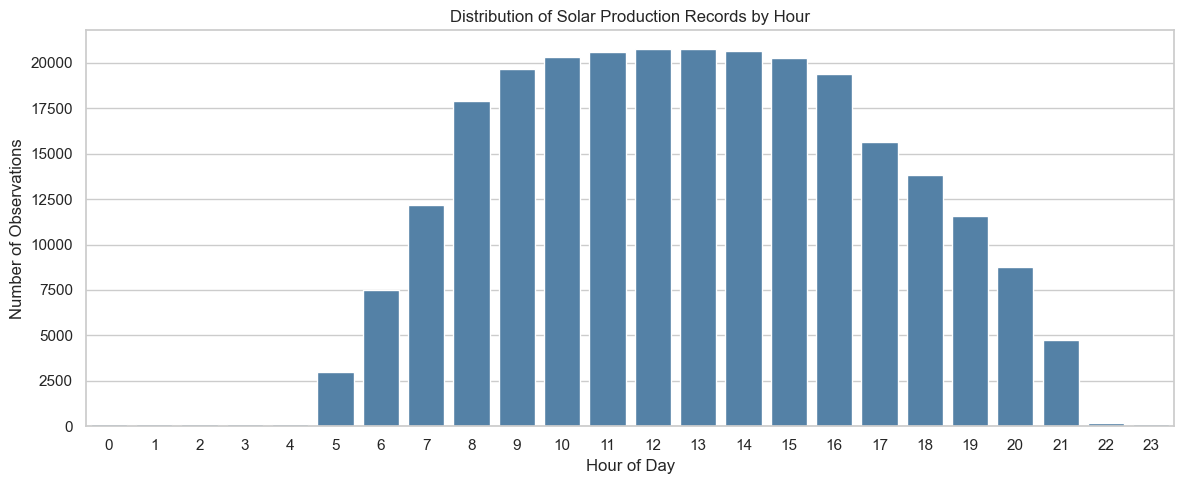

In [7]:

# Extract the hour from each production timestamp
df["hour"] = df["date"].dt.hour

# Count observations for each hour
hourly_counts = (
    df["hour"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

# Display the hourly observation counts
display(
    hourly_counts.rename("Number of observations").to_frame()
)

# Plot the distribution of observations by hour
plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_counts.index,
    y=hourly_counts.values,
    color="steelblue"
)

plt.title("Distribution of Solar Production Records by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Observations")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


### 3.6 Interpretation of Recording Hour Distribution

The distribution of recorded observations shows a
strong concentration during daylight hours.

Very few or no observations are available during
the early morning hours between midnight and 04:00.

The number of records increases from approximately
05:00 and reaches its highest concentration
between 10:00 and 15:00.

After approximately 16:00, the number of recorded
observations gradually decreases, with very few
records remaining after 21:00.

This pattern is consistent with the operating
characteristics of photovoltaic systems.

The results also provide a possible explanation
for the frequent overnight gaps identified during
the temporal consistency assessment.

However, this visualization represents observation
frequency rather than electricity generation.

Additional analysis of hourly energy production
is required to identify actual production peaks.

Unrecorded nighttime intervals will not
automatically be replaced with zero values.

### 3.7 Feature Engineering

Feature engineering involves creating new variables from
existing data to support analysis and visualization.

In this study, temporal features will be extracted from
the production timestamps, including the hour, day,
month, year, and season.

These features will help investigate daily and seasonal
variations in photovoltaic electricity generation.

In [8]:

# Create time-based features from production timestamps

df["hour"] = df["date"].dt.hour
df["day"] = df["date"].dt.day
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
df["day_of_week"] = df["date"].dt.dayofweek

# Assign meteorological seasons for Calgary
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["season"] = df["month"].apply(get_season)

# Inspect the newly created features
display(
    df[[
        "date", "hour", "day", "month",
        "year", "day_of_week", "season", "kWh"
    ]].head(10)
)

# Confirm the new DataFrame dimensions
print("Updated dataset shape:", df.shape)


,date,hour,day,month,year,day_of_week,season,kWh
23003,2015-09-01 14:30:00,14,1,9,2015,1,Autumn,27.805
23005,2015-09-01 15:30:00,15,1,9,2015,1,Autumn,30.559
23006,2015-09-01 16:30:00,16,1,9,2015,1,Autumn,23.613
23007,2015-09-01 17:30:00,17,1,9,2015,1,Autumn,15.257
23008,2015-09-01 18:30:00,18,1,9,2015,1,Autumn,7.896
23009,2015-09-01 19:30:00,19,1,9,2015,1,Autumn,1.885
23010,2015-09-01 20:30:00,20,1,9,2015,1,Autumn,41.066
23011,2015-09-01 21:30:00,21,1,9,2015,1,Autumn,57.844
23012,2015-09-01 22:30:00,22,1,9,2015,1,Autumn,48.606
23013,2015-09-01 23:30:00,23,1,9,2015,1,Autumn,31.482


Updated dataset shape: (258423, 15)


### 3.8 Timestamp Validation and Outlier Assessment

The initial temporal analysis revealed that some
photovoltaic installations recorded positive electricity
production during late-evening hours.

These observations require further investigation because
photovoltaic electricity generation generally depends
on the availability of solar radiation.

Potential explanations include timezone differences,
timestamp conventions, data aggregation methods,
or measurement anomalies.

This section examines production values across recording
hours and identifies potentially unusual values within
individual installations.

No observations will be removed or modified during this
assessment. Cleaning decisions will be based on the
results of the investigation.

In [9]:

# Investigate production readings recorded late in the evening

late_evening = df[df["hour"] >= 21].copy()

print("Number of late-evening observations:", len(late_evening))

print("\nLate-evening energy production summary:")
display(late_evening["kWh"].describe())

# Summarize late-evening readings by installation
late_evening_summary = (
    late_evening.groupby(["id", "name"])
    .agg(
        observations=("kWh", "size"),
        mean_kWh=("kWh", "mean"),
        max_kWh=("kWh", "max")
    )
    .reset_index()
)

display(late_evening_summary.round(2))

# Examine the distribution of observations by year
print("\nLate-evening observations by year:")
display(late_evening["year"].value_counts().sort_index())


Number of late-evening observations: 5026

Late-evening energy production summary:


count    5026.000000
mean        0.789056
std         3.337805
min         0.000000
25%         0.039000
50%         0.140000
75%         0.605750
max        66.249000
Name: kWh, dtype: float64

,id,name,observations,mean_kWh,max_kWh
0,164440,Southland Leisure Centre,652,2.27,66.25
1,308057,Hillhurst Sunnyside Community Association,398,0.10,0.92
2,314106,Calgary Fire Hall Headquarters,414,0.05,0.71
3,319086,Whitehorn Multi-Service Centre,525,1.53,21.04
4,331901,City of Calgary North Corporate Warehouse,512,0.42,3.80
5,332785,Richmond - Knob Hill Community Hall,455,0.04,0.38
6,355827,Glenmore Water Treatment Plant,655,0.68,6.95
7,551172,CFD Firehall #7,384,0.13,1.32
8,570079,Manchester Building M,375,0.11,1.01
9,577650,Bearspaw Water Treatment Plant,656,1.30,19.06



Late-evening observations by year:


year
2015     44
2016     86
2017    742
2018    964
2019    749
2020    812
2021    807
2022    822
Name: count, dtype: int64

#### Interpretation of Late-Evening Production Assessment

The analysis identified 5,026 observations recorded at
or after 21:00, representing approximately 1.94% of
the complete dataset.

Late-evening electricity production was generally low,
with a mean of approximately 0.789 kWh and a median
of 0.140 kWh.

However, the maximum recorded value reached
66.249 kWh, indicating that some observations were
substantially higher than typical late-evening readings.

The observations occurred across multiple photovoltaic
installations. Southland Leisure Centre recorded the
highest average late-evening production among the
installations examined, at approximately 2.27 kWh.

Late-evening observations were present across multiple
years between 2015 and 2022, with the highest count
occurring in 2018 (964 observations).

These findings indicate that late-evening readings are
not isolated to a single installation or year.

Possible explanations include timezone conventions,
measurement intervals, and seasonal daylight variations.

However, the dataset's timestamp conventions have not
yet been verified against the original documentation.

Consequently, these observations cannot be classified
as measurement errors based solely on their recording
hours.

The observations will be retained pending further
investigation.

### 3.9 Hourly Electricity Production Profile

The average electricity production for each recording
hour is calculated to examine the daily generation profile.

This analysis helps identify peak production periods
and investigate potentially unusual late-evening readings.

Because photovoltaic installations have different
capacities and recording coverage, the results represent
the average recorded production rather than a
capacity-normalized system performance measure.

,mean,median,count
hour,,,
0,1.43,0.27,125
1,0.54,0.23,125
2,0.42,0.16,114
3,0.35,0.23,110
4,0.33,0.22,107
5,0.23,0.06,3007
6,2.13,0.57,7486
7,7.40,1.76,12199
8,16.53,3.16,17916


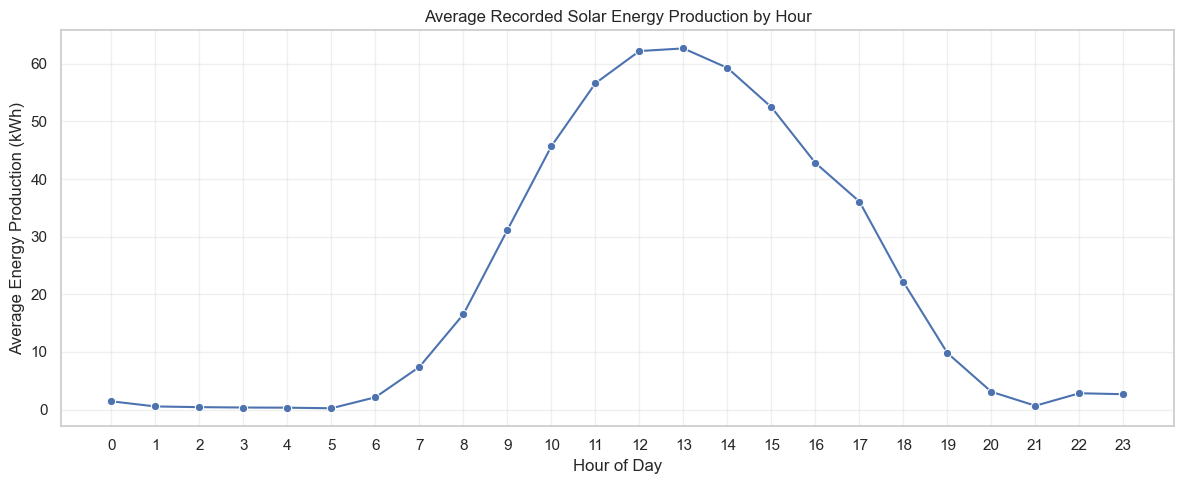

In [10]:

# Calculate average production by hour
hourly_production = (
    df.groupby("hour")["kWh"]
    .agg(["mean", "median", "count"])
    .reindex(range(24))
)

display(hourly_production.round(2))

# Visualize average recorded production
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_production,
    x=hourly_production.index,
    y="mean",
    marker="o"
)

plt.title("Average Recorded Solar Energy Production by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Production (kWh)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Interpretation of Hourly Electricity Production Profile

The hourly electricity production analysis reveals
a distinct daily generation pattern consistent with
the expected behavior of photovoltaic systems.

Average recorded production increases during the
morning, reaching its highest value of approximately
62.67 kWh at 13:00.

Production remains relatively high between 12:00
and 14:00 before declining during the afternoon
and evening.

This pattern is consistent with the influence of
solar irradiance on photovoltaic electricity generation.

The results also reveal substantial differences
between mean and median production values.

At 13:00, the mean is approximately 62.67 kWh,
while the median is 18.65 kWh.

This suggests a positively skewed distribution,
potentially reflecting differences in installation
sizes and production capacities.

Small positive production values are also observed
during late-night and early-morning hours.

These observations may be associated with timestamp
conventions, measurement intervals, or data anomalies
and require further investigation.

The analysis represents average recorded energy per
observation rather than capacity-normalized production.

Overall, the hourly production profile demonstrates
a strong diurnal pattern, with maximum average
recorded generation occurring around midday.

### 3.10 Installation-Specific Outlier Detection

The interquartile range (IQR) method is used to identify
potentially unusual energy production values.

Outlier thresholds are calculated separately for each
photovoltaic installation to account for differences
in production magnitude.

Observations outside the calculated thresholds will be
flagged for investigation rather than automatically removed.

The IQR method is an exploratory screening technique,
not definitive evidence of measurement error.

In [11]:

# Calculate installation-specific IQR thresholds

q1 = df.groupby("id")["kWh"].transform(
    lambda x: x.quantile(0.25)
)

q3 = df.groupby("id")["kWh"].transform(
    lambda x: x.quantile(0.75)
)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Flag potential outliers without removing them
df["potential_outlier"] = (
    (df["kWh"] < lower_bound) |
    (df["kWh"] > upper_bound)
)

# Summarize potential outliers by installation
outlier_summary = (
    df.groupby(["id", "name"])
    .agg(
        observations=("kWh", "size"),
        potential_outliers=("potential_outlier", "sum")
    )
    .reset_index()
)

outlier_summary["outlier_percentage"] = (
    outlier_summary["potential_outliers"]
    / outlier_summary["observations"] * 100
)

display(outlier_summary.round(2))

print(
    "Total potential outliers:",
    df["potential_outlier"].sum()
)


,id,name,observations,potential_outliers,outlier_percentage
0,164440,Southland Leisure Centre,31590,0,0.00
1,308057,Hillhurst Sunnyside Community Association,23467,0,0.00
2,314106,Calgary Fire Hall Headquarters,25637,0,0.00
3,319086,Whitehorn Multi-Service Centre,27716,0,0.00
4,331901,City of Calgary North Corporate Warehouse,27092,0,0.00
5,332785,Richmond - Knob Hill Community Hall,26623,0,0.00
6,355827,Glenmore Water Treatment Plant,25920,0,0.00
7,551172,CFD Firehall #7,22659,0,0.00
8,570079,Manchester Building M,22533,11,0.05
9,577650,Bearspaw Water Treatment Plant,24869,0,0.00


Total potential outliers: 25


#### Interpretation of Installation-Specific Outlier Detection

The installation-specific interquartile range (IQR)
method identified 25 potential outliers among
258,423 observations, representing approximately
0.0097% of the dataset.

Potential outliers were detected in only two of
the eleven photovoltaic installations.

Manchester Building M contained 11 flagged
observations out of 22,533 records, representing
approximately 0.05% of its observations.

Telus Spark contained 14 flagged observations
out of 317 records, representing approximately
4.42% of its observations.

The remaining nine installations contained no
observations outside their respective IQR thresholds.

The higher percentage of flagged observations at
Telus Spark may be influenced by its relatively
small sample size and limited recording period.

Although relatively few observations exceed the
calculated thresholds, statistical outliers do not
necessarily represent measurement errors.

Photovoltaic electricity generation is influenced
by solar irradiance, weather conditions, seasonal
variation, and installation characteristics.

Consequently, all 25 flagged observations will be
retained pending further investigation.

The original energy production values will remain
unchanged during this assessment.

### 3.11 Examination of Flagged Outlier Observations

The observations identified by the installation-specific
IQR method are examined individually to assess their
timestamps, production values, and installation origins.

This assessment supports informed decisions regarding
data retention and potential cleaning.

In [12]:

# Examine all flagged observations

flagged_observations = (
    df.loc[
        df["potential_outlier"],
        ["id", "name", "date", "kWh",
         "hour", "month", "season"]
    ]
    .sort_values(["id", "date"])
)

print("Number of flagged observations:",
      len(flagged_observations))

display(flagged_observations)

# Compare flagged readings with installation statistics
installation_stats = (
    df.groupby(["id", "name"])["kWh"]
    .agg(["min", "median", "mean", "max"])
    .round(2)
)

display(
    installation_stats.loc[
        installation_stats.index.get_level_values("id").isin(
            flagged_observations["id"].unique()
        )
    ]
)


Number of flagged observations: 25


,id,name,date,kWh,hour,month,season
47921,570079,Manchester Building M,2018-07-14 13:00:00,33.312,13,7,Summer
95101,570079,Manchester Building M,2019-05-02 13:00:00,33.288,13,5,Spring
157932,570079,Manchester Building M,2020-04-06 13:00:00,33.748,13,4,Spring
155624,570079,Manchester Building M,2020-04-13 13:00:00,33.685,13,4,Spring
144773,570079,Manchester Building M,2020-04-26 13:00:00,33.508,13,4,Spring
128412,570079,Manchester Building M,2020-05-14 12:00:00,33.225,12,5,Spring
128417,570079,Manchester Building M,2020-05-14 13:00:00,34.120,13,5,Spring
164938,570079,Manchester Building M,2020-06-16 13:00:00,33.979,13,6,Summer
157374,570079,Manchester Building M,2020-07-12 13:00:00,33.349,13,7,Summer
171651,570079,Manchester Building M,2021-06-07 14:00:00,33.732,14,6,Summer


,,min,median,mean,max
id,name,,,,
570079,Manchester Building M,0.0,4.50,8.13,34.12
594148,Telus Spark,0.0,3.54,4.21,23.88


#### Interpretation and Outlier Handling Decision

The examination of the 25 flagged observations
revealed that the potentially unusual readings
were concentrated in two photovoltaic installations:
Manchester Building M and Telus Spark.

For Manchester Building M, the 11 flagged observations
occurred between 12:00 and 14:00 during spring and
summer months. Their recorded energy values ranged
from approximately 33.23 to 34.12 kWh.

These observations may represent periods of relatively
high solar electricity generation.

For Telus Spark, the 14 flagged observations occurred
between 10:00 and 13:00 during November and December
2017. Their recorded values ranged from approximately
13.51 to 23.88 kWh.

The relatively small number of available observations
for this installation may affect the reliability of
its IQR thresholds.

Although these observations exceeded the
installation-specific statistical thresholds,
their occurrence during daytime hours provides
no immediate evidence of invalid measurements.

Therefore, all 25 flagged observations will be
retained for subsequent exploratory analysis.

The potential_outlier indicator will also be
preserved to support future sensitivity analysis.

This decision is provisional because installation
capacity information and original measurement
documentation have not yet been independently verified.

Overall, the outlier assessment demonstrates the
importance of considering temporal patterns and
installation-specific characteristics before
removing statistically unusual photovoltaic
production readings.

In [13]:

# Create a working copy for exploratory analysis

df_clean = df.copy()

# Retain all observations, including flagged outliers
print("Original observations:", len(df))
print("Working observations:", len(df_clean))

print(
    "Retained potential outliers:",
    df_clean["potential_outlier"].sum()
)

print("Working dataset shape:", df_clean.shape)


Original observations: 258423
Working observations: 258423
Retained potential outliers: 25
Working dataset shape: (258423, 16)


# 4. Exploratory Data Analysis (EDA)

This section investigates temporal variations and
installation-specific patterns in solar energy
production.

The analysis focuses on daily, monthly, seasonal,
and annual production trends, as well as differences
across photovoltaic installations.

The objective is to identify meaningful patterns,
understand production variability, and provide
insights into the factors influencing recorded
solar electricity generation.



### 4.1 Daily Solar Energy Production Trends

This subsection examines the daily variation in recorded solar
energy production across the photovoltaic installations.

Daily energy production is aggregated using the available
observations to identify temporal fluctuations and overall
production patterns.

Because recording intervals and data availability vary,
daily totals are interpreted as recorded energy rather than
necessarily complete daily generation.


In [14]:

# 4.1 Daily Solar Energy Production Trends

# Create a working copy for daily analysis
daily_df = df_clean.copy()

# Ensure production timestamps are datetime
daily_df["date"] = pd.to_datetime(daily_df["date"])

# Extract calendar date
daily_df["production_day"] = daily_df["date"].dt.date

# Aggregate recorded energy production by day
daily_production = (
    daily_df.groupby("production_day")["kWh"]
    .agg(["sum", "mean", "count"])
    .reset_index()
)

# Rename columns for clarity
daily_production.columns = [
    "date",
    "total_kWh",
    "mean_kWh",
    "observations"
]

# Convert date back to datetime
daily_production["date"] = pd.to_datetime(
    daily_production["date"]
)

# Display summary
print("Number of days:", len(daily_production))

print("\nDaily production summary:")
display(daily_production.describe())

print("\nFirst 10 daily records:")
display(daily_production.head(10))


Number of days: 2716

Daily production summary:


,date,total_kWh,mean_kWh,observations
count,2716,2716.000000,2716.000000,2716.000000
mean,2019-06-22 13:27:28.895434496,3621.324722,32.606365,95.148380
min,2015-09-01 00:00:00,0.000000,0.000000,1.000000
25%,2017-08-17 18:00:00,553.475500,11.718769,61.000000
50%,2019-06-27 12:00:00,2501.382500,33.295632,102.000000
75%,2021-05-06 06:00:00,6448.932250,51.922115,139.000000
max,2023-03-16 00:00:00,12530.798000,84.814803,171.000000
std,NaN,3356.465164,21.998459,50.964506



First 10 daily records:


,date,total_kWh,mean_kWh,observations
0,2015-09-01,286.013,28.601300,10
1,2015-09-02,681.646,32.459333,21
2,2015-09-03,647.906,30.852667,21
3,2015-09-04,102.448,5.122400,20
4,2015-09-05,93.432,4.917474,19
5,2015-09-06,367.626,18.381300,20
6,2015-09-07,574.996,30.262947,19
7,2015-09-08,489.814,24.490700,20
8,2015-09-09,732.002,36.600100,20
9,2015-09-10,628.674,33.088105,19


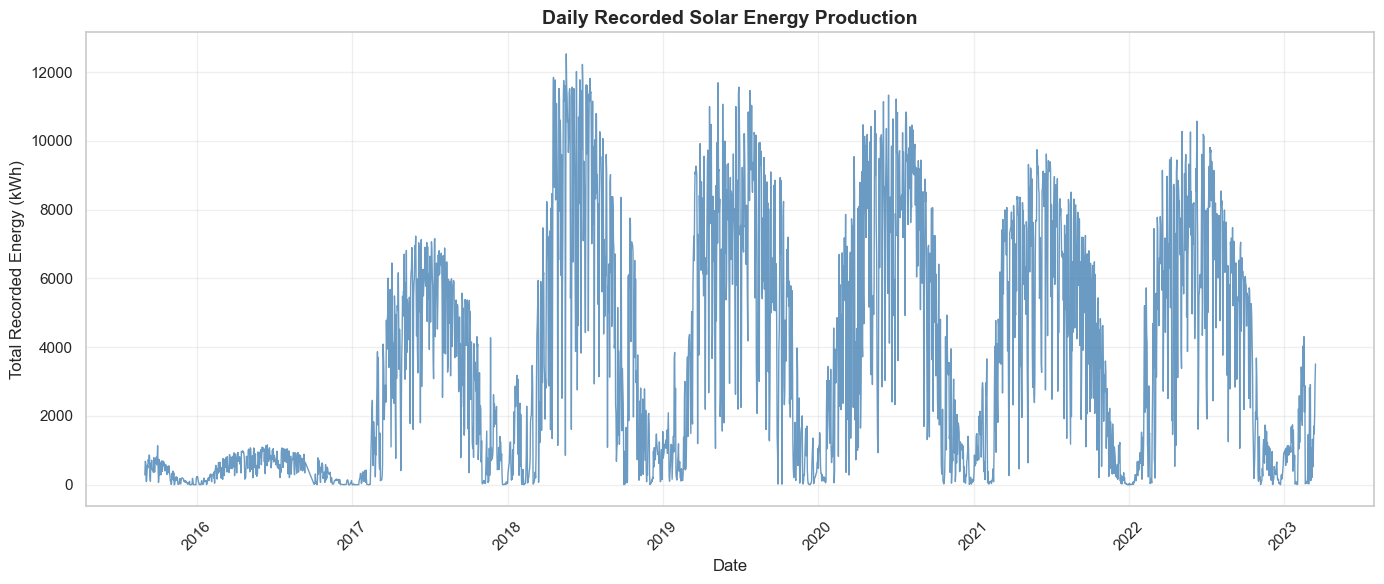

In [15]:

# Visualize daily recorded solar energy production

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    daily_production["date"],
    daily_production["total_kWh"],
    color="steelblue",
    linewidth=1,
    alpha=0.8
)

plt.title(
    "Daily Recorded Solar Energy Production",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Recorded Energy (kWh)")

plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


### 4.1.1 Interpretation of Daily Solar Energy Production Trends

The daily solar energy production analysis reveals substantial temporal variability in recorded photovoltaic electricity generation between September 2015 and March 2023.

The dataset contains 2,716 days with recorded observations, with an average daily recorded production of approximately 3,621.32 kWh and a maximum of 12,530.80 kWh.

**Key observations:**

1. **Seasonal variability:** The time-series visualization reveals recurring fluctuations in daily solar energy production. Higher recorded production generally occurs during periods consistent with increased seasonal solar availability, while lower values appear during other parts of the year.

2. **Interannual differences:** Recorded production is relatively low during 2015–2016 compared with subsequent years. These differences may partly reflect changes in the number of active or reporting photovoltaic installations rather than improvements in generation efficiency.

3. **Daily fluctuations:** Considerable variation occurs within individual seasons, potentially reflecting meteorological conditions, installation performance, and differences in data completeness.

4. **Production extremes:** The maximum daily recorded production reaches approximately 12,530.80 kWh, illustrating the considerable variation in aggregate recorded generation.

**Analytical limitation:**

Daily totals represent the sum of available recorded energy observations. Because the number of reporting installations and observations varies across days, these totals should not be interpreted as directly comparable measures of complete daily generation without additional coverage assessment.

**Conclusion:**

The analysis provides preliminary evidence of recurring temporal patterns in solar energy production. Further monthly and seasonal analyses are necessary to characterize these patterns and distinguish potential seasonal effects from differences in installation coverage.


## 4.2 Monthly Solar Energy Production Patterns

This subsection investigates monthly variations in recorded
solar energy production across the photovoltaic installations.

Monthly aggregation is used to examine recurring seasonal
patterns, differences in recorded production, and changes
in data availability.

Both total recorded energy and average energy per observation
are considered to avoid relying solely on aggregate totals
that may be affected by unequal reporting coverage.


In [16]:

# 4.2 Monthly Solar Energy Production Patterns

# Create a working copy
monthly_df = df_clean.copy()

# Ensure timestamps are datetime
monthly_df["date"] = pd.to_datetime(monthly_df["date"])

# Create monthly period
monthly_df["year_month"] = monthly_df["date"].dt.to_period("M")

# Aggregate production by calendar month
monthly_production = (
    monthly_df.groupby("year_month")["kWh"]
    .agg(["sum", "mean", "median", "count"])
    .reset_index()
)

# Rename columns
monthly_production.columns = [
    "year_month",
    "total_kWh",
    "mean_kWh",
    "median_kWh",
    "observations"
]

# Convert monthly period to timestamp for plotting
monthly_production["month_date"] = (
    monthly_production["year_month"].dt.to_timestamp()
)

print("Number of months with observations:",
      len(monthly_production))

print("\nMonthly production summary:")
display(monthly_production[
    ["total_kWh", "mean_kWh", "median_kWh", "observations"]
].describe().round(2))

print("\nFirst 10 monthly records:")
display(monthly_production.head(10))


Number of months with observations: 91

Monthly production summary:


,total_kWh,mean_kWh,median_kWh,observations
count,91.00,91.00,91.00,91.00
mean,108082.61,33.29,10.75,2839.81
std,89191.10,16.55,10.05,1539.82
min,1206.77,2.29,0.30,158.00
25%,22809.32,17.13,3.24,1933.50
50%,91759.39,39.98,10.10,2875.00
75%,186940.50,46.57,12.89,4139.00
max,283675.71,60.71,46.23,5063.00



First 10 monthly records:


,year_month,total_kWh,mean_kWh,median_kWh,observations,month_date
0,2015-09,15475.746,35.172150,27.3125,440,2015-09-01
1,2015-10,15068.149,41.510052,33.4330,363,2015-10-01
2,2015-11,4302.924,15.819574,8.5155,272,2015-11-01
3,2015-12,1722.964,7.939926,3.4200,217,2015-12-01
4,2016-01,3081.863,11.288875,4.2730,273,2016-01-01
5,2016-02,9544.109,32.910721,19.4835,290,2016-02-01
6,2016-03,18105.476,46.905378,38.7410,386,2016-03-01
7,2016-04,21241.109,48.942647,38.3265,434,2016-04-01
8,2016-05,22154.348,47.136911,40.2335,470,2016-05-01
9,2016-06,25612.561,50.319373,46.2340,509,2016-06-01


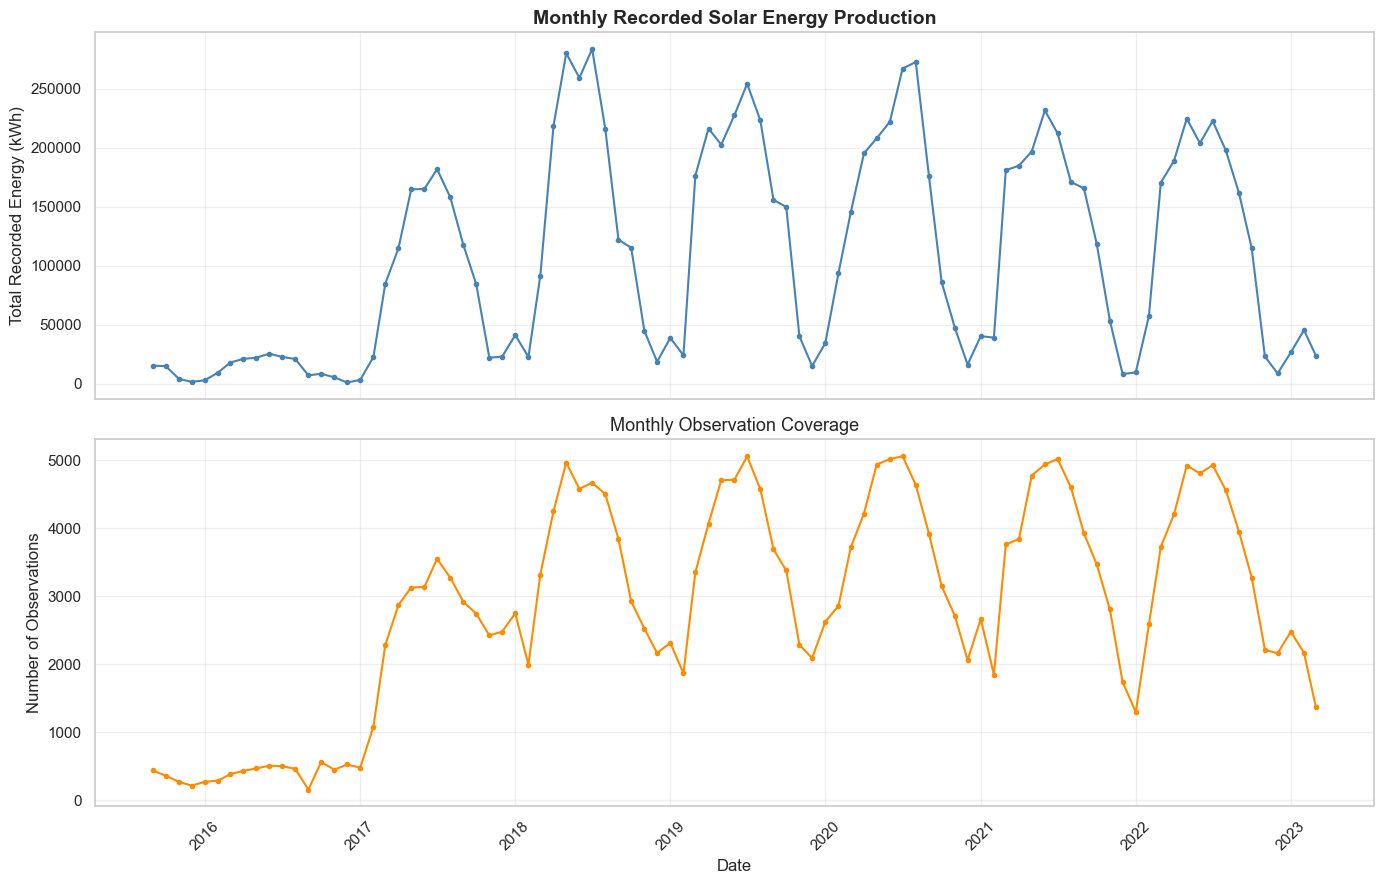

In [17]:

# Monthly recorded energy and observation coverage

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 1, figsize=(14, 9), sharex=True
)

# Monthly total recorded energy
axes[0].plot(
    monthly_production["month_date"],
    monthly_production["total_kWh"],
    color="steelblue",
    marker="o",
    markersize=3,
    linewidth=1.5
)

axes[0].set_title(
    "Monthly Recorded Solar Energy Production",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_ylabel("Total Recorded Energy (kWh)")
axes[0].grid(True, alpha=0.3)

# Monthly observation count
axes[1].plot(
    monthly_production["month_date"],
    monthly_production["observations"],
    color="darkorange",
    marker="o",
    markersize=3,
    linewidth=1.5
)

axes[1].set_title(
    "Monthly Observation Coverage",
    fontsize=13
)
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Number of Observations")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,mean,median,count
Jan,13.30,2.36,14894
Feb,21.46,2.66,14715
Mar,40.66,7.76,21937
Apr,47.69,11.62,23903
May,46.54,12.23,27920
Jun,48.17,12.87,27718
Jul,50.16,13.45,28804
Aug,47.31,12.92,26631
Sep,40.31,11.10,22864
Oct,34.88,7.58,19879


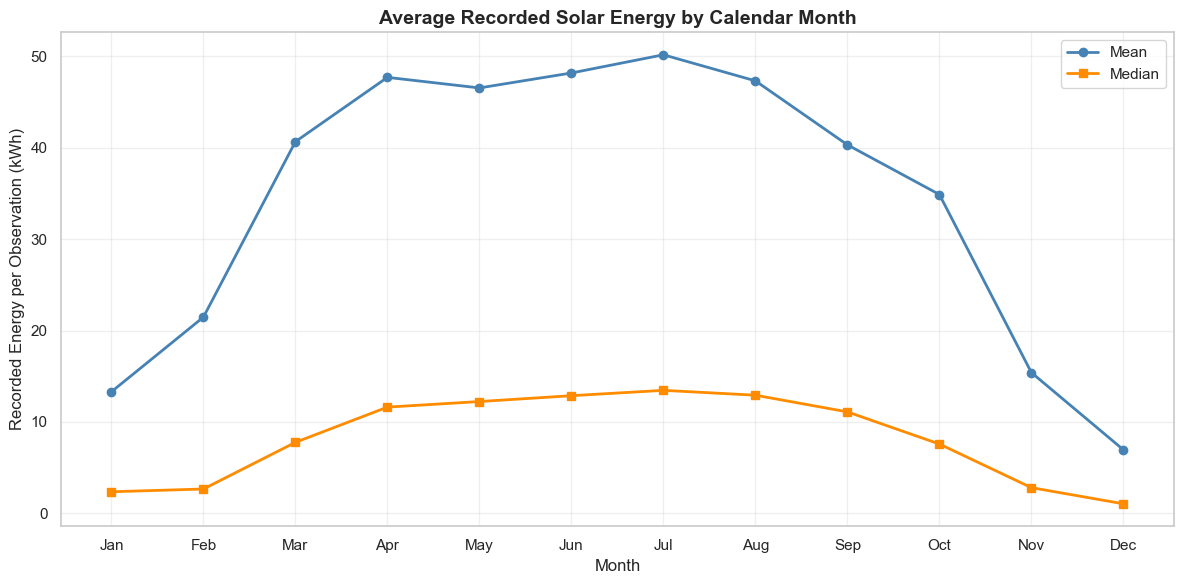

In [18]:

# Average recorded energy per observation by calendar month

monthly_pattern = (
    monthly_df.groupby(monthly_df["date"].dt.month)["kWh"]
    .agg(["mean", "median", "count"])
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly_pattern.index = month_names

display(monthly_pattern.round(2))

plt.figure(figsize=(12, 6))

plt.plot(
    month_names,
    monthly_pattern["mean"],
    marker="o",
    linewidth=2,
    color="steelblue",
    label="Mean"
)

plt.plot(
    month_names,
    monthly_pattern["median"],
    marker="s",
    linewidth=2,
    color="darkorange",
    label="Median"
)

plt.title(
    "Average Recorded Solar Energy by Calendar Month",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Month")
plt.ylabel("Recorded Energy per Observation (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 4.2.1 Interpretation of Monthly and Seasonal Solar Energy Production Patterns

The monthly analysis reveals a pronounced seasonal pattern in recorded solar energy production across the photovoltaic installations.

Both mean and median energy production generally increase from winter toward summer, reaching their highest values in July before declining toward December. July records the highest mean production of approximately **50.16 kWh per observation** and a median of **13.45 kWh**, while December records the lowest mean of **6.95 kWh** and a median of **1.04 kWh**.

This pattern is consistent with seasonal variations in solar energy availability, including changes in daylight duration and solar irradiance.

The mean consistently exceeds the median throughout the year, indicating a positively skewed distribution of recorded production values. This may reflect differences in installation capacities, operational characteristics, and the presence of relatively high production observations.

The monthly time-series analysis also demonstrates that total recorded energy closely follows observation coverage. Consequently, variations in monthly energy totals should not be interpreted solely as changes in physical solar generation, since differences in data availability can substantially influence aggregate production.

Overall, these findings demonstrate the importance of considering both seasonal patterns and observation coverage when interpreting photovoltaic energy production data. The results provide a foundation for further analysis of installation-specific performance and longer-term production trends.

## 4.3 Installation-Specific Solar Energy Production Analysis

### 4.3.1 Installation-Level Production Summary

This section examines variations in recorded solar energy
production across individual photovoltaic installations.
The analysis considers total production, average production,
median production, and observation coverage.

In [19]:
# Summarize solar energy production by installation

installation_summary = (
    df_clean.groupby(["id", "name"])
    .agg(
        observations=("kWh", "count"),
        total_kWh=("kWh", "sum"),
        mean_kWh=("kWh", "mean"),
        median_kWh=("kWh", "median"),
        max_kWh=("kWh", "max")
    )
    .reset_index()
)

# Sort installations by total recorded energy
installation_summary = installation_summary.sort_values(
    by="total_kWh",
    ascending=False
)

# Display results
print("Number of installations:", len(installation_summary))

display(installation_summary.round(2))

Number of installations: 11


,id,name,observations,total_kWh,mean_kWh,median_kWh,max_kWh
9,577650,Bearspaw Water Treatment Plant,24869,3082637.60,123.96,61.66,514.46
3,319086,Whitehorn Multi-Service Centre,27716,2558802.50,92.32,51.82,369.06
6,355827,Glenmore Water Treatment Plant,25920,1551177.72,59.84,32.76,239.97
0,164440,Southland Leisure Centre,31590,1147493.63,36.32,20.82,123.62
4,331901,City of Calgary North Corporate Warehouse,27092,768964.64,28.38,16.63,102.86
1,308057,Hillhurst Sunnyside Community Association,23467,186441.26,7.94,5.07,29.00
8,570079,Manchester Building M,22533,183243.24,8.13,4.50,34.12
7,551172,CFD Firehall #7,22659,170080.89,7.51,4.25,29.21
2,314106,Calgary Fire Hall Headquarters,25637,110211.61,4.30,2.48,16.60
5,332785,Richmond - Knob Hill Community Hall,26623,75130.28,2.82,1.90,9.28


### 4.3.2 Comparison of Total and Average Energy Production

The following visualizations compare total recorded energy
and mean energy per observation across photovoltaic installations.

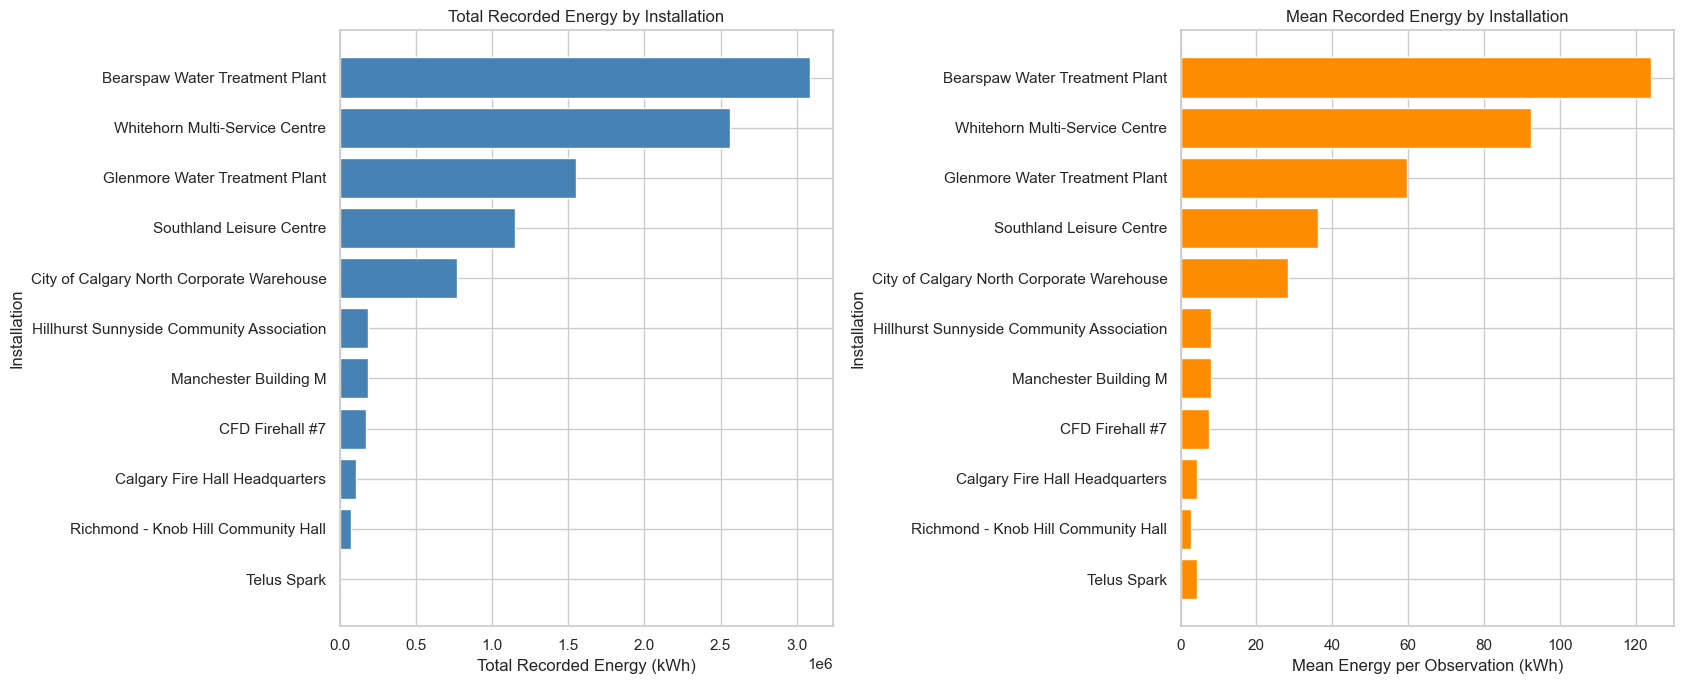

In [20]:

import matplotlib.pyplot as plt

# Sort installations by total recorded energy
plot_data = installation_summary.sort_values(
    "total_kWh", ascending=True
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Chart 1: Total recorded energy
axes[0].barh(
    plot_data["name"],
    plot_data["total_kWh"],
    color="steelblue"
)
axes[0].set_title("Total Recorded Energy by Installation")
axes[0].set_xlabel("Total Recorded Energy (kWh)")
axes[0].set_ylabel("Installation")

# Chart 2: Mean recorded energy
axes[1].barh(
    plot_data["name"],
    plot_data["mean_kWh"],
    color="darkorange"
)
axes[1].set_title("Mean Recorded Energy by Installation")
axes[1].set_xlabel("Mean Energy per Observation (kWh)")
axes[1].set_ylabel("Installation")

plt.tight_layout()
plt.show()



**Interpretation**

The installation-level comparison reveals substantial differences
in recorded solar energy production across the 11 photovoltaic
installations.

Bearspaw Water Treatment Plant records the highest total and
mean energy production, followed by Whitehorn Multi-Service
Centre and Glenmore Water Treatment Plant.

The similar rankings of total and mean production suggest
that differences in average recorded energy contribute
substantially to the variation in cumulative production.

However, total production is also influenced by the number
of available observations. Telus Spark, for example, has
considerably fewer observations than the other installations.

Consequently, these comparisons describe recorded energy
production rather than installation efficiency. Differences
in installed capacity, observation coverage, and operating
conditions must be considered before drawing conclusions
about relative system performance.


### 4.3.3 Observation Coverage by Installation

This analysis examines the distribution of recorded observations
across photovoltaic installations to identify differences in
data availability that may influence production comparisons.

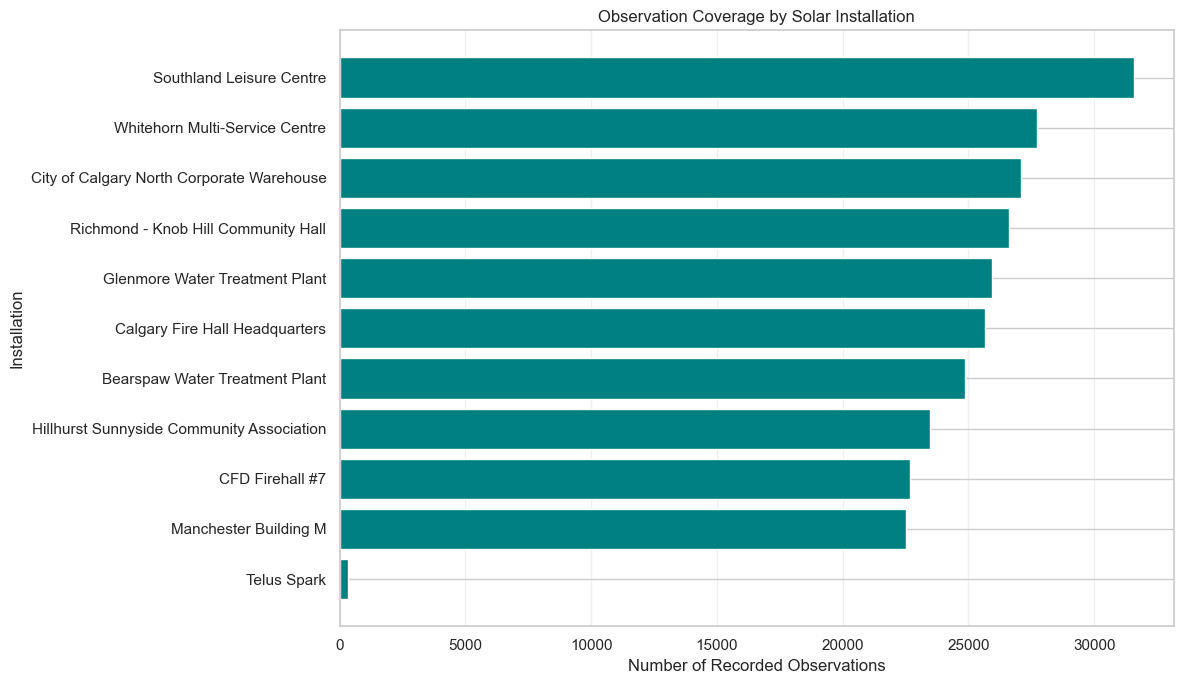

Observation coverage summary:


,name,observations
0,Southland Leisure Centre,31590
3,Whitehorn Multi-Service Centre,27716
4,City of Calgary North Corporate Warehouse,27092
5,Richmond - Knob Hill Community Hall,26623
6,Glenmore Water Treatment Plant,25920
2,Calgary Fire Hall Headquarters,25637
9,Bearspaw Water Treatment Plant,24869
1,Hillhurst Sunnyside Community Association,23467
7,CFD Firehall #7,22659
8,Manchester Building M,22533


In [21]:

# Examine observation coverage across installations

coverage = installation_summary.sort_values(
    "observations", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    coverage["name"],
    coverage["observations"],
    color="teal"
)

plt.title("Observation Coverage by Solar Installation")
plt.xlabel("Number of Recorded Observations")
plt.ylabel("Installation")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Display numerical summary
print("Observation coverage summary:")
display(
    installation_summary[
        ["name", "observations"]
    ].sort_values("observations", ascending=False)
)



**Interpretation**

The observation coverage analysis reveals differences in the
number of recorded measurements across the 11 photovoltaic
installations.

Southland Leisure Centre has the highest number of recorded
observations (31,590), while Manchester Building M has the
lowest count (22,533) among the 10 installations with
substantial observation coverage.

Telus Spark is a notable exception, contributing only 317
observations.

These differences are important because installations with
more recorded observations may accumulate greater total
energy values simply because they have more measurements.

Consequently, cumulative energy production should not be
used alone to compare installation performance.

Mean energy per observation provides an additional basis
for comparison, although differences in system capacity,
measurement frequency, and operating conditions must also
be considered.

The limited observations for Telus Spark suggest that its
results should be interpreted cautiously in subsequent
analyses.



### 4.3.4 Installation-Level Production Variability

This section examines the variability of recorded solar energy
production across photovoltaic installations using the standard
deviation and coefficient of variation (CV).

The coefficient of variation expresses standard deviation
relative to the mean, allowing differences in variability
to be compared across installations with different average
production levels.


Installation-level production variability:


,id,name,observations,mean_kWh,std_kWh,cv_percent
9,577650,Bearspaw Water Treatment Plant,24869,123.96,138.93,112.08
6,355827,Glenmore Water Treatment Plant,25920,59.84,64.48,107.74
8,570079,Manchester Building M,22533,8.13,8.74,107.41
3,319086,Whitehorn Multi-Service Centre,27716,92.32,96.60,104.63
0,164440,Southland Leisure Centre,31590,36.32,37.76,103.95
7,551172,CFD Firehall #7,22659,7.51,7.78,103.68
2,314106,Calgary Fire Hall Headquarters,25637,4.30,4.45,103.49
4,331901,City of Calgary North Corporate Warehouse,27092,28.38,29.07,102.41
10,594148,Telus Spark,317,4.21,4.22,100.28
1,308057,Hillhurst Sunnyside Community Association,23467,7.94,7.80,98.21


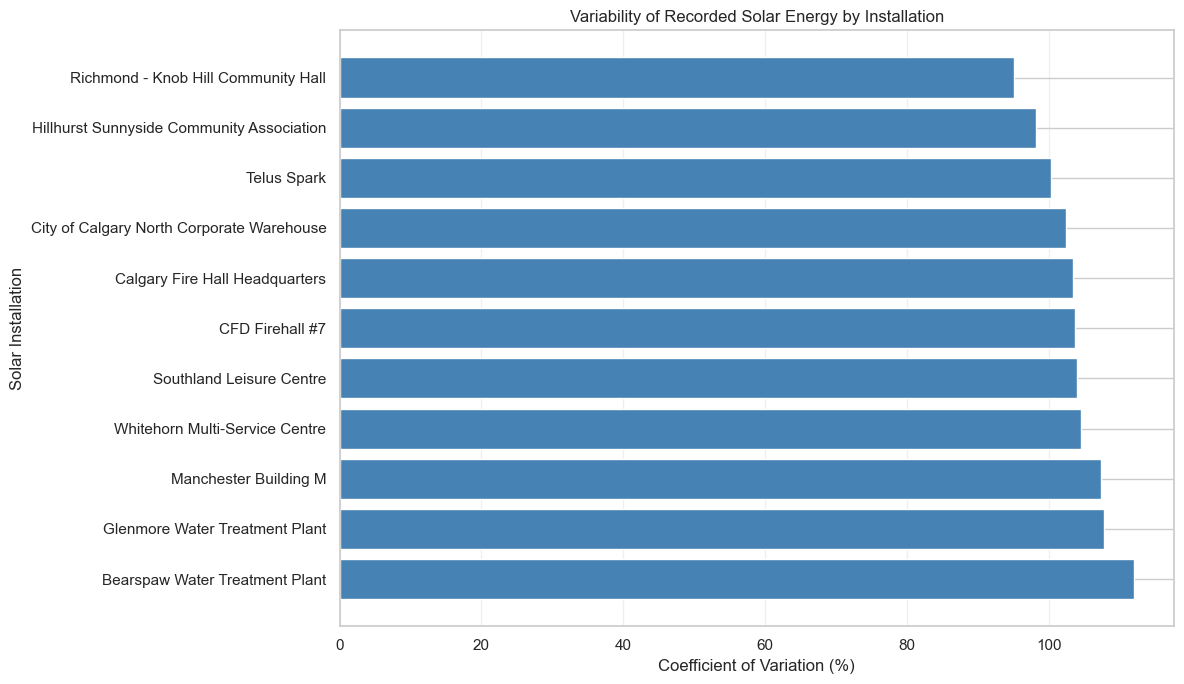

In [22]:

# Calculate installation-level production variability

installation_variability = (
    df_clean.groupby(["id", "name"])["kWh"]
    .agg(
        observations="count",
        mean_kWh="mean",
        std_kWh="std"
    )
    .reset_index()
)

# Calculate coefficient of variation (%)
installation_variability["cv_percent"] = (
    installation_variability["std_kWh"]
    / installation_variability["mean_kWh"]
) * 100

# Sort by coefficient of variation
installation_variability = (
    installation_variability.sort_values(
        "cv_percent", ascending=False
    )
)

print("Installation-level production variability:")
display(installation_variability.round(2))

# Visualize coefficient of variation
plt.figure(figsize=(12, 7))

plt.barh(
    installation_variability["name"],
    installation_variability["cv_percent"],
    color="steelblue"
)

plt.title(
    "Variability of Recorded Solar Energy by Installation"
)
plt.xlabel("Coefficient of Variation (%)")
plt.ylabel("Solar Installation")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation**

The installation-level variability analysis reveals substantial
variation in recorded photovoltaic energy production across
all 11 installations.

The coefficient of variation ranges from 95.12% to 112.08%,
indicating that the standard deviation is approximately equal
to or greater than the mean recorded production for most
installations.

Bearspaw Water Treatment Plant exhibits the highest relative
variability (112.08%), followed by Glenmore Water Treatment
Plant (107.74%) and Manchester Building M (107.41%).

Richmond - Knob Hill Community Hall exhibits the lowest
coefficient of variation (95.12%).

These findings are consistent with the highly variable nature
of solar energy production, which depends on daylight
availability, seasonal changes, weather conditions, and
installation characteristics.

Importantly, the analysis includes observations from different
hours and seasons. Consequently, high variability should not
be interpreted as evidence of poor system reliability or
inefficiency.

Further analysis that accounts for temporal patterns would
be required to evaluate operational consistency.



## 4.4 Year-over-Year Solar Energy Production Analysis

This section investigates annual trends in recorded photovoltaic
energy production across the study period.

The analysis examines annual total production, average and
median production per observation, and observation coverage.

Because the number of available observations varies across
years, changes in total recorded energy are interpreted
alongside changes in data availability.


In [23]:

# Section 4.4.1 - Annual Solar Energy Production Summary

# Aggregate solar energy production by year
annual_production = (
    df_clean.groupby("year")["kWh"]
    .agg(
        total_kWh="sum",
        mean_kWh="mean",
        median_kWh="median",
        observations="count"
    )
    .reset_index()
    .sort_values("year")
)

# Display the annual production summary
print("Annual Solar Energy Production Summary:")
display(annual_production.round(2))

# Check the number of years covered
print(
    "\nNumber of years:",
    annual_production["year"].nunique()
)

# Check the total number of observations
print(
    "Total observations:",
    annual_production["observations"].sum()
)


Annual Solar Energy Production Summary:


,year,total_kWh,mean_kWh,median_kWh,observations
0,2015,36569.78,28.30,15.37,1292
1,2016,166261.72,33.05,15.73,5030
2,2017,1143066.05,37.60,7.76,30397
3,2018,1714572.43,40.33,7.28,42516
4,2019,1725008.98,40.94,8.03,42132
5,2020,1765072.18,39.27,8.29,44943
6,2021,1603814.99,36.93,8.81,43430
7,2022,1584847.50,37.16,8.31,42655
8,2023,96304.30,15.98,2.93,6028



Number of years: 9
Total observations: 258423



**Interpretation**

The annual solar energy production summary covers nine calendar
years (2015–2023), comprising 258,423 recorded observations.

Total recorded energy production increased substantially between
2015 and 2020, reaching its highest annual value of approximately
1.77 million kWh in 2020.

However, the number of observations also increased significantly
over this period. The highest annual observation count (44,943)
was recorded in 2020.

Mean energy production per observation reached its highest value
of 40.94 kWh in 2019, compared with 39.27 kWh in 2020.

Total recorded production subsequently decreased in 2021 and
2022, while mean production remained relatively close to
the levels observed during 2017–2020.

The dataset includes partial coverage of 2015 and 2023.
Consequently, the lower totals for these years should not
be interpreted as evidence of reduced photovoltaic performance.

Overall, annual production trends must be considered alongside
observation coverage and changes in the installations represented
in the dataset.



### 4.4.2 Visualization of Annual Solar Energy Production Trends

This section visualizes annual total recorded solar energy,
mean energy production per observation, and observation coverage.

The three indicators are examined together to distinguish
changes in recorded energy production from differences in
the availability of measurements.


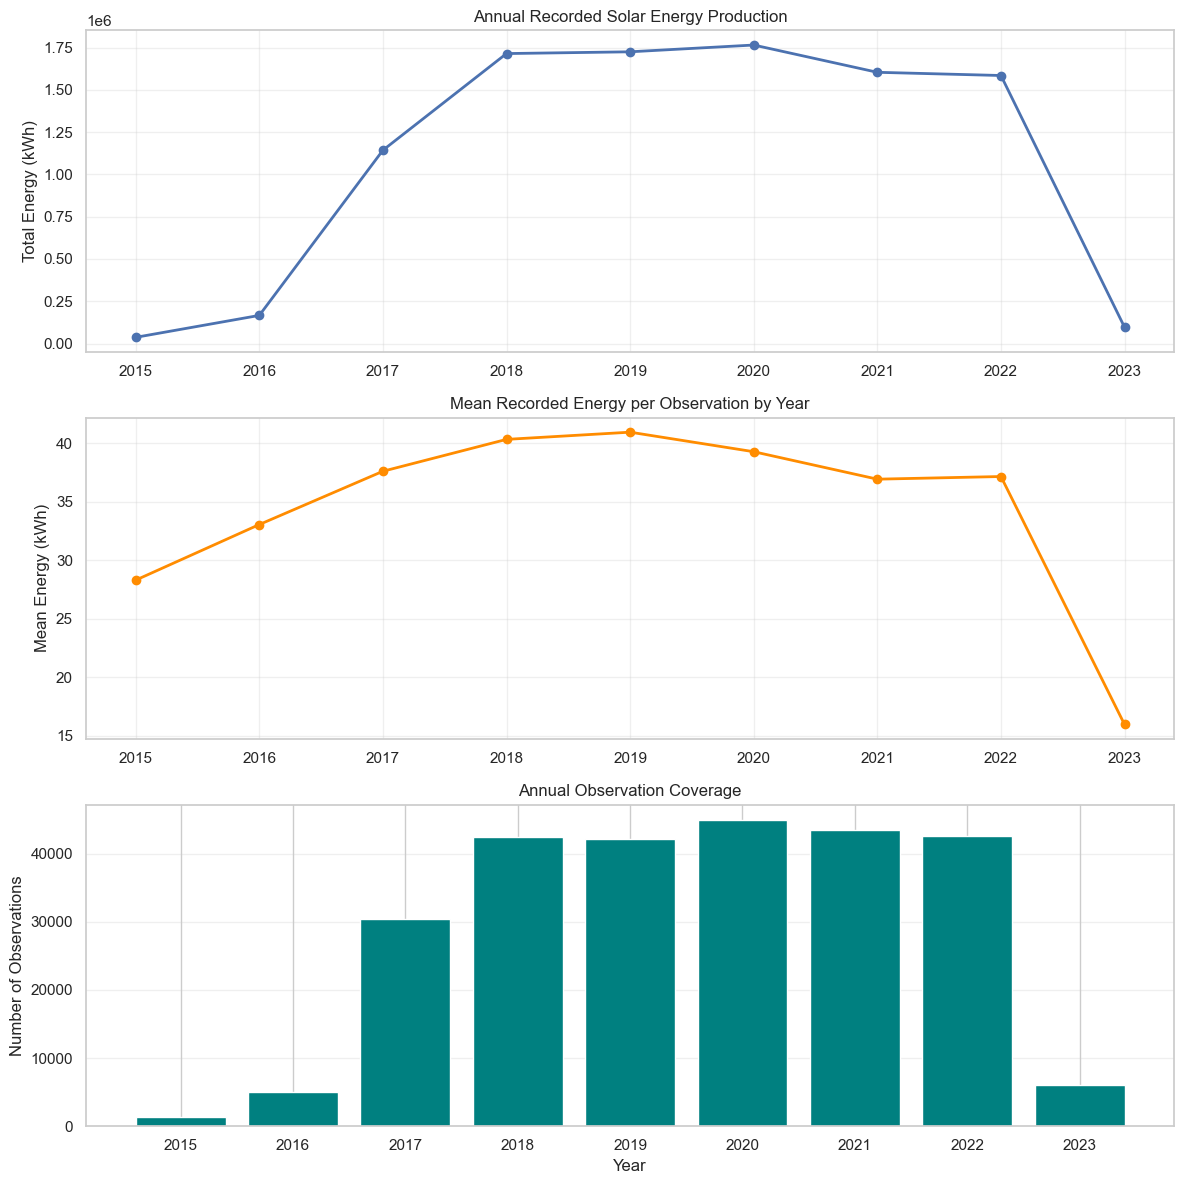

In [24]:

# Visualize annual solar energy production trends

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

# Chart 1: Total annual production
axes[0].plot(
    annual_production["year"],
    annual_production["total_kWh"],
    marker="o",
    linewidth=2
)
axes[0].set_title("Annual Recorded Solar Energy Production")
axes[0].set_ylabel("Total Energy (kWh)")
axes[0].grid(alpha=0.3)

# Chart 2: Mean energy per observation
axes[1].plot(
    annual_production["year"],
    annual_production["mean_kWh"],
    marker="o",
    color="darkorange",
    linewidth=2
)
axes[1].set_title("Mean Recorded Energy per Observation by Year")
axes[1].set_ylabel("Mean Energy (kWh)")
axes[1].grid(alpha=0.3)

# Chart 3: Annual observation coverage
axes[2].bar(
    annual_production["year"],
    annual_production["observations"],
    color="teal"
)
axes[2].set_title("Annual Observation Coverage")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Number of Observations")
axes[2].grid(axis="y", alpha=0.3)

# Display all years
for ax in axes:
    ax.set_xticks(annual_production["year"])

plt.tight_layout()
plt.show()



**Interpretation of Annual Production Trends**

The annual visualizations reveal substantial changes in recorded
solar energy production and observation coverage between 2015
and 2023.

Total recorded energy production increased significantly from
2015 to 2018, reaching approximately 1.71 million kWh in 2018.
Production remained relatively stable through 2020, when the
highest annual total of approximately 1.77 million kWh was
recorded.

Mean recorded energy per observation followed a similar upward
trend during the earlier years, reaching a maximum of 40.94 kWh
in 2019. Between 2020 and 2022, mean production remained
relatively stable, ranging from approximately 36.93 to
39.27 kWh.

Observation coverage increased substantially between 2015
and 2018, indicating that part of the growth in recorded
production may be associated with improved data availability
or changes in the installations represented.

Annual observation counts were more consistent between 2018
and 2022, making this period more suitable for comparisons,
although differences in installation composition and
measurement frequency must still be considered.

The sharp decreases observed in 2023 should be interpreted
cautiously because the dataset contains only partial-year
observations.

Overall, the findings demonstrate that recorded solar energy
production is influenced by both energy generation patterns
and observation coverage. Consequently, annual totals alone
are insufficient for assessing photovoltaic performance.



### 4.4.3 Year-over-Year Changes in Solar Energy Production

This section evaluates year-over-year percentage changes in
total recorded solar energy production, mean energy per
observation, and observation coverage.

The objective is to quantify annual variations and examine
whether changes in recorded energy production coincide with
changes in the number of available observations.


In [25]:

# Calculate year-over-year changes in solar energy production

annual_changes = annual_production.copy()

# Calculate annual percentage changes
annual_changes["total_change_pct"] = (
    annual_changes["total_kWh"].pct_change() * 100
)

annual_changes["mean_change_pct"] = (
    annual_changes["mean_kWh"].pct_change() * 100
)

annual_changes["observations_change_pct"] = (
    annual_changes["observations"].pct_change() * 100
)

# Display annual percentage changes
columns = [
    "year",
    "total_change_pct",
    "mean_change_pct",
    "observations_change_pct"
]

print("Year-over-Year Solar Energy Production Changes:")

display(annual_changes[columns].round(2))


Year-over-Year Solar Energy Production Changes:


,year,total_change_pct,mean_change_pct,observations_change_pct
0,2015,NaN,NaN,NaN
1,2016,354.64,16.78,289.32
2,2017,587.51,13.77,504.31
3,2018,50.00,7.24,39.87
4,2019,0.61,1.53,-0.90
5,2020,2.32,-4.08,6.67
6,2021,-9.14,-5.97,-3.37
7,2022,-1.18,0.61,-1.78
8,2023,-93.92,-57.00,-85.87



**Interpretation of Year-over-Year Production Changes**

The year-over-year analysis reveals substantial variations in
recorded solar energy production between 2016 and 2023.

Between 2016 and 2018, total recorded energy increased
considerably, with annual growth rates of 354.64%, 587.51%,
and 50.00%, respectively. These increases coincided with
significant improvements in observation coverage, suggesting
that data availability contributed to the recorded growth.

From 2019 to 2022, annual changes became comparatively
moderate. In 2020, total recorded production increased by
2.32%, despite a 4.08% decrease in mean energy per
observation. This difference coincided with a 6.67%
increase in observation coverage.

In 2021, total recorded production decreased by 9.14%,
accompanied by decreases in both mean energy per
observation (-5.97%) and observation coverage (-3.37%).

In 2022, total recorded production decreased slightly
by 1.18%, while mean energy per observation increased
by 0.61%.

The substantial declines observed in 2023 should not
be interpreted as evidence of deteriorating photovoltaic
performance because the dataset contains only partial-year
observations.

Overall, the results demonstrate that annual changes in
recorded energy production reflect variations in both
energy generation per observation and observation coverage.
Consequently, changes in total recorded production should
not automatically be interpreted as changes in solar
installation efficiency.


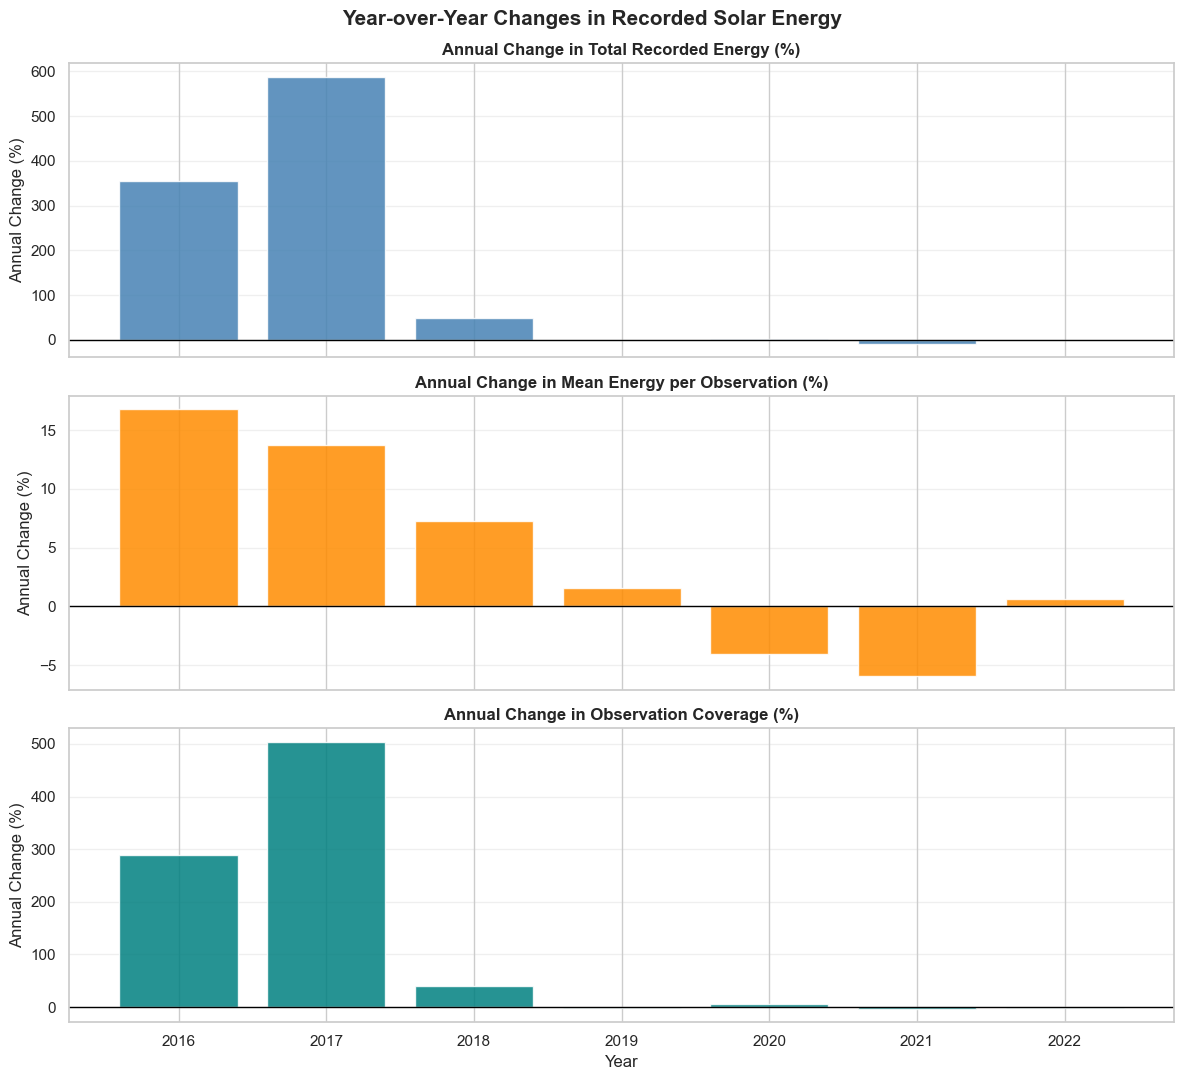

In [26]:

# Visualize year-over-year solar energy production changes

import matplotlib.pyplot as plt

# Exclude 2015 (no previous year) and 2023 (partial year)
plot_data = annual_changes[
    annual_changes["year"].between(2016, 2022)
].copy()

fig, axes = plt.subplots(
    3, 1, figsize=(12, 11), sharex=True
)

metrics = [
    ("total_change_pct",
     "Annual Change in Total Recorded Energy (%)",
     "steelblue"),
    ("mean_change_pct",
     "Annual Change in Mean Energy per Observation (%)",
     "darkorange"),
    ("observations_change_pct",
     "Annual Change in Observation Coverage (%)",
     "teal")
]

for ax, (column, title, color) in zip(axes, metrics):
    ax.bar(
        plot_data["year"],
        plot_data[column],
        color=color,
        alpha=0.85
    )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Annual Change (%)")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(plot_data["year"])

plt.suptitle(
    "Year-over-Year Changes in Recorded Solar Energy",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



**Interpretation of Year-over-Year Changes**

The year-over-year visualizations demonstrate a strong
relationship between changes in total recorded solar energy
production and changes in observation coverage.

The largest increases in total recorded production occurred
in 2016 and 2017, coinciding with substantial increases in
the number of observations. This suggests that expanded
data coverage contributed significantly to the recorded
growth.

From 2019 to 2022, annual changes were considerably smaller,
reflecting a period of more stable observation coverage.

Mean energy per observation increased during the earlier
years but declined in 2020 and 2021 before recovering
slightly in 2022.

These findings highlight the importance of distinguishing
between changes in recorded energy production and changes
in data availability.

Because total recorded energy is mathematically dependent
on both mean energy per observation and observation count,
annual production totals should not be interpreted as
direct measures of photovoltaic efficiency.

Overall, the analysis provides a foundation for further
investigation of installation-level performance and
temporal variations in solar energy production.



## 4.5 Data-Quality and Coverage-Adjusted Comparisons

### 4.5.1 Annual Observation Coverage by Installation

This subsection examines the distribution of recorded
observations across photovoltaic installations and years.

The objective is to identify differences in data availability,
uneven reporting periods, and potential coverage-related
biases that may influence comparisons of solar energy production.

Observation counts are analyzed to assess whether additional
resampling or coverage adjustments are necessary.


Annual Observation Coverage by Installation:


year,2015,2016,2017,2018,2019,2020,2021,2022,2023
name,,,,,,,,,
Bearspaw Water Treatment Plant,0,0,817,5149,4542,4645,4607,4356,753
CFD Firehall #7,0,0,816,3945,4054,4475,4440,4303,626
Calgary Fire Hall Headquarters,0,4,3398,4208,4303,4444,4349,4256,675
City of Calgary North Corporate Warehouse,0,51,4213,4363,4415,4569,4532,4292,657
Glenmore Water Treatment Plant,0,0,4123,4171,4010,4470,4237,4381,528
Hillhurst Sunnyside Community Association,0,618,3528,3839,3230,4367,3915,3594,376
Manchester Building M,0,0,437,3747,4456,4529,4483,4241,640
Richmond - Knob Hill Community Hall,0,113,4194,4283,4274,4410,4383,4363,603
Southland Leisure Centre,1292,4244,4339,4239,4333,4390,3886,4402,465


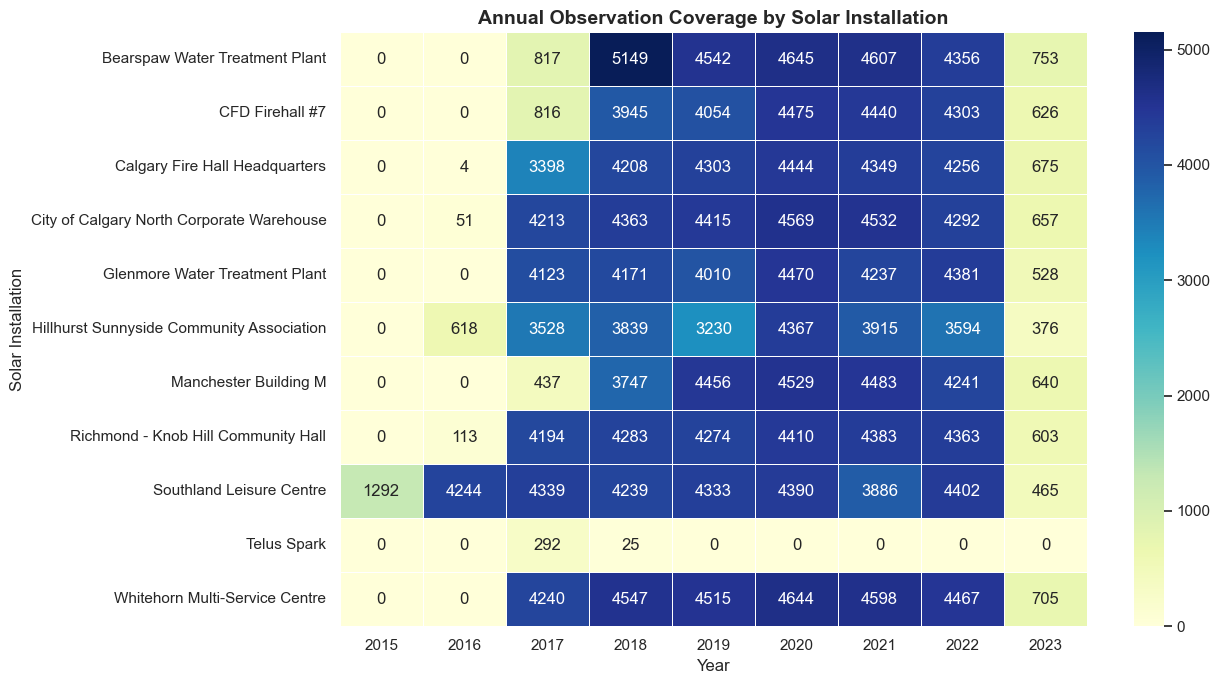

In [27]:

# Section 4.5.1 - Annual Observation Coverage by Installation

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Work with the cleaned dataset
coverage_df = df_clean.copy()

# Ensure the date column is in datetime format
coverage_df["date"] = pd.to_datetime(coverage_df["date"])

# Extract the calendar year
coverage_df["year"] = coverage_df["date"].dt.year

# Count observations for each installation and year
annual_installation_coverage = (
    coverage_df.groupby(["name", "year"])
    .size()
    .unstack(fill_value=0)
)

# Display the coverage table
print("Annual Observation Coverage by Installation:")
display(annual_installation_coverage)

# Create a heatmap of observation counts
plt.figure(figsize=(13, 7))

sns.heatmap(
    annual_installation_coverage,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title(
    "Annual Observation Coverage by Solar Installation",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Solar Installation")

plt.tight_layout()
plt.show()


### Interpretation — Annual Observation Coverage by Installation

The annual observation coverage analysis reveals substantial differences in data availability across photovoltaic installations and years.

**Key findings:**

1. **Limited early-year coverage:** Most installations have few or no recorded observations during 2015–2016, suggesting staggered reporting availability or different installation start dates.

2. **More consistent reporting during 2018–2022:** Most installations show several thousand observations annually during this period, making these years more suitable for comparative analysis, subject to further completeness checks.

3. **Limited Telus Spark coverage:** Telus Spark has only 292 observations in 2017 and 25 in 2018, with no subsequent records. This installation requires special consideration in comparative analyses.

4. **Substantial reduction in 2023 observations:** Most installations show a pronounced decline in observation counts in 2023. This may indicate a partial reporting year rather than an actual decline in solar electricity production.

5. **Variation between installations:** Differences in observation counts may reflect reporting frequency, missing measurements, installation commissioning dates, or other operational factors.

**Implications for energy analysis and forecasting:**

Uneven observation coverage can bias comparisons of total recorded energy production across installations and years. Periods with fewer observations may show lower recorded totals even when actual generation performance has not deteriorated.

Therefore, further analysis is required to identify missing timestamps, assess expected reporting frequency, and distinguish incomplete coverage from genuine differences in solar energy production.

The 2018–2022 period appears promising for further comparative analysis and potential forecasting, but its suitability must be confirmed through additional data-quality checks.

### 4.5.2 Reporting Frequency and Missing-Period Assessment

This subsection investigates the temporal consistency of recorded solar energy production observations across installations.

The objectives are to:

- Determine the first and last available timestamps for each installation.
- Examine the time intervals between consecutive observations.
- Identify unusually long gaps in the recorded data.
- Assess whether the dataset follows a consistent reporting frequency.

Understanding reporting frequency and missing periods is necessary before calculating observation coverage percentages, performing time-based resampling, or preparing the dataset for future energy production forecasting.

In [28]:

# Section 4.5.2 - Reporting Frequency and Missing-Period Assessment

import pandas as pd

# Create a working copy of the cleaned dataset
frequency_df = df_clean.copy()

# Ensure timestamps are in datetime format
frequency_df["date"] = pd.to_datetime(
    frequency_df["date"],
    errors="coerce"
)

# Remove rows with invalid timestamps
frequency_df = frequency_df.dropna(subset=["date"])

# Sort observations by installation and timestamp
frequency_df = frequency_df.sort_values(["name", "date"])

# Calculate the time difference between consecutive observations
# within each installation
frequency_df["time_gap_hours"] = (
    frequency_df.groupby("name")["date"]
    .diff()
    .dt.total_seconds()
    / 3600
)

# Summarize reporting intervals for each installation
reporting_summary = (
    frequency_df.groupby("name")
    .agg(
        first_record=("date", "min"),
        last_record=("date", "max"),
        observations=("date", "size"),
        median_gap_hours=("time_gap_hours", "median"),
        max_gap_hours=("time_gap_hours", "max"),
        gaps_over_24h=("time_gap_hours", lambda x: (x > 24).sum())
    )
    .reset_index()
)

# Round numerical reporting intervals
reporting_summary["median_gap_hours"] = (
    reporting_summary["median_gap_hours"].round(2)
)

reporting_summary["max_gap_hours"] = (
    reporting_summary["max_gap_hours"].round(2)
)

print("Reporting Frequency and Missing-Period Summary:")
display(reporting_summary)


Reporting Frequency and Missing-Period Summary:


,name,first_record,last_record,observations,median_gap_hours,max_gap_hours,gaps_over_24h
0,Bearspaw Water Treatment Plant,2017-11-21 10:45:00,2023-03-16 19:00:00,24869,1.0,762.0,6
1,CFD Firehall #7,2017-09-21 07:00:00,2023-03-16 19:00:00,22659,1.0,978.0,20
2,Calgary Fire Hall Headquarters,2016-11-24 14:00:00,2023-03-16 19:00:00,25637,1.0,2015.0,28
3,City of Calgary North Corporate Warehouse,2016-12-23 09:30:00,2023-03-16 19:00:00,27092,1.0,788.0,16
4,Glenmore Water Treatment Plant,2017-03-08 10:00:00,2023-03-12 17:00:00,25920,1.0,718.0,36
5,Hillhurst Sunnyside Community Association,2016-10-03 13:00:00,2023-03-15 19:00:00,23467,1.0,3452.0,87
6,Manchester Building M,2017-10-05 13:15:00,2023-03-16 19:00:00,22533,1.0,862.0,21
7,Richmond - Knob Hill Community Hall,2016-12-09 11:00:00,2023-03-16 19:00:00,26623,1.0,379.0,36
8,Southland Leisure Centre,2015-09-01 14:30:00,2023-03-16 18:00:00,31590,1.0,839.0,43
9,Telus Spark,2017-11-19 08:00:00,2018-01-03 16:00:00,317,1.0,92.0,3


### Interpretation — Reporting Frequency and Missing-Period Assessment

The reporting frequency analysis shows that all 11 photovoltaic installations have a median observation interval of approximately one hour, indicating that the dataset generally follows an hourly reporting structure.

However, the presence of extended intervals between consecutive observations reveals substantial temporal gaps in the recorded data.

**Key findings:**

1. **Hourly reporting frequency:** All installations have a median time gap of 1.0 hour, consistent with the expected hourly measurement frequency.

2. **Extended reporting gaps:** Hillhurst Sunnyside Community Association has the longest observed gap (3,452 hours), followed by Calgary Fire Hall Headquarters (2,015 hours). Such gaps may affect the reliability of production comparisons and time-series analysis.

3. **Variation in missing-period frequency:** Hillhurst Sunnyside Community Association has 87 gaps exceeding 24 hours, whereas Bearspaw Water Treatment Plant has only six. This suggests differences in reporting continuity across installations.

4. **Incomplete 2023 reporting period:** Most installations have their final observations around March 16, 2023. Therefore, the substantial reduction in recorded annual energy production in 2023 is strongly influenced by incomplete calendar-year coverage.

5. **Different reporting start dates:** Installation records begin in different years, with Southland Leisure Centre reporting from September 2015 and several other installations beginning in 2017.

**Implications for energy analysis and forecasting:**

The results demonstrate that temporal data completeness must be considered when comparing solar energy production across installations and years.

Long reporting gaps should not automatically be replaced with zero production or interpolated values, because missing measurements do not necessarily indicate that no electricity was generated.

Future production comparisons should prioritize comparable reporting periods and account for observation availability. For forecasting, periods with more consistent reporting may provide more reliable training and evaluation data.

Further investigation is necessary to distinguish normal overnight intervals from missing daytime observations and to calculate meaningful coverage percentages.

### 4.5.3 Hourly Observation Patterns

This subsection investigates the distribution of recorded solar energy production observations across the 24 hours of the day.

The objectives are to:

- Determine whether observations are distributed across all hours or concentrated during daylight.
- Identify differences in hourly reporting patterns across installations.
- Assess whether missing nighttime observations reflect the dataset's reporting structure.
- Establish a basis for evaluating data completeness and preparing reliable time-series analyses.

Understanding the hourly reporting structure is necessary before calculating expected observation counts or interpreting missing periods as potential data-quality issues.

### Interpretation — Hourly Observation Patterns and Data Completeness

As demonstrated in **Section 3.5 — Distribution of Recording Hours (Hourly Observation Patterns)**, recorded solar energy production observations are concentrated primarily during daylight hours. This subsection revisits those findings specifically to assess their implications for data completeness, reporting consistency, and forecasting.

**Key findings:**

1. **Daylight concentration:** Recorded observations increase from approximately 05:00, are most frequent around midday, and decline toward the evening.

2. **Limited nighttime observations:** Few observations occur between midnight and 04:00. This suggests that the dataset may predominantly record periods associated with solar electricity generation.

3. **Midday reporting availability:** The highest observation counts occur approximately between 10:00 and 15:00, indicating greater data availability during these hours.

4. **Potential reporting-related bias:** Differences in hourly observation availability may result from seasonal daylight variations, reporting practices, or missing measurements.

**Implications for data quality and forecasting:**

The hourly observation distribution indicates that data completeness should not automatically be assessed against a continuous 24-hour reporting schedule without first confirming the expected measurement frequency.

Missing nighttime observations should not automatically be interpreted as missing solar energy production, nor should they be replaced with zero values without supporting evidence.

For forecasting, hour-of-day and seasonal information may be important predictive features. However, additional coverage analysis is necessary to distinguish genuine missing observations from the dataset's reporting structure.

**Overall, the findings from Section 3.5 provide an important foundation for evaluating reporting completeness and interpreting temporal gaps in the solar production dataset.**

### 4.5.4 Installation-Level Hourly Coverage Assessment

This subsection examines the distribution of recorded observations across hours of the day for individual photovoltaic installations.

The objectives are to:

- Compare hourly reporting patterns across installations.
- Identify differences in daytime observation availability.
- Detect installations with unusual reporting patterns.
- Assess the implications of uneven hourly coverage for production comparisons and forecasting.

A heatmap of observation counts will be used to visualize the temporal distribution of available records.

Because installations have different recording start dates and reporting durations, raw observation counts will be interpreted as indicators of data availability rather than direct measures of reporting completeness.

Hourly Observation Counts by Installation:


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
name,,,,,,,,,,,,,,,,,,,,,
Bearspaw Water Treatment Plant,71,71,71,71,70,334,731,1197,1757,1871,...,1896,1886,1847,1505,1318,1096,857,511,73,72
CFD Firehall #7,0,0,0,0,0,254,633,1054,1576,1750,...,1842,1797,1704,1352,1199,998,736,384,0,0
Calgary Fire Hall Headquarters,0,0,0,0,0,239,729,1191,1766,1962,...,2083,2032,1935,1558,1394,1157,859,414,0,0
City of Calgary North Corporate Warehouse,0,0,0,0,0,362,819,1314,1871,2061,...,2151,2106,2008,1637,1454,1231,937,510,2,0
Glenmore Water Treatment Plant,37,37,37,37,36,360,800,1263,1773,1911,...,2002,1982,1904,1565,1397,1190,928,544,74,37
Hillhurst Sunnyside Community Association,0,0,0,0,0,228,660,1081,1580,1776,...,1909,1864,1756,1467,1301,1071,792,398,0,0
Manchester Building M,0,0,0,0,0,239,626,1043,1564,1749,...,1839,1796,1701,1352,1180,984,736,375,0,0
Richmond - Knob Hill Community Hall,0,0,0,0,0,258,734,1202,1837,2032,...,2166,2136,2039,1629,1430,1196,877,455,0,0
Southland Leisure Centre,15,15,4,0,0,361,911,1474,2172,2392,...,2533,2481,2371,1915,1697,1397,1081,620,17,15


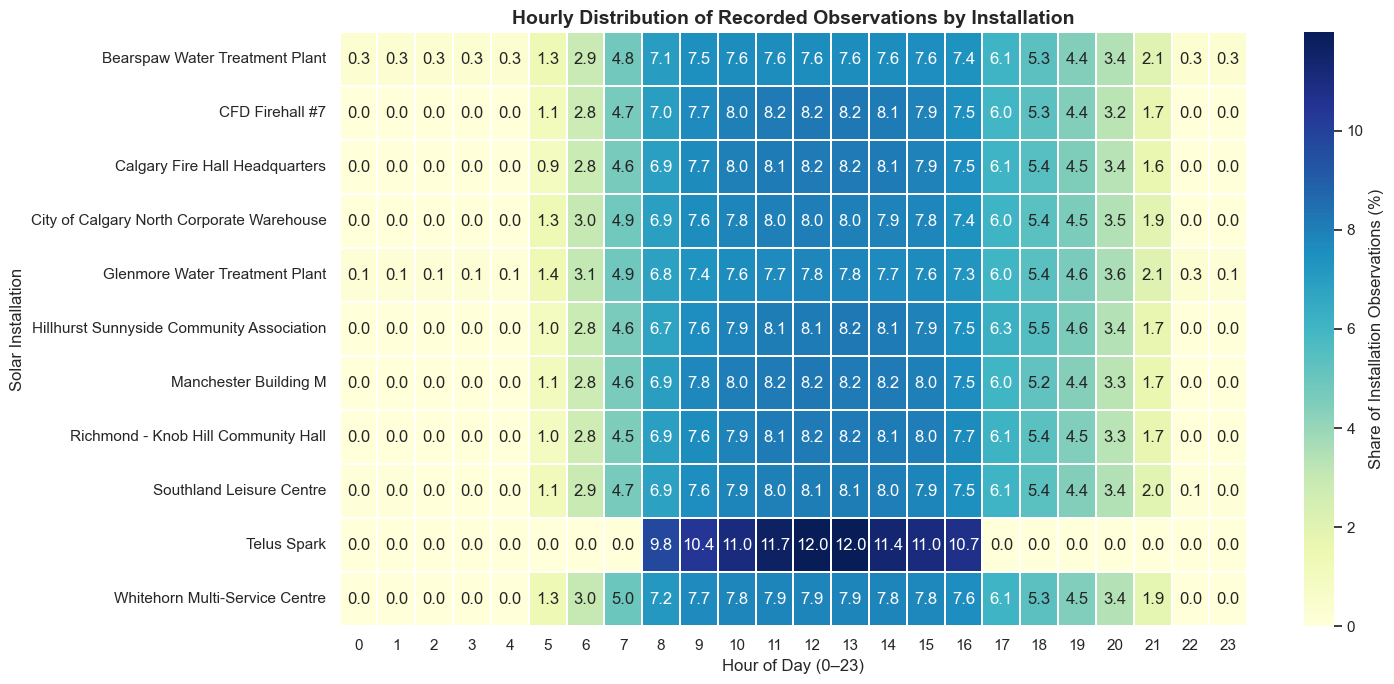

In [29]:

# Section 4.5.4 - Installation-Level Hourly Coverage Assessment

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Use the cleaned dataset
installation_hourly_df = df_clean.copy()

# Convert the date column to datetime
installation_hourly_df["date"] = pd.to_datetime(
    installation_hourly_df["date"],
    errors="coerce"
)

# Remove observations with invalid timestamps
installation_hourly_df = installation_hourly_df.dropna(
    subset=["date"]
)

# Extract hour of day
installation_hourly_df["hour"] = (
    installation_hourly_df["date"].dt.hour
)

# Count observations by installation and hour
installation_hourly_counts = (
    installation_hourly_df
    .groupby(["name", "hour"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)

print("Hourly Observation Counts by Installation:")
display(installation_hourly_counts)

# Convert counts into percentages of each installation's records
installation_hourly_percent = (
    installation_hourly_counts
    .div(installation_hourly_counts.sum(axis=1), axis=0)
    .mul(100)
)

# Plot percentage distribution heatmap
plt.figure(figsize=(15, 7))

sns.heatmap(
    installation_hourly_percent,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={"label": "Share of Installation Observations (%)"}
)

plt.title(
    "Hourly Distribution of Recorded Observations by Installation",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Solar Installation")

plt.tight_layout()
plt.show()


### Interpretation — Installation-Level Hourly Coverage Assessment

The installation-level hourly observation analysis reveals broadly similar reporting patterns across most photovoltaic installations, with observations concentrated during daylight-associated hours.

**Key findings:**

1. **Consistent daytime reporting patterns:** Most installations show increasing observation counts during the morning, relatively stable observation shares around midday, and declining counts toward the evening.

2. **Midday concentration:** For most installations, individual hours between approximately 11:00 and 15:00 account for around 7.5–8.2% of their total recorded observations.

3. **Distinct Telus Spark reporting pattern:** Telus Spark has observations concentrated between approximately 08:00 and 16:00, with a narrower reporting window than the other installations. Its limited historical coverage makes it less suitable for direct comparisons with installations having substantially longer reporting histories.

4. **Differences in nighttime reporting:** Bearspaw Water Treatment Plant and Glenmore Water Treatment Plant contain some nighttime observations, whereas several other installations have few or none. These differences may reflect variations in reporting practices or timestamp handling.

5. **Limitations of observation-share percentages:** The percentages represent the distribution of available records across hours, not the proportion of expected records successfully collected. Therefore, they should not be interpreted as data-completeness percentages.

**Implications for energy analysis and forecasting:**

The broadly consistent daytime reporting patterns suggest that hour-of-day is an important temporal characteristic of the dataset.

However, differences in installation reporting history and observation availability can introduce bias into production comparisons.

Installations with limited reporting histories, particularly Telus Spark, should be analyzed separately or excluded from comparisons requiring consistent multi-year coverage.

Future forecasting analyses should consider installation identity, hour-of-day, seasonality, and the availability of historical observations.

Further analysis should compare production using common reporting periods and normalized production metrics, while acknowledging that normalization by observation count does not fully correct for missing-data bias.

### 4.5.5 Coverage-Adjusted Solar Energy Production Comparisons

This subsection investigates how differences in observation availability influence comparisons of annual solar electricity production.

The analysis focuses on 2018–2022, a period with relatively consistent observation counts across most installations.

Three metrics are considered:

- **Total recorded energy (kWh):** The sum of available energy production measurements.
- **Mean energy per observation (kWh/observation):** The average recorded energy value, used to normalize totals by the number of observations.
- **Observation count:** The number of available measurements, used to assess reporting availability.

Comparing these metrics helps distinguish changes in recorded production totals from changes associated with observation availability.

However, normalization by observation count does not fully correct for missing-data bias, particularly when missing observations are concentrated in specific seasons, hours, or installations.

Energy production column: kWh

Annual Production and Observation-Normalized Comparison:


,year,total_kWh,observations,kWh_per_observation
3,2018,1714572.43,42516,40.33
4,2019,1725008.98,42132,40.94
5,2020,1765072.18,44943,39.27
6,2021,1603814.99,43430,36.93
7,2022,1584847.50,42655,37.16


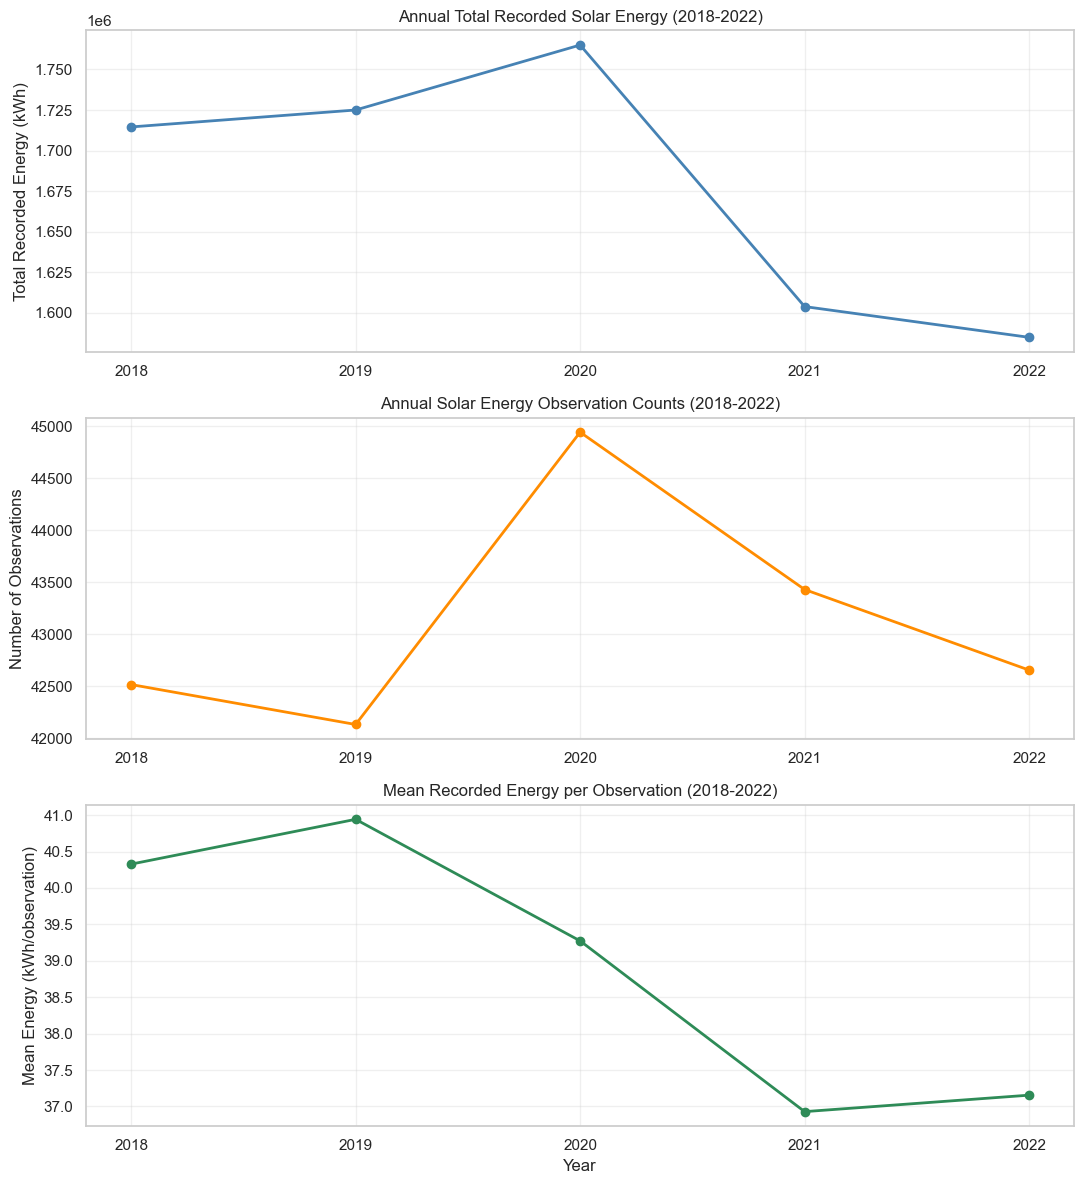

In [30]:

# Section 4.5.5 - Coverage-Adjusted Solar Energy Production Comparisons

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a working copy of the cleaned dataset
annual_data = df_clean.copy()

# Convert the date column to datetime
annual_data["date"] = pd.to_datetime(
    annual_data["date"],
    errors="coerce"
)

# 2. Identify the solar energy production column
possible_energy_columns = [
    "kWh", "energy_kWh", "energy", "Energy",
    "Energy(kWh)", "energy_kwh", "total_kWh"
]

energy_column = next(
    (col for col in possible_energy_columns
     if col in annual_data.columns),
    None
)

if energy_column is None:
    raise ValueError(
        "Energy column not found. Available columns: "
        + str(annual_data.columns.tolist())
    )

print(f"Energy production column: {energy_column}")

# Ensure energy values are numeric
annual_data[energy_column] = pd.to_numeric(
    annual_data[energy_column],
    errors="coerce"
)

# Remove records with invalid dates or energy values
annual_data = annual_data.dropna(
    subset=["date", energy_column]
)

# 3. Extract the calendar year
annual_data["year"] = annual_data["date"].dt.year

# 4. Calculate annual production statistics
coverage_adjusted_annual = (
    annual_data.groupby("year")
    .agg(
        total_kWh=(energy_column, "sum"),
        observations=(energy_column, "count"),
        mean_kWh=(energy_column, "mean")
    )
    .reset_index()
)

# 5. Select 2018-2022 for comparison
coverage_adjusted_annual = (
    coverage_adjusted_annual[
        coverage_adjusted_annual["year"].between(2018, 2022)
    ]
    .sort_values("year")
    .copy()
)

# 6. Calculate mean energy per recorded observation
coverage_adjusted_annual["kWh_per_observation"] = (
    coverage_adjusted_annual["total_kWh"]
    / coverage_adjusted_annual["observations"]
)

# 7. Display the comparison table
print("\nAnnual Production and Observation-Normalized Comparison:")

display(
    coverage_adjusted_annual[
        [
            "year",
            "total_kWh",
            "observations",
            "kWh_per_observation"
        ]
    ].round(2)
)

# 8. Create three comparison charts
fig, axes = plt.subplots(3, 1, figsize=(11, 12))

# Chart 1: Annual total recorded energy
axes[0].plot(
    coverage_adjusted_annual["year"],
    coverage_adjusted_annual["total_kWh"],
    marker="o",
    linewidth=2,
    color="steelblue"
)

axes[0].set_title(
    "Annual Total Recorded Solar Energy (2018-2022)"
)
axes[0].set_ylabel("Total Recorded Energy (kWh)")
axes[0].grid(alpha=0.3)

# Chart 2: Annual observation counts
axes[1].plot(
    coverage_adjusted_annual["year"],
    coverage_adjusted_annual["observations"],
    marker="o",
    linewidth=2,
    color="darkorange"
)

axes[1].set_title(
    "Annual Solar Energy Observation Counts (2018-2022)"
)
axes[1].set_ylabel("Number of Observations")
axes[1].grid(alpha=0.3)

# Chart 3: Mean energy per observation
axes[2].plot(
    coverage_adjusted_annual["year"],
    coverage_adjusted_annual["kWh_per_observation"],
    marker="o",
    linewidth=2,
    color="seagreen"
)

axes[2].set_title(
    "Mean Recorded Energy per Observation (2018-2022)"
)
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Mean Energy (kWh/observation)")
axes[2].grid(alpha=0.3)

# Display integer years on all charts
for ax in axes:
    ax.set_xticks(coverage_adjusted_annual["year"])

plt.tight_layout()
plt.show()


### Interpretation — Coverage-Adjusted Solar Energy Production Comparisons

The observation-normalized annual production analysis compares total recorded solar electricity generation, observation counts, and mean energy per recorded observation during 2018–2022.

**Key findings:**

1. **Highest total recorded production in 2020:** Total recorded solar energy reached approximately 1.77 million kWh in 2020, coinciding with the highest annual observation count of 44,943.

2. **Highest mean energy per observation in 2019:** Although 2020 had the highest recorded total, 2019 had the highest mean recorded energy per observation (40.94 kWh), compared with 39.27 kWh in 2020.

3. **Declining recorded production after 2020:** Total recorded energy decreased from approximately 1.77 million kWh in 2020 to 1.58 million kWh in 2022. Mean energy per observation also decreased from 39.27 to 37.16 kWh during the same period.

4. **Relatively stable observation availability:** Annual observation counts remained between approximately 42,000 and 45,000 during 2018–2022, supporting more meaningful comparisons than periods with substantially incomplete reporting.

5. **Importance of normalization:** Differences between trends in total recorded energy and mean energy per observation demonstrate that observation availability influences annual production totals.

**Implications for data quality and forecasting:**

Observation-normalized comparisons provide additional context for interpreting annual solar electricity production. However, dividing total energy by observation count does not fully correct for missing-data bias.

Differences in seasonal reporting, installation composition, and hourly observation availability may still influence the results.

Therefore, changes in mean recorded energy should not automatically be interpreted as changes in solar panel efficiency or equipment performance.

The 2018–2022 period is a reasonable candidate for further analysis and forecasting preparation, subject to additional installation-level and temporal consistency checks.

### 4.5.6 Installation-Level Production Comparisons Across Consistent Years

This subsection examines annual solar electricity production at the installation level during 2018–2022.

The objectives are to:

- Compare annual mean recorded energy production across individual installations.
- Examine observation counts for each installation and year.
- Identify installations with relatively consistent historical reporting.
- Investigate whether aggregate production trends are also visible at the installation level.
- Support the selection of suitable installations and historical periods for subsequent forecasting.

The analysis uses mean energy per recorded observation to account for differences in the number of available records.

However, this metric does not fully correct for missing observations, differences in installation capacity, or variations in seasonal and hourly coverage. Therefore, results are interpreted as descriptive production comparisons rather than direct measures of photovoltaic efficiency.

Installation-Level Annual Production Summary:


,name,year,total_kWh,observations,mean_kWh
0,Bearspaw Water Treatment Plant,2018,699322.07,5149,135.82
1,Bearspaw Water Treatment Plant,2019,672440.86,4542,148.05
2,Bearspaw Water Treatment Plant,2020,655411.72,4645,141.10
3,Bearspaw Water Treatment Plant,2021,451611.17,4607,98.03
4,Bearspaw Water Treatment Plant,2022,547548.05,4356,125.70
5,CFD Firehall #7,2018,25942.96,3945,6.58
6,CFD Firehall #7,2019,32730.05,4054,8.07
7,CFD Firehall #7,2020,34675.51,4475,7.75
8,CFD Firehall #7,2021,36784.57,4440,8.28
9,CFD Firehall #7,2022,34816.11,4303,8.09



Mean Recorded Energy (kWh/observation):


year,2018,2019,2020,2021,2022
name,,,,,
Bearspaw Water Treatment Plant,135.82,148.05,141.10,98.03,125.70
CFD Firehall #7,6.58,8.07,7.75,8.28,8.09
Calgary Fire Hall Headquarters,4.24,4.17,4.31,4.38,4.29
City of Calgary North Corporate Warehouse,26.53,23.38,29.10,31.20,31.17
Glenmore Water Treatment Plant,59.83,59.71,62.92,64.29,47.77
Hillhurst Sunnyside Community Association,8.07,8.15,7.94,8.64,8.35
Manchester Building M,8.49,9.02,9.47,8.29,6.66
Richmond - Knob Hill Community Hall,2.79,2.69,2.79,2.97,2.88
Southland Leisure Centre,33.61,35.29,36.08,38.66,38.41



Annual Observation Counts by Installation:


year,2018,2019,2020,2021,2022
name,,,,,
Bearspaw Water Treatment Plant,5149.0,4542.0,4645.0,4607.0,4356.0
CFD Firehall #7,3945.0,4054.0,4475.0,4440.0,4303.0
Calgary Fire Hall Headquarters,4208.0,4303.0,4444.0,4349.0,4256.0
City of Calgary North Corporate Warehouse,4363.0,4415.0,4569.0,4532.0,4292.0
Glenmore Water Treatment Plant,4171.0,4010.0,4470.0,4237.0,4381.0
Hillhurst Sunnyside Community Association,3839.0,3230.0,4367.0,3915.0,3594.0
Manchester Building M,3747.0,4456.0,4529.0,4483.0,4241.0
Richmond - Knob Hill Community Hall,4283.0,4274.0,4410.0,4383.0,4363.0
Southland Leisure Centre,4239.0,4333.0,4390.0,3886.0,4402.0


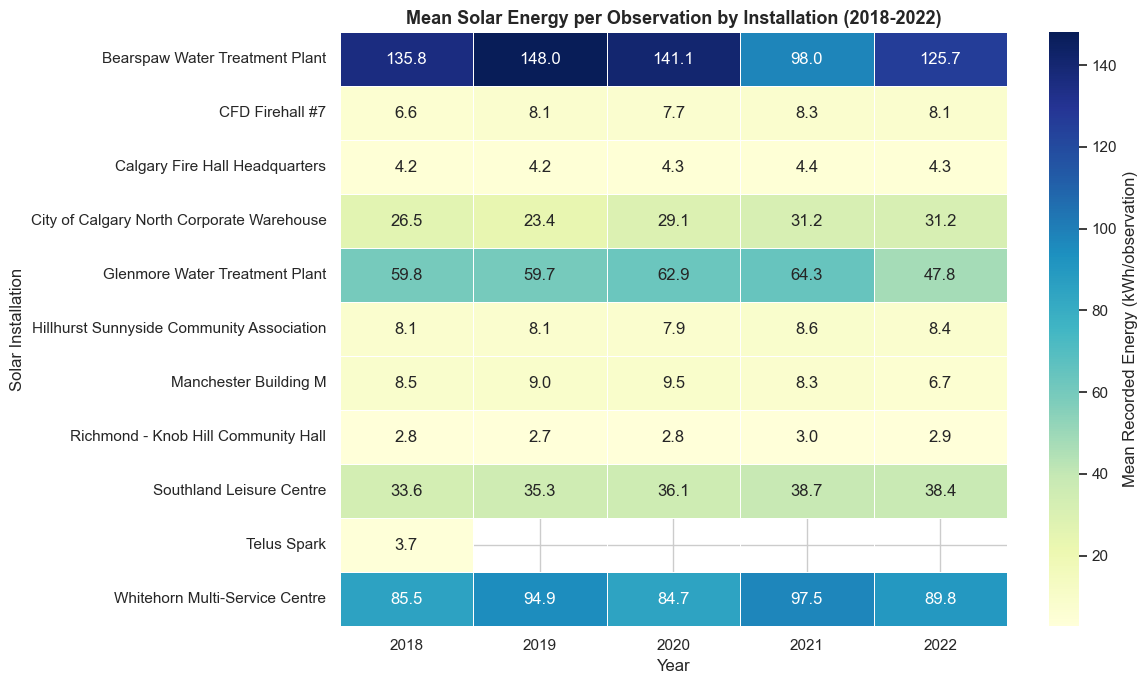

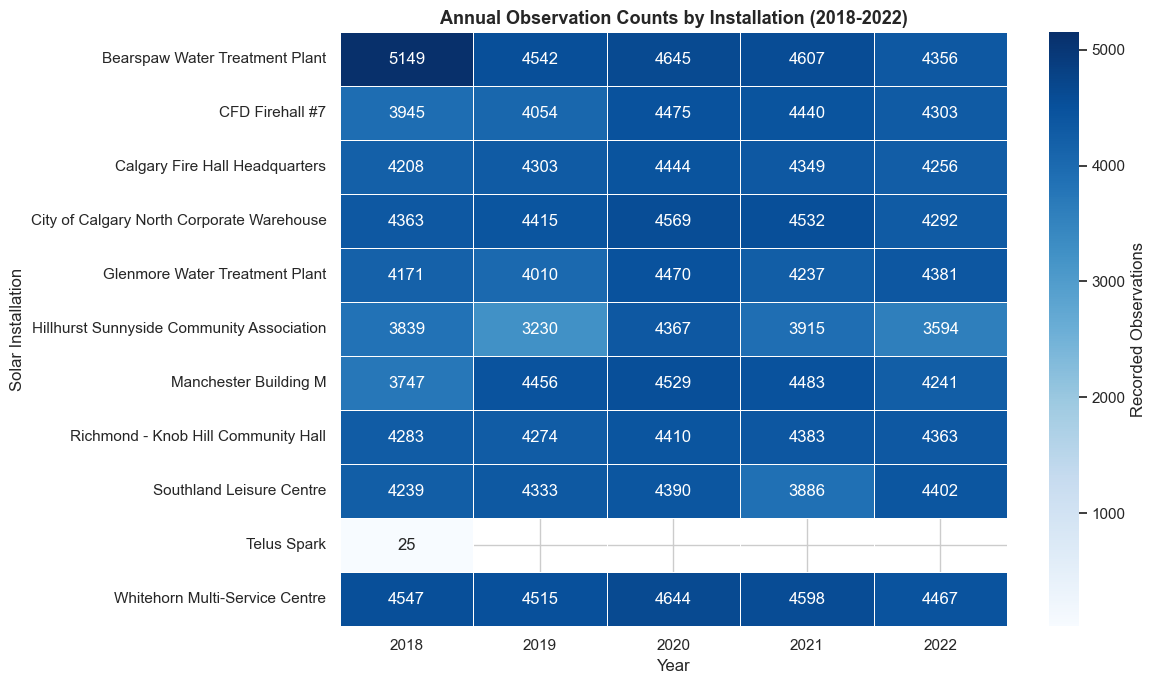

In [31]:

# Section 4.5.6 - Installation-Level Production Comparisons
# Across Consistent Years (2018-2022)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Prepare the cleaned dataset
installation_annual_df = df_clean.copy()

installation_annual_df["date"] = pd.to_datetime(
    installation_annual_df["date"],
    errors="coerce"
)

installation_annual_df["kWh"] = pd.to_numeric(
    installation_annual_df["kWh"],
    errors="coerce"
)

installation_annual_df = installation_annual_df.dropna(
    subset=["date", "name", "kWh"]
)

# 2. Extract year and select 2018-2022
installation_annual_df["year"] = (
    installation_annual_df["date"].dt.year
)

installation_annual_df = installation_annual_df[
    installation_annual_df["year"].between(2018, 2022)
].copy()

# 3. Calculate annual statistics for each installation
installation_annual_comparison = (
    installation_annual_df
    .groupby(["name", "year"])
    .agg(
        total_kWh=("kWh", "sum"),
        observations=("kWh", "count"),
        mean_kWh=("kWh", "mean")
    )
    .reset_index()
)

print("Installation-Level Annual Production Summary:")
display(
    installation_annual_comparison.round(2)
)

# 4. Create a year-by-installation mean energy table
installation_mean_pivot = (
    installation_annual_comparison
    .pivot(
        index="name",
        columns="year",
        values="mean_kWh"
    )
    .reindex(columns=range(2018, 2023))
)

print("\nMean Recorded Energy (kWh/observation):")
display(installation_mean_pivot.round(2))

# 5. Create a year-by-installation observation count table
installation_count_pivot = (
    installation_annual_comparison
    .pivot(
        index="name",
        columns="year",
        values="observations"
    )
    .reindex(columns=range(2018, 2023))
)

print("\nAnnual Observation Counts by Installation:")
display(installation_count_pivot)

# 6. Heatmap of mean energy per observation
plt.figure(figsize=(12, 7))

sns.heatmap(
    installation_mean_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.4,
    cbar_kws={
        "label": "Mean Recorded Energy (kWh/observation)"
    }
)

plt.title(
    "Mean Solar Energy per Observation by Installation (2018-2022)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Solar Installation")

plt.tight_layout()
plt.show()

# 7. Heatmap of annual observation counts
plt.figure(figsize=(12, 7))

sns.heatmap(
    installation_count_pivot,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    linewidths=0.4,
    cbar_kws={"label": "Recorded Observations"}
)

plt.title(
    "Annual Observation Counts by Installation (2018-2022)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Solar Installation")

plt.tight_layout()
plt.show()


#### Interpretation of Installation-Level Production Comparisons (2018–2022)

The installation-level analysis reveals substantial differences in recorded solar energy production across the monitored facilities during 2018–2022.

**1. Differences in recorded production levels**

Bearspaw Water Treatment Plant consistently recorded the highest mean energy per observation, ranging from 98.03 kWh in 2021 to 148.05 kWh in 2019. Whitehorn Multi-Service Centre also recorded relatively high production, with annual means ranging from 84.70 to 97.51 kWh per observation.

Smaller recorded values were observed at installations such as Calgary Fire Hall Headquarters and Richmond–Knob Hill Community Hall. However, differences in recorded energy cannot be interpreted directly as differences in system efficiency because installation capacities and operating conditions may vary.

**2. Variation in annual production trends**

The results demonstrate that annual production trends are not uniform across installations.

Bearspaw Water Treatment Plant experienced a notable reduction in mean recorded energy in 2021, followed by a partial recovery in 2022. Glenmore Water Treatment Plant recorded a decrease from 64.29 kWh per observation in 2021 to 47.77 kWh in 2022.

Conversely, Southland Leisure Centre increased from 33.61 kWh per observation in 2018 to 38.41 kWh in 2022. Whitehorn Multi-Service Centre also recorded a higher mean in 2022 than in 2018, although its annual values fluctuated.

These differences indicate that aggregate production trends may conceal installation-specific patterns.

**3. Observation coverage and data availability**

Most installations maintained several thousand recorded observations annually throughout 2018–2022, providing a stronger basis for comparison than the earlier and later years of the dataset.

Nevertheless, reporting coverage varied between installations and years. For example, Hillhurst Sunnyside Community Association recorded 3,230 observations in 2019 compared with 4,367 in 2020.

Telus Spark was an important exception, with only 25 observations in 2018 and no available records during 2019–2022. Consequently, this installation is unsuitable for continuous five-year trend analysis.

**4. Implications for subsequent analysis**

The results support using 2018–2022 as a relatively consistent historical comparison period while retaining installation-level distinctions.

For subsequent forecasting, installations with sufficient temporal coverage should be prioritized. Missing periods, seasonal patterns, installation capacity, and differences in reporting frequency should also be evaluated before model development.

Overall, the analysis demonstrates that observation-normalized production comparisons provide useful descriptive insights, but they do not fully eliminate the effects of missing data or differences in installation characteristics.

### 4.5.7 Summary of Data Coverage and Production Comparability

The data coverage and production comparability analysis highlights the importance of distinguishing recorded solar energy production from actual changes in photovoltaic system performance.

The main findings are:

1. **Uneven historical coverage:** The dataset contains substantial differences in observation availability across years, particularly during the early reporting period and in 2023.

2. **Relatively consistent comparison period:** The years 2018–2022 provide a more suitable basis for historical comparison because annual observation counts are substantially more consistent.

3. **Influence of reporting frequency:** Changes in annual total recorded energy reflect both production values and the number of available observations. Consequently, total energy trends should not be interpreted independently of reporting coverage.

4. **Installation-level differences:** Solar installations exhibit distinct production patterns, indicating that aggregate trends do not necessarily represent the behavior of individual systems.

5. **Incomplete installation records:** Telus Spark has insufficient observations for continuous comparisons during 2018–2022.

6. **Limitations of observation normalization:** Mean energy per observation improves descriptive comparability but does not fully correct for missing records, unequal sampling intervals, installation capacity, or differences in seasonal coverage.

**Conclusion:** The analysis establishes a foundation for subsequent statistical analysis and forecasting by identifying a more consistent historical comparison period and highlighting installations with insufficient reporting coverage. Future modeling should incorporate appropriate temporal validation, installation-level characteristics, and data-quality considerations to avoid misleading conclusions.

## 4.6 Solar Energy Production Distribution and Outlier Analysis

This section examines the statistical distribution of recorded
solar energy production, including central tendency, dispersion,
skewness, and potential outliers.

The objective is to understand the variability of energy
production observations and identify extreme values that may
require further investigation.

### 4.6.1 Descriptive Statistics and Distribution Shape

In [32]:

# Section 4.6.1 - Descriptive Statistics and Distribution Shape

import pandas as pd
import numpy as np

# Create a separate copy to preserve the original summary
distribution_summary = installation_summary.copy()

# Calculate mean-to-median ratio
distribution_summary["mean_median_ratio"] = (
    distribution_summary["mean_kWh"]
    / distribution_summary["median_kWh"].replace(0, np.nan)
)

# Display installation-level descriptive statistics
print("Installation-Level Descriptive Statistics:")

display(
    distribution_summary[
        ["name", "observations", "mean_kWh",
         "median_kWh", "max_kWh", "mean_median_ratio"]
    ].round(2)
)

# Compare mean and median energy production
print("\nMean-to-Median Comparison:")

display(
    distribution_summary[
        ["name", "mean_kWh", "median_kWh",
         "mean_median_ratio"]
    ].round(2)
)


Installation-Level Descriptive Statistics:


,name,observations,mean_kWh,median_kWh,max_kWh,mean_median_ratio
9,Bearspaw Water Treatment Plant,24869,123.96,61.66,514.46,2.01
3,Whitehorn Multi-Service Centre,27716,92.32,51.82,369.06,1.78
6,Glenmore Water Treatment Plant,25920,59.84,32.76,239.97,1.83
0,Southland Leisure Centre,31590,36.32,20.82,123.62,1.75
4,City of Calgary North Corporate Warehouse,27092,28.38,16.63,102.86,1.71
1,Hillhurst Sunnyside Community Association,23467,7.94,5.07,29.00,1.57
8,Manchester Building M,22533,8.13,4.50,34.12,1.81
7,CFD Firehall #7,22659,7.51,4.25,29.21,1.76
2,Calgary Fire Hall Headquarters,25637,4.30,2.48,16.60,1.73
5,Richmond - Knob Hill Community Hall,26623,2.82,1.90,9.28,1.49



Mean-to-Median Comparison:


,name,mean_kWh,median_kWh,mean_median_ratio
9,Bearspaw Water Treatment Plant,123.96,61.66,2.01
3,Whitehorn Multi-Service Centre,92.32,51.82,1.78
6,Glenmore Water Treatment Plant,59.84,32.76,1.83
0,Southland Leisure Centre,36.32,20.82,1.75
4,City of Calgary North Corporate Warehouse,28.38,16.63,1.71
1,Hillhurst Sunnyside Community Association,7.94,5.07,1.57
8,Manchester Building M,8.13,4.50,1.81
7,CFD Firehall #7,7.51,4.25,1.76
2,Calgary Fire Hall Headquarters,4.30,2.48,1.73
5,Richmond - Knob Hill Community Hall,2.82,1.90,1.49


#### Interpretation of Descriptive Statistics

The descriptive statistical analysis reveals substantial differences in recorded solar energy production across the 11 installations.

All installations exhibit mean production values greater than their corresponding medians, suggesting positively skewed distributions. This pattern indicates that relatively high production observations may influence the arithmetic mean.

Bearspaw Water Treatment Plant recorded the highest mean production (123.96 kWh) and the highest mean-to-median ratio (2.01), followed by several installations with ratios between approximately 1.5 and 1.8.

The differences between mean and median values highlight the importance of examining the complete distribution rather than relying exclusively on average production.

Telus Spark has substantially fewer observations than other installations, limiting the reliability of direct comparisons.

Further visualization is required to assess distribution shape and identify potentially unusual production values.

### 4.6.2 Distribution Visualization

This subsection uses histograms to examine the frequency
distribution of recorded solar energy production and assess
the concentration and spread of observations.

In [33]:
# Identify available DataFrames and their columns

import pandas as pd

for variable_name, value in list(globals().items()):
    if isinstance(value, pd.DataFrame):
        if "kWh" in value.columns and "name" in value.columns:
            print(f"DataFrame: {variable_name}")
            print(f"Shape: {value.shape}")
            print(f"Columns: {value.columns.tolist()}")
            print("-" * 60)

DataFrame: df
Shape: (258423, 16)
Columns: ['name', 'id', 'address', 'date', 'kWh', 'public_url', 'installationDate', 'uid', 'time_difference', 'hour', 'day', 'month', 'year', 'day_of_week', 'season', 'potential_outlier']
------------------------------------------------------------
DataFrame: late_evening
Shape: (5026, 15)
Columns: ['name', 'id', 'address', 'date', 'kWh', 'public_url', 'installationDate', 'uid', 'time_difference', 'hour', 'day', 'month', 'year', 'day_of_week', 'season']
------------------------------------------------------------
DataFrame: flagged_observations
Shape: (25, 7)
Columns: ['id', 'name', 'date', 'kWh', 'hour', 'month', 'season']
------------------------------------------------------------
DataFrame: df_clean
Shape: (258423, 16)
Columns: ['name', 'id', 'address', 'date', 'kWh', 'public_url', 'installationDate', 'uid', 'time_difference', 'hour', 'day', 'month', 'year', 'day_of_week', 'season', 'potential_outlier']
---------------------------------------------

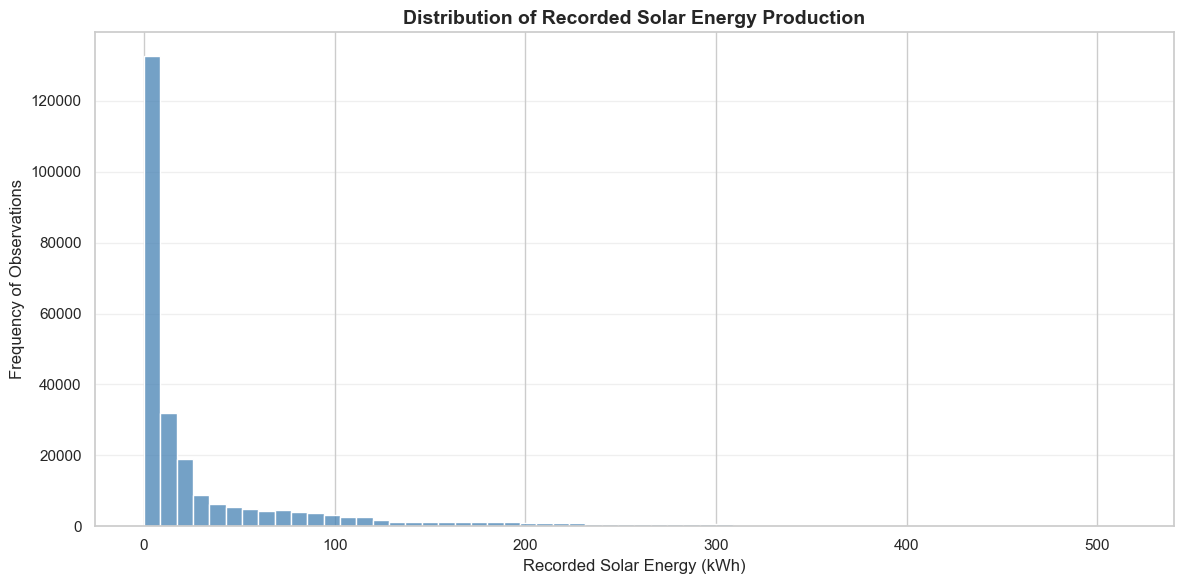

Overall Solar Energy Distribution Summary:
count    258423.00
mean         38.06
std          71.60
min           0.00
25%           1.37
50%           8.03
75%          35.88
max         514.46
Name: kWh, dtype: float64

Skewness: 3.05


In [34]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare valid solar energy observations
energy_data = pd.to_numeric(
    df_clean["kWh"], errors="coerce"
).dropna()

# Plot the distribution of recorded solar energy production
plt.figure(figsize=(12, 6))

sns.histplot(
    energy_data,
    bins=60,
    color="steelblue",
    edgecolor="white"
)

plt.title(
    "Distribution of Recorded Solar Energy Production",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Recorded Solar Energy (kWh)")
plt.ylabel("Frequency of Observations")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Display summary statistics
print("Overall Solar Energy Distribution Summary:")
print(energy_data.describe().round(2))

print(f"\nSkewness: {energy_data.skew():.2f}")


### Interpretation: Overall Solar Energy Production Distribution

The distribution of recorded solar energy production is strongly
positively skewed, with a skewness coefficient of 3.05.

Across 258,423 observations, the mean recorded energy production
is 38.06 kWh, while the median is only 8.03 kWh. This substantial
difference indicates that relatively high production readings
increase the overall average.

The histogram shows that most observations are concentrated
at lower energy values, with a long right tail extending to
a maximum of 514.46 kWh.

The standard deviation of 71.60 kWh further indicates
considerable variation in recorded solar energy production.

However, the overall distribution combines installations
with different production capacities. Therefore, high
recorded values should not automatically be classified as
errors or abnormal observations.

Installation-level distributions will be examined next
to provide a more meaningful comparison.

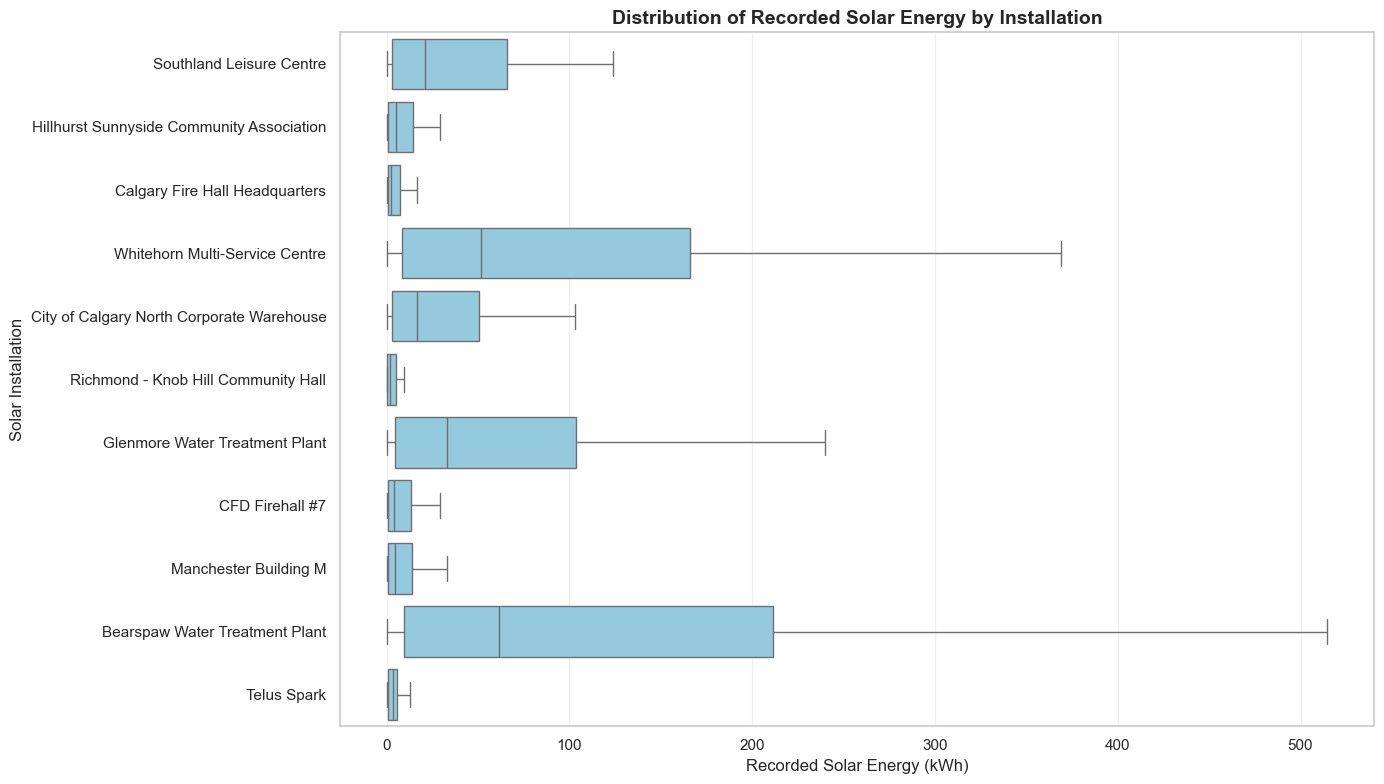

In [35]:
# Step 2: Installation-level solar energy distributions

import matplotlib.pyplot as plt
import seaborn as sns

# Use valid observations with installation names
installation_dist = df_clean[
    ["name", "kWh"]
].dropna().copy()

# Create boxplots for each installation
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=installation_dist,
    x="kWh",
    y="name",
    color="skyblue",
    showfliers=False
)

plt.title(
    "Distribution of Recorded Solar Energy by Installation",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Recorded Solar Energy (kWh)")
plt.ylabel("Solar Installation")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation: Installation-Level Solar Energy Distribution

The installation-level boxplots reveal substantial differences in recorded solar energy production across the 11 installations.

Bearspaw Water Treatment Plant exhibits the widest absolute distribution, followed by Whitehorn Multi-Service Centre and Glenmore Water Treatment Plant. These installations generally record higher energy production values and greater absolute variation than smaller installations.

In contrast, Richmond–Knob Hill Community Hall, Calgary Fire Hall Headquarters, and CFD Firehall #7 display relatively narrow distributions on the shared energy scale.

Several installations exhibit right-skewed distributions, characterized by longer upper whiskers and greater dispersion toward higher production values.

These differences may reflect variation in installation capacity, environmental conditions, seasonal production patterns, and recording characteristics. The boxplots alone cannot establish the causes.

Telus Spark has substantially fewer observations than the other installations, so comparisons involving this installation should be interpreted cautiously.

Overall, the results demonstrate that analyzing all installations together can obscure important differences in their production distributions. Installation-level analysis therefore provides a more meaningful basis for investigating potential outliers.

In [36]:

# Step 3: Installation-level potential outlier analysis

import pandas as pd

outlier_data = df_clean[["name", "kWh"]].dropna().copy()

# Calculate installation-specific quartiles
quartiles = outlier_data.groupby("name")["kWh"].agg(
    Q1=lambda x: x.quantile(0.25),
    Q3=lambda x: x.quantile(0.75)
).reset_index()

quartiles["IQR"] = quartiles["Q3"] - quartiles["Q1"]

quartiles["lower_bound"] = quartiles["Q1"] - 1.5 * quartiles["IQR"]
quartiles["upper_bound"] = quartiles["Q3"] + 1.5 * quartiles["IQR"]

# Attach the thresholds to each observation
outlier_data = outlier_data.merge(quartiles, on="name", how="left")

# Identify potential outliers
outlier_data["iqr_outlier"] = (
    (outlier_data["kWh"] < outlier_data["lower_bound"]) |
    (outlier_data["kWh"] > outlier_data["upper_bound"])
)

# Summarize potential outliers by installation
outlier_summary = outlier_data.groupby("name").agg(
    observations=("kWh", "size"),
    potential_outliers=("iqr_outlier", "sum")
).reset_index()

outlier_summary["outlier_percentage"] = (
    outlier_summary["potential_outliers"] /
    outlier_summary["observations"] * 100
)

outlier_summary = outlier_summary.sort_values(
    "outlier_percentage", ascending=False
)

print("Installation-Level Potential Outlier Summary:")
display(outlier_summary.round(2))

print(
    "\nTotal potential outliers:",
    outlier_data["iqr_outlier"].sum()
)

print(
    "Overall potential outlier percentage:",
    f'{outlier_data["iqr_outlier"].mean() * 100:.2f}%'
)


Installation-Level Potential Outlier Summary:


,name,observations,potential_outliers,outlier_percentage
9,Telus Spark,317,14,4.42
6,Manchester Building M,22533,11,0.05
0,Bearspaw Water Treatment Plant,24869,0,0.00
1,CFD Firehall #7,22659,0,0.00
2,Calgary Fire Hall Headquarters,25637,0,0.00
3,City of Calgary North Corporate Warehouse,27092,0,0.00
4,Glenmore Water Treatment Plant,25920,0,0.00
5,Hillhurst Sunnyside Community Association,23467,0,0.00
7,Richmond - Knob Hill Community Hall,26623,0,0.00
8,Southland Leisure Centre,31590,0,0.00



Total potential outliers: 25
Overall potential outlier percentage: 0.01%


### Interpretation: Installation-Level Potential Outlier Detection

The interquartile range (IQR) method was applied separately to each solar installation to identify unusually high or low recorded energy values.

Across 258,423 observations, only 25 potential outliers were identified, representing approximately 0.01% of the dataset.

Telus Spark recorded the highest proportion of potential outliers, with 14 observations (4.42%). Manchester Building M recorded 11 potential outliers (approximately 0.05%). No observations exceeded the IQR-based thresholds for the remaining nine installations.

Despite having the largest absolute production ranges, Bearspaw Water Treatment Plant and Whitehorn Multi-Service Centre recorded no potential outliers under this method. This demonstrates that high production variability does not necessarily indicate statistically unusual observations.

The results also highlight that a strongly right-skewed overall distribution does not automatically produce a high proportion of IQR outliers when thresholds are calculated separately for each installation.

Because solar energy production varies with installation characteristics, time of day, season, and environmental conditions, the flagged observations should be treated as candidates for further investigation rather than confirmed data errors.

No observations were removed during this analysis.

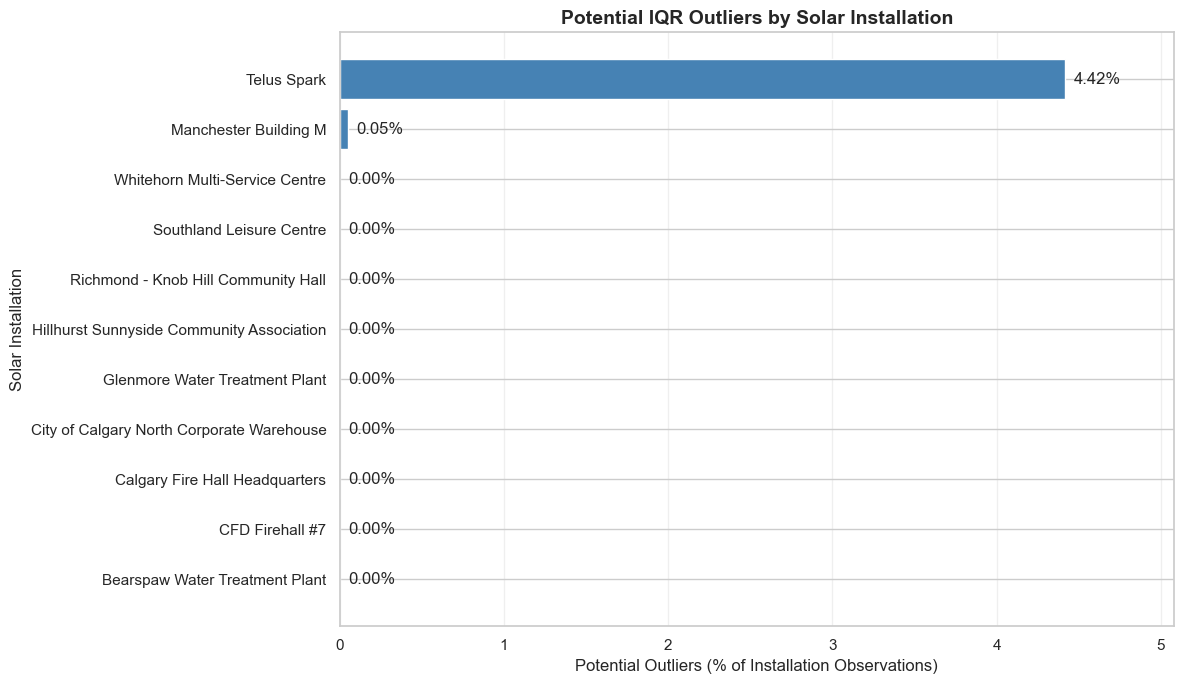

In [37]:
# Step 4: Visualize potential outlier percentages

import matplotlib.pyplot as plt
import seaborn as sns

plot_data = outlier_summary.sort_values(
    "outlier_percentage", ascending=True
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    plot_data["name"],
    plot_data["outlier_percentage"],
    color="steelblue"
)

plt.title(
    "Potential IQR Outliers by Solar Installation",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Potential Outliers (% of Installation Observations)")
plt.ylabel("Solar Installation")

# Add percentage labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.xlim(0, plot_data["outlier_percentage"].max() * 1.15)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretation: Distribution of Potential Outliers Across Installations

The visualization shows that potential IQR outliers are concentrated in two solar installations.

Telus Spark has the highest proportion of flagged observations (4.42%), followed by Manchester Building M (0.05%). The remaining nine installations have no observations classified as potential outliers under the installation-specific IQR method.

Telus Spark's relatively high percentage should be interpreted cautiously because the installation has only 317 recorded observations.

Overall, the findings suggest that unusually extreme readings are uncommon under the selected IQR criteria. However, statistical outliers do not necessarily represent incorrect measurements, and no records have been removed from the dataset.

In [38]:
# Step 5: Inspect the existing potential_outlier flag

print("Data type:")
print(df["potential_outlier"].dtype)

print("\nExisting flag values and frequencies:")
print(
    df["potential_outlier"]
    .value_counts(dropna=False)
)

print("\nExisting flag distribution by installation:")
display(
    pd.crosstab(
        df["name"],
        df["potential_outlier"],
        dropna=False
    )
)

Data type:
bool

Existing flag values and frequencies:
potential_outlier
False    258398
True         25
Name: count, dtype: int64

Existing flag distribution by installation:


potential_outlier,False,True
name,,
Bearspaw Water Treatment Plant,24869,0
CFD Firehall #7,22659,0
Calgary Fire Hall Headquarters,25637,0
City of Calgary North Corporate Warehouse,27092,0
Glenmore Water Treatment Plant,25920,0
Hillhurst Sunnyside Community Association,23467,0
Manchester Building M,22522,11
Richmond - Knob Hill Community Hall,26623,0
Southland Leisure Centre,31590,0


### Interpretation: Validation of Potential Outlier Flags

The existing `potential_outlier` variable identifies 25 potentially unusual observations out of 258,423 records, representing approximately 0.01% of the dataset.

At the installation level, Telus Spark accounts for 14 flagged observations (4.42% of its 317 records), while Manchester Building M accounts for 11 flagged observations (approximately 0.05% of its 22,533 records). The remaining nine installations have no flagged observations.

These results are consistent with the previously generated installation-level outlier summary and visualization.

Although the flagged observations are relatively uncommon, they should not automatically be treated as measurement errors. Differences in installation capacity, weather conditions, operating patterns, and data availability may contribute to unusual production values.

Therefore, the flagged records are retained for further investigation rather than automatically removed from the dataset.

## 5. Relationships Between Solar Energy Production Variables

This section examines statistical relationships between recorded solar energy production and selected numerical variables.

Unlike the previous exploratory analyses, which focused primarily on temporal trends, installation comparisons, and data distributions, this section investigates how variables are associated with one another.

### 5.1 Correlation Analysis

Pearson correlation coefficients are calculated to assess linear relationships between recorded energy production (`kWh`) and selected numerical time-related features.

The results are visualized using a correlation heatmap. Correlations involving calendar variables must be interpreted cautiously because hour, month, and day of the week represent cyclical time patterns, which Pearson correlation does not fully capture.

,kWh,hour,day,month,year,day_of_week
kWh,1.000,0.006,0.012,-0.028,-0.019,-0.005
hour,0.006,1.000,0.005,-0.013,0.003,-0.003
day,0.012,0.005,1.000,-0.041,-0.018,-0.005
month,-0.028,-0.013,-0.041,1.000,-0.122,0.004
year,-0.019,0.003,-0.018,-0.122,1.000,0.004
day_of_week,-0.005,-0.003,-0.005,0.004,0.004,1.000


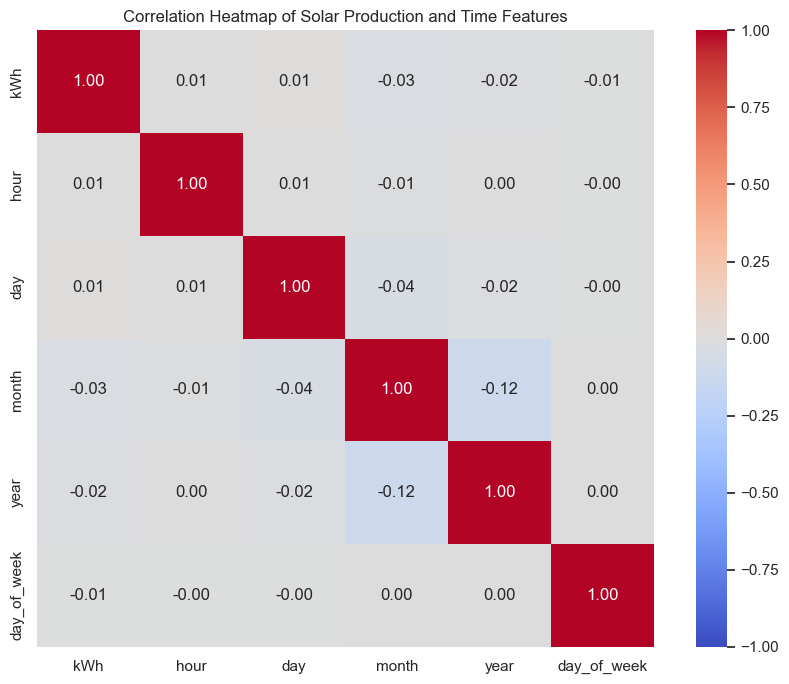

In [39]:

import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical variables relevant to production
correlation_columns = [
    "kWh",
    "hour",
    "day",
    "month",
    "year",
    "day_of_week"
]

# Calculate Pearson correlation coefficients
correlation_matrix = df[correlation_columns].corr()

display(correlation_matrix.round(3))

# Visualize the correlation matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Heatmap of Solar Production and Time Features")
plt.tight_layout()
plt.show()


### Interpretation of the Correlation Analysis

The Pearson correlation analysis reveals negligible linear relationships between recorded solar energy production (`kWh`) and the selected numerical time-related variables.

The correlation coefficients between energy production and hour (0.006), day of month (0.012), month (-0.028), year (-0.019), and day of week (-0.005) are all close to zero. This indicates that none of these variables exhibits a meaningful linear association with recorded production when considered individually across the combined dataset.

However, these findings do not imply that solar energy production is independent of time. Solar generation typically follows nonlinear daily and seasonal patterns, which Pearson correlation cannot adequately represent when cyclical time variables are encoded as ordinary integers.

Furthermore, differences in installation capacity, observation frequency, and temporal coverage may influence the observed relationships.

Therefore, the correlation results should be interpreted as evidence of weak **linear** associations rather than an absence of temporal production patterns. Additional relationship-based visualizations are needed to examine possible nonlinear associations.

Overall, the heatmap provides a useful preliminary assessment of relationships among the numerical variables, while highlighting the limitations of linear correlation for time-dependent solar energy data.

### 5.2 Scatter Plot Analysis of Solar Energy Production

Scatter plots are used to investigate relationships between recorded energy production and selected numerical variables.

Unlike correlation coefficients, which summarize linear associations, scatter plots allow visual inspection of nonlinear patterns, variability, and unusual observations.

The analysis begins by examining the relationship between hour of day and recorded solar energy production.

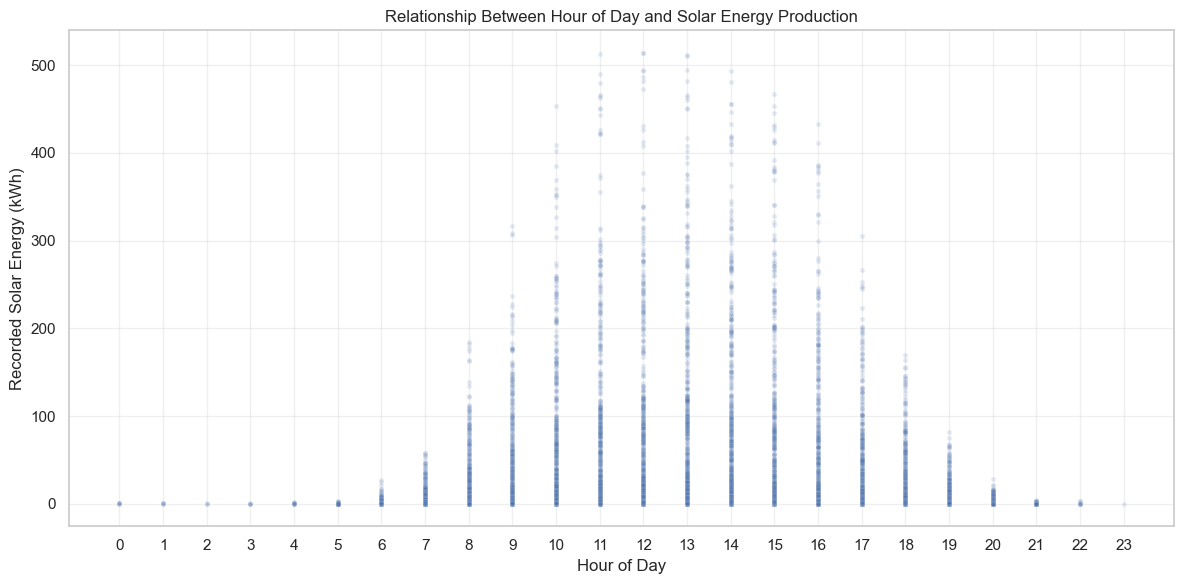

In [40]:

# Sample observations for clearer visualization
scatter_df = df[["hour", "kWh"]].dropna().sample(
    n=min(10000, len(df)),
    random_state=42
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=scatter_df,
    x="hour",
    y="kWh",
    alpha=0.15,
    s=12
)

plt.title("Relationship Between Hour of Day and Solar Energy Production")
plt.xlabel("Hour of Day")
plt.ylabel("Recorded Solar Energy (kWh)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation of the Hourly Production Scatter Plot

The scatter plot reveals a clear nonlinear relationship between hour of day and recorded solar energy production.

Production values are generally close to zero during nighttime hours, begin increasing during the morning, and reach their highest observed levels around midday and early afternoon. Production subsequently declines during the evening.

The greatest variability occurs during daylight hours, particularly between approximately 10:00 and 16:00, when recorded production ranges from low values to more than 500 kWh.

This variation may reflect differences in installation capacity, seasonal solar availability, weather conditions, and operating characteristics. However, these potential explanations cannot be confirmed from the scatter plot alone.

The results also help explain why the Pearson correlation between hour and energy production was approximately 0.006. Although the scatter plot reveals a strong visual daily pattern, the relationship is nonlinear and cannot be adequately summarized by a single linear correlation coefficient.

Overall, the scatter plot demonstrates the importance of combining numerical correlation analysis with visual exploration when investigating time-dependent solar energy production.

### 5.3 Seasonal Variation in Hourly Solar Energy Production

This analysis investigates how hourly solar energy production patterns differ across seasons.

Mean recorded energy production is calculated for each combination of season and hour of day. A heatmap is used to identify periods associated with higher and lower production and to examine whether the daily production profile changes throughout the year.

Because the dataset includes installations with different capacities and reporting coverage, the heatmap represents observed average production rather than capacity-normalized performance.

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
season,,,,,,,,,,,,,,,,,,,,,
Winter,0.69,0.69,0.68,0.48,0.42,0.43,0.41,0.57,1.78,6.68,...,19.38,12.24,5.14,1.83,0.19,0.69,0.68,0.69,0.69,0.74
Spring,0.24,0.24,0.24,0.32,0.34,0.13,1.81,7.19,21.45,41.87,...,77.32,70.94,57.97,40.10,21.83,7.75,1.91,0.23,0.57,0.30
Summer,0.08,0.08,0.08,0.08,0.08,0.25,2.35,10.79,29.71,52.69,...,88.40,80.93,69.19,53.28,33.14,14.48,3.95,0.66,0.03,0.08
Autumn,6.56,1.00,0.05,0.08,0.08,0.08,0.02,1.12,6.17,18.99,...,49.63,41.08,29.25,21.35,7.40,1.98,1.72,22.22,19.33,13.04


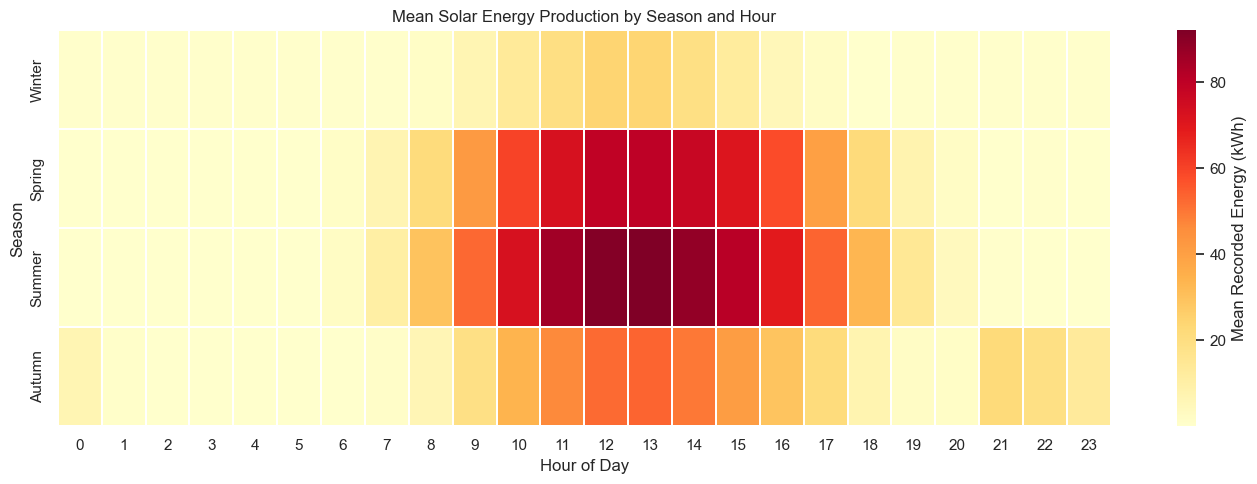

In [41]:

# Calculate mean recorded production for each season and hour
season_hour_summary = (
    df.groupby(["season", "hour"])["kWh"]
    .mean()
    .unstack()
)

# Arrange seasons in calendar order
season_order = ["Winter", "Spring", "Summer", "Autumn"]

season_hour_summary = season_hour_summary.reindex(
    season_order
)

# Display the summary
display(season_hour_summary.round(2))

# Create seasonal-hourly heatmap
plt.figure(figsize=(14, 5))

sns.heatmap(
    season_hour_summary,
    cmap="YlOrRd",
    annot=False,
    linewidths=0.3,
    cbar_kws={"label": "Mean Recorded Energy (kWh)"}
)

plt.title("Mean Solar Energy Production by Season and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Season")
plt.tight_layout()
plt.show()


In [42]:

# Check observation counts and production statistics
# for late-night hours in each season

nighttime_check = (
    df[df["hour"].isin([21, 22, 23])]
    .groupby(["season", "hour"])["kWh"]
    .agg(
        observations="count",
        mean_kWh="mean",
        median_kWh="median",
        max_kWh="max"
    )
    .reset_index()
)

display(nighttime_check.round(2))


,season,hour,observations,mean_kWh,median_kWh,max_kWh
0,Autumn,21,23,22.22,5.97,66.25
1,Autumn,22,22,19.33,10.84,57.31
2,Autumn,23,22,13.04,8.75,41.22
3,Spring,21,1129,0.23,0.05,14.06
4,Spring,22,38,0.57,0.09,14.11
5,Spring,23,32,0.30,0.10,2.27
6,Summer,21,3521,0.66,0.18,21.04
7,Summer,22,58,0.03,0.02,0.12
8,Summer,23,18,0.08,0.07,0.12
9,Winter,21,54,0.69,0.36,14.02


### Interpretation of Seasonal-Hourly Production Patterns

The seasonal-hourly heatmap reveals substantial variation in recorded solar energy production across both seasons and hours of the day.

Summer generally exhibits the highest mean recorded production during daylight hours, followed by spring. Winter shows considerably lower production and a narrower period of substantial daytime generation, while autumn displays intermediate daytime values.

For example, at 14:00, mean recorded production is approximately 88.40 kWh in summer compared with 19.38 kWh in winter.

These findings indicate that hourly production patterns vary across seasons. However, differences in installation capacity, observation frequency, and temporal coverage limit direct comparisons of seasonal performance.

**Investigation of Unusual Nighttime Values**

The heatmap also reveals unexpectedly high average production during late-night hours in autumn.

A diagnostic examination shows that autumn contains only 23 observations at 21:00 and 22 observations each at 22:00 and 23:00. Their corresponding mean production values are 22.22 kWh, 19.33 kWh, and 13.04 kWh.

The relatively small observation counts make these averages sensitive to individual records. Additionally, the differences between mean and median values indicate positively skewed nighttime observations.

Nevertheless, the nighttime medians remain unusually elevated, suggesting that the pattern cannot be attributed exclusively to a few extreme values.

Potential explanations include timestamp inconsistencies, differences in installation representation, or unusual production records. These explanations remain unverified.

Overall, the analysis demonstrates the importance of considering observation counts and data quality when interpreting aggregated solar energy production patterns. The unusual nighttime records should be retained for further investigation rather than automatically removed.

## 6. Conclusions, Limitations, and Recommendations

This section summarizes the major findings from the exploratory analysis of solar energy production, discusses the limitations affecting their interpretation, and presents recommendations for future analysis and practical applications.

### 6.1 Summary of Key Findings

The exploratory data analysis examined 258,423 observations collected from 11 solar energy installations over the period 2015–2023. The investigation focused on temporal production patterns, differences between installations, data coverage, production variability, outliers, and relationships between recorded energy production and time-related variables.

The major findings are summarized below.

**1. Solar energy production exhibits a distinct daily pattern.**

Recorded energy production generally increases during the morning, reaches its highest levels around midday and early afternoon, and declines during the evening. Nighttime production is typically close to zero.

The scatter plot analysis further demonstrated that the relationship between hour of day and energy production is nonlinear, explaining why the Pearson correlation coefficient between these variables was close to zero.

**2. Seasonal variation influences observed production patterns.**

The seasonal-hourly analysis revealed higher mean daytime production during summer and spring, while winter generally exhibited lower production and a shorter period of substantial daytime generation.

For example, at 14:00, mean recorded production was approximately 88.40 kWh during summer compared with 19.38 kWh during winter.

These differences describe observed production patterns and should not be interpreted as capacity-normalized comparisons of solar installation performance.

**3. Production levels and variability differ between installations.**

Installation-level comparisons revealed substantial differences in recorded production magnitude and variability. These differences may reflect installation characteristics, including capacity and operating conditions, as well as differences in data availability.

Consequently, comparisons based solely on total recorded production may not accurately represent relative installation performance.

**4. Data coverage is essential for interpreting long-term production trends.**

The analysis identified differences in observation frequency and temporal coverage across installations and years.

In particular, incomplete coverage during certain years limits the reliability of direct comparisons of annual production totals. Observation-normalized statistics and comparisons across more consistently represented periods provide additional context, although they do not fully eliminate differences in reporting frequency or installation characteristics.

**5. Recorded solar energy production is positively skewed.**

The overall production distribution exhibited positive skewness, with a mean of approximately 38.06 kWh and a median of approximately 8.03 kWh.

This indicates that relatively high production observations contribute disproportionately to the overall mean. Median values and distribution-based visualizations therefore provide useful complementary information when interpreting typical production.

**6. Potential outliers are uncommon but require contextual interpretation.**

The existing outlier classification identified 25 potentially unusual observations among 258,423 records, representing approximately 0.01% of the dataset.

These observations were concentrated in Telus Spark and Manchester Building M. However, unusually high or low values cannot automatically be classified as measurement errors without additional contextual information.

**7. Correlation analysis highlights the limitations of simple linear relationships.**

Pearson correlation coefficients between recorded production and numerical time-related variables were close to zero.

However, the scatter plot and seasonal-hourly heatmap revealed clear nonlinear temporal patterns. This demonstrates that weak linear correlation does not imply an absence of meaningful relationships.

**8. Unusual nighttime records indicate potential data-quality concerns.**

The seasonal-hourly analysis identified unexpectedly elevated recorded production during late-night hours in autumn.

Further examination revealed that these averages were based on relatively few observations, making them sensitive to individual records. The findings suggest that timestamp conventions, reporting practices, or unusual measurements warrant further investigation before these values are used in predictive or operational applications.

### 6.2 Limitations of the Analysis

Although the exploratory data analysis provides useful insights into solar energy production patterns, several limitations should be considered when interpreting the findings.

**1. Incomplete and Uneven Data Coverage**

The dataset contains differences in observation frequency and reporting coverage across installations and years. Some installations have substantially fewer records than others, while certain years have incomplete coverage.

For example, the dataset includes only 317 observations for Telus Spark, making its statistical summaries less representative than those of installations with considerably more observations.

Similarly, incomplete annual coverage limits the reliability of comparisons based on total recorded production. Differences in observation counts may reflect reporting availability rather than actual changes in energy generation.

**2. Differences Between Solar Installations**

The dataset combines observations from 11 installations that may differ in generating capacity, panel configuration, orientation, maintenance practices, and operating conditions.

However, the analysis does not include sufficient installation-specific technical information to account for these differences.

Consequently, higher recorded energy production should not automatically be interpreted as better efficiency or superior installation performance.

**3. Limited Environmental Information**

Solar energy generation is influenced by environmental conditions such as solar irradiance, cloud cover, temperature, and shading.

These variables were not directly included in the analyzed dataset. Therefore, the study cannot quantify their individual contributions to changes in recorded production.

Although seasonal and hourly patterns are observable, their underlying environmental causes cannot be established from the available data alone.

**4. Potential Timestamp and Reporting Inconsistencies**

The analysis identified unexpectedly elevated recorded production during late-night hours in autumn.

These observations may reflect timestamp conventions, inconsistent reporting practices, or unusual measurements. However, the available information is insufficient to determine their exact causes.

Such inconsistencies may affect the interpretation of hourly and seasonal production patterns.

**5. Limitations of Outlier Detection**

The analysis identified 25 potentially unusual observations using the

### 6.3 Recommendations and Future Work

Based on the findings and limitations of this exploratory data analysis, several recommendations are proposed to improve data reliability, support meaningful comparisons between installations, and guide future solar energy research.

**1. Improve Data Collection and Reporting Consistency**

Future data collection should prioritize consistent recording intervals, standardized timestamps, and complete reporting across installations.

Automated data-quality checks could help identify missing observations, irregular reporting gaps, duplicate timestamps, and unusual nighttime production values.

Improving reporting consistency would strengthen the reliability of temporal analyses and comparisons across installations and years.

**2. Investigate Unusual Nighttime Production Records**

The unexpectedly elevated nighttime production values observed during autumn warrant further investigation.

Future work should examine the affected installations, original timestamps, reporting conventions, and measurement records to determine whether these observations represent genuine generation, timestamp misalignment, or data-quality issues.

Potentially unusual records should be verified before being corrected or excluded from subsequent analyses.

**3. Incorporate Environmental and Weather Data**

Future studies should integrate solar irradiance, temperature, cloud cover, and other relevant environmental variables.

Combining production records with weather observations would enable a more comprehensive investigation of the factors associated with changes in solar energy generation.

This could also improve the development of forecasting models and support more informed energy planning.

**4. Normalize Production for Fair Installation Comparisons**

Where technical information is available, recorded energy production should be normalized using installation capacity and appropriate reporting periods.

Metrics such as energy generated per unit of installed capacity could provide more meaningful comparisons between installations of different sizes.

Such normalization would help distinguish differences in installation scale from differences in operational performance.

**5. Strengthen Temporal Coverage and Comparability**

Long-term comparisons should prioritize periods with sufficiently complete and consistent reporting.

Future analyses could establish minimum data-coverage thresholds, identify comparable observation windows, and account for missing or irregular records.

These measures would reduce the risk of interpreting incomplete annual totals as evidence of changes in solar energy generation.

**6. Develop and Evaluate Solar Energy Forecasting Models**

The exploratory findings provide a foundation for future predictive modeling.

Potential approaches include regression-based methods, random forests, gradient boosting, and time-series forecasting techniques.

Future models could incorporate cyclical time features, installation characteristics, historical production, and environmental variables.

Model performance should be evaluated using

### 6.4 Overall Conclusion

This project conducted an exploratory data analysis of historical solar energy production records from 11 installations, comprising 258,423 observations collected between 2015 and 2023. The primary objective was to investigate production patterns, assess data quality, examine differences between installations, and identify factors that should be considered when interpreting solar energy generation data.

The analysis demonstrated that recorded solar energy production exhibits clear temporal patterns, with generation generally increasing during the morning, reaching its highest levels around midday and early afternoon, and declining toward evening. Seasonal differences were also observed, with summer and spring generally showing higher daytime production than winter.

Installation-level comparisons revealed substantial differences in recorded production magnitude and variability. However, the findings also highlighted the importance of accounting for differences in installation capacity, observation frequency, and reporting coverage before drawing conclusions about relative performance.

Distributional analysis showed that production values are positively skewed, while outlier investigations identified a small number of potentially unusual observations requiring contextual interpretation. The examination of unexpected nighttime production values further demonstrated the importance of validating timestamps and measurement records.

Correlation and scatter plot analyses established that simple linear correlation coefficients do not adequately describe the nonlinear relationships between solar energy production and time-related variables. Consequently, combining statistical summaries with visual exploratory methods provides a more informative understanding of the dataset.

A central finding of the project is that **data completeness, reporting consistency, and installation comparability are essential for reliable solar energy analysis**. Without addressing these factors, differences in recorded production may be incorrectly interpreted as changes in generating performance.

Although the study did not develop a predictive model or directly evaluate solar installation efficiency, it provides a foundation for future research involving weather-data integration, capacity-normalized performance assessment, and solar energy forecasting.

Overall, the project demonstrates the value of exploratory data analysis in identifying production patterns, revealing data-quality concerns, and establishing the analytical considerations necessary for more reliable renewable energy planning and decision-making.

## 7. Optional Bonus: Baseline Solar Energy Production Prediction

### 7.1 Introduction and Modeling Objective

The preceding sections explored historical solar energy production patterns, installation-level differences, temporal relationships, and data-quality limitations. This optional bonus section extends the exploratory analysis by developing and evaluating a simple baseline prediction model.

**Objective:** Predict recorded solar energy production (`kWh`) using historical observations and available time-related and installation-specific information.

The modeling process will involve:

1. Preparing a suitable dataset for prediction.
2. Selecting relevant input features and defining the target variable.
3. Dividing observations into training and testing sets using chronological ordering.
4. Establishing a simple baseline prediction method.
5. Training a basic regression model for comparison.
6. Evaluating predictive performance using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).
7. Interpreting the results and discussing limitations.

**Modeling considerations:**

- Recorded production may differ substantially across installations because of capacity, reporting frequency, and operating conditions.
- Solar energy production exhibits nonlinear daily and seasonal patterns.
- Missing timestamps and irregular reporting intervals may influence model performance.
- Chronological evaluation is preferred to avoid training on observations recorded after those used for testing.
- The absence of weather and solar irradiance measurements limits the information available to the model.

The purpose of this section is not to develop a production-ready forecasting system, but to demonstrate a reproducible baseline modeling workflow and assess how well simple models can predict recorded solar energy output.

### 7.2 Data Preparation and Feature Selection

For the baseline prediction model, the analysis focuses on solar energy production observations recorded between **2018 and 2022**.

The data will be divided chronologically into:

- **Training period:** 2018–2021
- **Testing period:** 2022

Before developing the model, the number of observations available for each installation will be assessed across both periods. This check is necessary because installations have different reporting histories, and some may have insufficient observations for reliable model training or evaluation.

The prediction target is recorded solar electricity production (`kWh`). Potential predictor variables include the hour of day, month, seasonal information, and installation identity.

Only installations with suitable training and testing coverage will be considered for the initial baseline model. Any exclusions will be documented and justified.

In [43]:

# Section 7.2 - Check installation coverage for baseline modeling

# Select observations from 2018 through 2022
model_coverage = df.loc[df["year"].between(2018, 2022)].copy()

# Label the chronological training and testing periods
model_coverage["period"] = np.where(
    model_coverage["year"] <= 2021,
    "Training (2018-2021)",
    "Testing (2022)"
)

# Count available observations by installation and period
coverage_summary = (
    model_coverage
    .groupby(["name", "period"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Training (2018-2021)", "Testing (2022)"],
        fill_value=0
    )
)

# Calculate total observations for each installation
coverage_summary["Total (2018-2022)"] = coverage_summary.sum(axis=1)

# Display results
print("Installation Coverage for Baseline Prediction")
print("-" * 50)
display(coverage_summary.sort_values("Total (2018-2022)", ascending=False))

print(f"\nTotal observations (2018-2022): {len(model_coverage):,}")
print(f"Number of installations: {model_coverage['name'].nunique()}")


Installation Coverage for Baseline Prediction
--------------------------------------------------


period,Training (2018-2021),Testing (2022),Total (2018-2022)
name,,,
Bearspaw Water Treatment Plant,18943,4356,23299
Whitehorn Multi-Service Centre,18304,4467,22771
City of Calgary North Corporate Warehouse,17879,4292,22171
Richmond - Knob Hill Community Hall,17350,4363,21713
Calgary Fire Hall Headquarters,17304,4256,21560
Manchester Building M,17215,4241,21456
Glenmore Water Treatment Plant,16888,4381,21269
Southland Leisure Centre,16848,4402,21250
CFD Firehall #7,16914,4303,21217



Total observations (2018-2022): 215,676
Number of installations: 11


### 7.3 Finalizing the Modeling Dataset

The installation coverage assessment identified 215,676 observations across 11 installations during 2018–2022.

Ten installations have substantial historical observations during both the training period (2018–2021) and the testing period (2022).

**Telus Spark is excluded from the baseline prediction model** because it contains only 25 observations during the training period and no observations during the testing period. Consequently, its predictive performance cannot be evaluated using the proposed chronological split.

The remaining ten installations will be retained as modeling candidates, subject to validation of their production measurements and predictor variables.

This exclusion applies only to the optional prediction model. Telus Spark remains part of the original dataset and preceding exploratory analysis.

In [44]:

# Section 7.3.1 - Prepare the modeling dataset

# Identify installations with observations in both periods
eligible_installations = coverage_summary.index[
    (coverage_summary["Training (2018-2021)"] > 0) &
    (coverage_summary["Testing (2022)"] > 0)
]

# Create a separate dataset for modeling
model_df = model_coverage[
    model_coverage["name"].isin(eligible_installations)
].copy()

# Select the target and candidate predictor columns
model_columns = ["name", "date", "year", "month", "hour", "kWh"]

model_df = model_df[model_columns].copy()

# Convert the timestamp to datetime
model_df["date"] = pd.to_datetime(
    model_df["date"], errors="coerce"
)

# Check missing values
print("Missing values before cleaning:")
display(model_df.isna().sum().to_frame("Missing Values"))

# Remove rows missing required modeling information
model_df = model_df.dropna(subset=model_columns)

# Remove negative production measurements, if any
model_df = model_df[model_df["kWh"] >= 0].copy()

# Sort observations chronologically
model_df = model_df.sort_values(
    ["date", "name"]
).reset_index(drop=True)

# Display final dataset information
print(f"\nFinal modeling observations: {len(model_df):,}")
print(f"Installations included: {model_df['name'].nunique()}")

print("\nObservations by modeling period:")
print(
    model_df.groupby(
        np.where(model_df["year"] <= 2021, "Training", "Testing")
    ).size()
)

print("\nProduction summary:")
display(model_df["kWh"].describe().to_frame("kWh"))


Missing values before cleaning:


,Missing Values
name,0
date,0
year,0
month,0
hour,0
kWh,0



Final modeling observations: 215,651
Installations included: 10

Observations by modeling period:
Testing      42655
Training    172996
dtype: int64

Production summary:


,kWh
count,215651.000000
mean,38.920406
std,73.957711
min,0.000000
25%,1.416000
50%,8.155000
75%,34.859000
max,514.462000


### 7.4 Feature Selection and Chronological Train–Test Split

The baseline prediction model uses recorded solar energy production (`kWh`) as the target variable.

The selected predictors are:

- **Installation name:** Represents differences between solar installations.
- **Hour of day:** Captures daily production patterns.
- **Month:** Represents seasonal variation throughout the year.
- **Day of week:** Allows the model to assess potential weekly differences.

The modeling dataset is divided chronologically, with observations from **2018–2021 used for training** and observations from **2022 reserved for testing**.

This approach provides a more realistic assessment of predictive performance than a random split because the model is evaluated on observations recorded after the training period.

The year is used to define the split but is not included as a predictor in the initial model. Installation identity will be encoded appropriately during model training.

In [45]:

# Section 7.4 - Feature selection and chronological split

# Derive day of week from the timestamp
model_df["day_of_week"] = model_df["date"].dt.dayofweek

# Define predictors and target
feature_columns = ["name", "hour", "month", "day_of_week"]
target_column = "kWh"

# Chronological training and testing subsets
train_df = model_df[model_df["year"].between(2018, 2021)].copy()
test_df = model_df[model_df["year"] == 2022].copy()

# Separate predictors and target
X_train = train_df[feature_columns]
X_test = test_df[feature_columns]

y_train = train_df[target_column]
y_test = test_df[target_column]

# Verify the split
print("Chronological Train-Test Split")
print("-" * 40)
print(f"Training observations: {len(X_train):,}")
print(f"Testing observations:  {len(X_test):,}")
print(f"Predictor variables: {feature_columns}")
print(f"Target variable: {target_column}")

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting period:")
print(test_df["date"].min(), "to", test_df["date"].max())

print("\nInstallation coverage:")
print("Training:", X_train["name"].nunique())
print("Testing:", X_test["name"].nunique())

print("\nSample training predictors:")
display(X_train.head())


Chronological Train-Test Split
----------------------------------------
Training observations: 172,996
Testing observations:  42,655
Predictor variables: ['name', 'hour', 'month', 'day_of_week']
Target variable: kWh

Training period:
2018-01-01 00:00:00 to 2021-12-31 14:00:00

Testing period:
2022-01-01 10:00:00 to 2022-12-31 16:00:00

Installation coverage:
Training: 10
Testing: 10

Sample training predictors:


,name,hour,month,day_of_week
0,Bearspaw Water Treatment Plant,0,1,0
1,Bearspaw Water Treatment Plant,1,1,0
2,Bearspaw Water Treatment Plant,2,1,0
3,Bearspaw Water Treatment Plant,3,1,0
4,Bearspaw Water Treatment Plant,4,1,0


### 7.5 Establishing a Baseline Prediction Model

A baseline model provides a reference level of predictive performance against which more advanced regression models can be evaluated.

For this analysis, a historical-average baseline is constructed using the mean recorded solar energy production (`kWh`) for each combination of installation and hour of day.

The baseline is calculated exclusively from the **2018–2021 training dataset** and applied to the **2022 testing dataset**.

For installation-hour combinations that are not represented in the training data, the model uses the installation-level historical mean as a fallback. If an installation-level mean is unavailable, the overall training mean is used.

Predictions are evaluated using:

- **Mean Absolute Error (MAE):** The average absolute difference between actual and predicted production.
- **Root Mean Squared Error (RMSE):** A measure that places greater emphasis on larger prediction errors.

Lower MAE and RMSE values indicate better predictive performance.

This baseline provides a simple, interpretable benchmark for subsequent regression modeling.

In [46]:

# Section 7.5 - Historical-average baseline prediction

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate historical mean production by installation and hour
hourly_baseline = (
    train_df.groupby(["name", "hour"])["kWh"]
    .mean()
    .rename("baseline_kWh")
)

# Calculate fallback means from training data only
installation_baseline = train_df.groupby("name")["kWh"].mean()
overall_baseline = train_df["kWh"].mean()

# Match test observations to historical installation-hour means
baseline_test = test_df[["name", "hour"]].join(
    hourly_baseline,
    on=["name", "hour"]
)

# Fill missing combinations with installation-level means
baseline_test["baseline_kWh"] = (
    baseline_test["baseline_kWh"]
    .fillna(baseline_test["name"].map(installation_baseline))
    .fillna(overall_baseline)
)

# Generate predictions
baseline_predictions = baseline_test["baseline_kWh"]

# Evaluate performance
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

print("Historical-Average Baseline Model")
print("-" * 40)
print(f"Test observations: {len(y_test):,}")
print(f"MAE:  {baseline_mae:.3f} kWh")
print(f"RMSE: {baseline_rmse:.3f} kWh")

# Store results for future model comparison
baseline_results = {
    "Model": "Historical Average (Installation + Hour)",
    "MAE": baseline_mae,
    "RMSE": baseline_rmse
}

# Display sample actual and predicted values
baseline_comparison = pd.DataFrame({
    "Installation": test_df["name"].to_numpy(),
    "Actual_kWh": y_test.to_numpy(),
    "Predicted_kWh": baseline_predictions.to_numpy()
})

print("\nSample baseline predictions:")
display(baseline_comparison.head(10))


Historical-Average Baseline Model
----------------------------------------
Test observations: 42,655
MAE:  24.004 kWh
RMSE: 45.463 kWh

Sample baseline predictions:


,Installation,Actual_kWh,Predicted_kWh
0,Manchester Building M,0.026,10.259286
1,Glenmore Water Treatment Plant,0.067,91.293560
2,Hillhurst Sunnyside Community Association,0.014,11.973467
3,Manchester Building M,0.105,12.843638
4,Richmond - Knob Hill Community Hall,0.003,4.200139
5,Glenmore Water Treatment Plant,0.099,99.293515
6,Hillhurst Sunnyside Community Association,0.045,13.254053
7,Manchester Building M,0.108,14.243113
8,Richmond - Knob Hill Community Hall,0.005,4.585500
9,Glenmore Water Treatment Plant,0.016,101.195141


#### 7.5.1 Baseline Model Performance

The historical-average baseline model was evaluated on 42,655 observations recorded during 2022.

The model achieved:

- **Mean Absolute Error (MAE):** 24.004 kWh
- **Root Mean Squared Error (RMSE):** 45.463 kWh

The MAE indicates that the model's predictions differ from actual recorded production by approximately 24 kWh on average. The higher RMSE suggests that some observations have relatively large prediction errors.

Inspection of sample predictions reveals substantial differences between actual and predicted production for certain observations. This reflects the limitations of using historical installation-hour averages, which cannot capture variations in weather, operational conditions, or other unobserved factors.

These results establish a reference benchmark for evaluating whether a regression model can improve predictive accuracy.

All baseline averages were calculated exclusively from the 2018–2021 training observations, preserving the independence of the 2022 test dataset.

### 7.6 Regression Model Development and Evaluation

A Random Forest regression model is developed to investigate whether nonlinear relationships between temporal and installation-specific predictors can improve solar energy production predictions.

Random Forest combines predictions from multiple decision trees and can represent complex interactions without requiring a linear relationship between predictors and the target.

The model uses four input features:

- **Installation name:** Identifies the solar installation.
- **Hour of day:** Represents daily production patterns.
- **Month:** Captures seasonal variation.
- **Day of week:** Represents potential weekly variation.

Installation identity is converted into numerical indicator variables using one-hot encoding.

The model is trained using observations from **2018–2021** and evaluated on the independent **2022 test dataset**. Preprocessing is fitted only on the training data to avoid information leakage.

Predictive performance will be assessed using MAE and RMSE and compared against the historical-average baseline.

The Random Forest serves as an initial nonlinear regression model rather than an optimized forecasting system.

In [47]:

# Section 7.6 - Random Forest regression model

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Identify categorical and numerical predictors
categorical_features = ["name"]
numerical_features = ["hour", "month", "day_of_week"]

# Encode installation names; retain numerical predictors
preprocessor = ColumnTransformer(
    transformers=[
        (
            "installation",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("time", "passthrough", numerical_features)
    ]
)

# Build a reproducible modeling pipeline
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=15,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train using 2018-2021 observations only
rf_pipeline.fit(X_train, y_train)

# Predict production for 2022 observations
rf_predictions = rf_pipeline.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))

print("Random Forest Regression Model")
print("-" * 40)
print(f"Training observations: {len(X_train):,}")
print(f"Testing observations:  {len(X_test):,}")
print(f"MAE:  {rf_mae:.3f} kWh")
print(f"RMSE: {rf_rmse:.3f} kWh")

# Compare with the historical-average baseline
model_comparison = pd.DataFrame([
    baseline_results,
    {
        "Model": "Random Forest Regressor",
        "MAE": rf_mae,
        "RMSE": rf_rmse
    }
])

print("\nModel performance comparison:")
display(model_comparison.round(3))


Random Forest Regression Model
----------------------------------------
Training observations: 172,996
Testing observations:  42,655
MAE:  16.166 kWh
RMSE: 35.375 kWh

Model performance comparison:


,Model,MAE,RMSE
0,Historical Average (Installation + Hour),24.004,45.463
1,Random Forest Regressor,16.166,35.375


#### 7.6.1 Regression Model Performance and Comparison

The Random Forest regression model was trained using 172,996 observations from 2018–2021 and evaluated on 42,655 observations from 2022.

The model achieved:

- **Mean Absolute Error (MAE):** 16.166 kWh
- **Root Mean Squared Error (RMSE):** 35.375 kWh

Compared with the historical-average baseline, which achieved an MAE of 24.004 kWh and RMSE of 45.463 kWh, the Random Forest produced lower prediction errors on both metrics.

Specifically, the Random Forest reduced:

- MAE by approximately **32.7%**.
- RMSE by approximately **22.2%**.

These improvements suggest that the Random Forest captured additional nonlinear relationships between installation identity, hour of day, month, day of week, and recorded solar energy production.

However, prediction errors remain substantial, particularly for observations with unusual production levels. The model does not incorporate weather conditions, solar irradiance, installation capacity, or changes in equipment performance.

Furthermore, differences in reporting frequency and operational conditions may affect the comparability of recorded production values across installations.

Overall, the Random Forest demonstrates improved predictive performance relative to the historical-average baseline on the 2022 test dataset. Nevertheless, the results should be interpreted as an initial modeling benchmark rather than evidence of production-ready forecasting capability.

### 7.7 Prediction Diagnostics and Visualization

Although the Random Forest regression model outperformed the historical-average baseline, overall evaluation metrics do not fully describe its predictive behavior.

Additional diagnostic analysis is therefore conducted to examine prediction accuracy, identify systematic errors, and assess variations in model performance.

The diagnostic analysis focuses on:

1. **Actual versus predicted production:** Examining the agreement between observed and predicted solar energy output.
2. **Residual distribution:** Investigating the magnitude and direction of prediction errors.
3. **Installation-level performance:** Comparing prediction accuracy across the ten installations.

These diagnostics help identify limitations that may not be apparent from aggregate MAE and RMSE values alone.

#### 7.7.1 Actual Versus Predicted Solar Energy Production

An actual-versus-predicted scatterplot is used to evaluate the relationship between observed production and Random Forest predictions.

A diagonal reference line represents perfect predictions, where predicted production equals actual production.

Points close to this line indicate relatively accurate predictions, while points farther away represent larger prediction errors.

The plot also helps reveal whether the model tends to overestimate low production values or underestimate high production values.

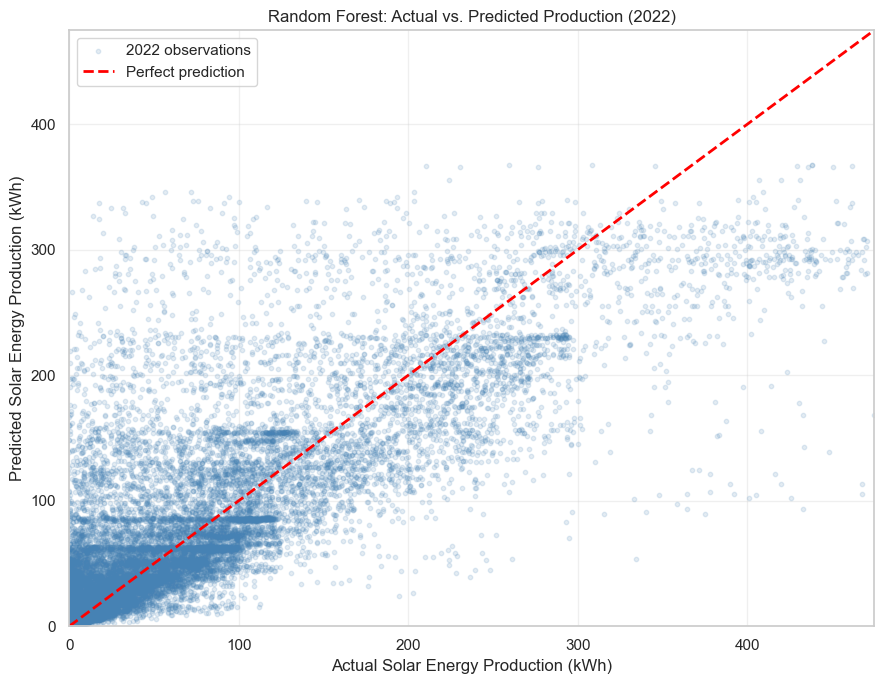

In [48]:

# Section 7.7.1 - Actual vs. Predicted Solar Energy Production

import matplotlib.pyplot as plt
import numpy as np

# Convert actual and predicted values to arrays
actual_values = y_test.to_numpy()
predicted_values = np.asarray(rf_predictions)

# Create actual vs. predicted scatterplot
plt.figure(figsize=(9, 7))

plt.scatter(
    actual_values,
    predicted_values,
    alpha=0.15,
    s=10,
    color="steelblue",
    label="2022 observations"
)

# Add perfect prediction reference line
plot_max = max(actual_values.max(), predicted_values.max())

plt.plot(
    [0, plot_max],
    [0, plot_max],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

plt.xlabel("Actual Solar Energy Production (kWh)")
plt.ylabel("Predicted Solar Energy Production (kWh)")
plt.title("Random Forest: Actual vs. Predicted Production (2022)")

plt.xlim(0, plot_max)
plt.ylim(0, plot_max)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation: Actual Versus Predicted Production**

The actual-versus-predicted scatterplot reveals a positive relationship between observed solar energy production and Random Forest predictions, although considerable variation remains.

Several important patterns are observed:

- **Overestimation at low production levels:** Numerous observations with low actual production have substantially higher predicted values.
- **Underestimation at high production levels:** Many observations with high actual production fall below the perfect-prediction reference line, indicating that the model tends to underestimate some production peaks.
- **Prediction dispersion:** The wide spread of observations around the diagonal reference line indicates that the model does not fully capture short-term variations in solar energy production.

These patterns suggest that the Random Forest captures general relationships between installation identity, time of day, and seasonal conditions but has limited ability to predict unusual or extreme production values.

The absence of weather-related predictors, such as solar irradiance and cloud cover, likely contributes to the remaining prediction errors.

Overall, the visualization supports the earlier quantitative findings: the Random Forest improves upon the historical-average baseline but still exhibits systematic prediction errors, particularly at low and high production levels.

#### 7.7.2 Residual Analysis

Residual analysis is conducted to examine the direction and distribution of prediction errors produced by the Random Forest regression model.

Residuals are calculated as the difference between actual and predicted solar energy production.

A residual value of zero represents a perfect prediction. Positive residuals indicate underestimation, while negative residuals indicate overestimation.

The residual distribution is examined to assess whether prediction errors are centered around zero, whether large errors occur frequently, and whether the model exhibits systematic bias.

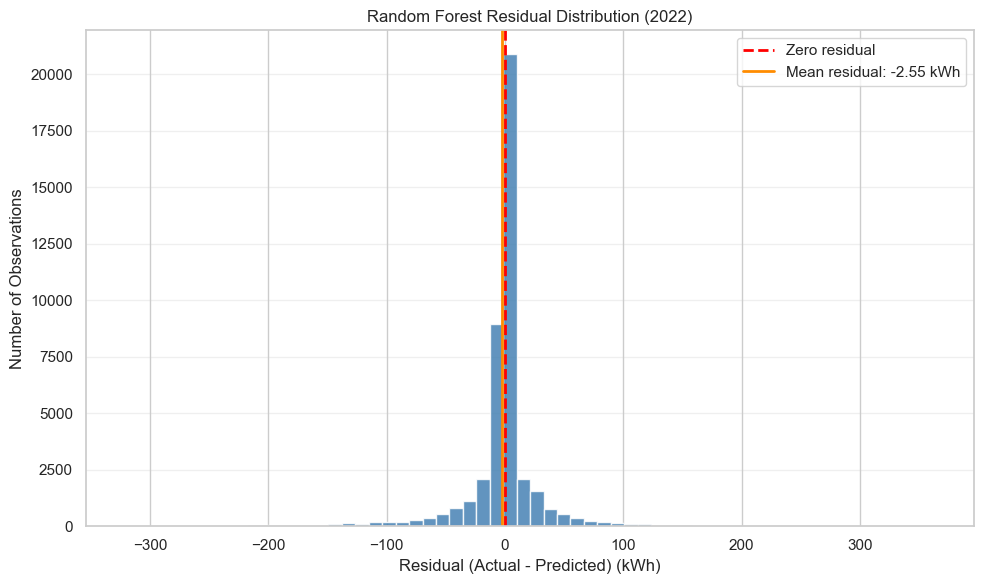

Random Forest Residual Summary
----------------------------------------
Mean residual:   -2.553 kWh
Median residual: -0.118 kWh
Minimum residual: -319.741 kWh
Maximum residual: 362.398 kWh


In [49]:

# Section 7.7.2 - Random Forest residual analysis

# Calculate residuals: actual minus predicted
rf_residuals = actual_values - predicted_values

# Plot the residual distribution
plt.figure(figsize=(10, 6))

plt.hist(
    rf_residuals,
    bins=60,
    color="steelblue",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero residual"
)

plt.axvline(
    rf_residuals.mean(),
    color="darkorange",
    linestyle="-",
    linewidth=2,
    label=f"Mean residual: {rf_residuals.mean():.2f} kWh"
)

plt.xlabel("Residual (Actual - Predicted) (kWh)")
plt.ylabel("Number of Observations")
plt.title("Random Forest Residual Distribution (2022)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Summarize residual statistics
print("Random Forest Residual Summary")
print("-" * 40)
print(f"Mean residual:   {rf_residuals.mean():.3f} kWh")
print(f"Median residual: {np.median(rf_residuals):.3f} kWh")
print(f"Minimum residual: {rf_residuals.min():.3f} kWh")
print(f"Maximum residual: {rf_residuals.max():.3f} kWh")


**Interpretation: Random Forest Residual Distribution**

The residual distribution shows a pronounced concentration of prediction errors near zero, indicating that many observations are predicted with relatively small errors.

The mean residual is **−2.553 kWh**, while the median residual is **−0.118 kWh**. Since residuals are defined as actual minus predicted production, the negative mean indicates a slight overall tendency toward overprediction.

The median residual being close to zero suggests that the central tendency of the signed prediction errors is approximately balanced.

However, the residual distribution also contains substantial errors in both directions:

- **Minimum residual:** −319.741 kWh, representing a large overprediction.
- **Maximum residual:** +362.398 kWh, representing a large underprediction.

These extreme residuals indicate that the Random Forest has difficulty predicting certain observations, particularly those associated with unusually low or high production.

The residual analysis supports the earlier model evaluation results. Although the Random Forest improves predictive performance relative to the historical-average baseline, significant prediction errors remain.

Possible contributing factors include the absence of weather-related variables, differences in installation characteristics, and irregularities in production reporting.

Overall, the model provides a useful initial prediction benchmark, but its residual behavior highlights opportunities for further improvement.

#### 7.7.3 Installation-Level Prediction Performance

The overall MAE and RMSE summarize prediction performance across all ten installations. However, differences in installation capacity, operating conditions, and recorded production levels may lead to variations in predictive accuracy.

To investigate these differences, MAE and RMSE are calculated separately for each installation using the 2022 test observations.

This analysis aims to identify installations with relatively high or low prediction errors and determine whether the Random Forest's performance is consistent across different solar energy systems.

Because installations may have substantially different production scales, absolute prediction errors should be interpreted alongside installation-level production characteristics.

Installation-Level Random Forest Performance (2022)


,Observations,Mean_Actual_kWh,MAE,RMSE
Installation,,,,
Bearspaw Water Treatment Plant,4356,125.700,53.368,81.657
Whitehorn Multi-Service Centre,4467,89.830,38.141,56.646
Glenmore Water Treatment Plant,4381,47.773,24.588,36.516
Southland Leisure Centre,4402,38.407,16.431,23.427
City of Calgary North Corporate Warehouse,4292,31.172,13.155,18.366
Hillhurst Sunnyside Community Association,3594,8.351,3.293,4.613
CFD Firehall #7,4303,8.091,3.220,4.640
Manchester Building M,4241,6.657,2.836,4.484
Calgary Fire Hall Headquarters,4256,4.289,1.700,2.551


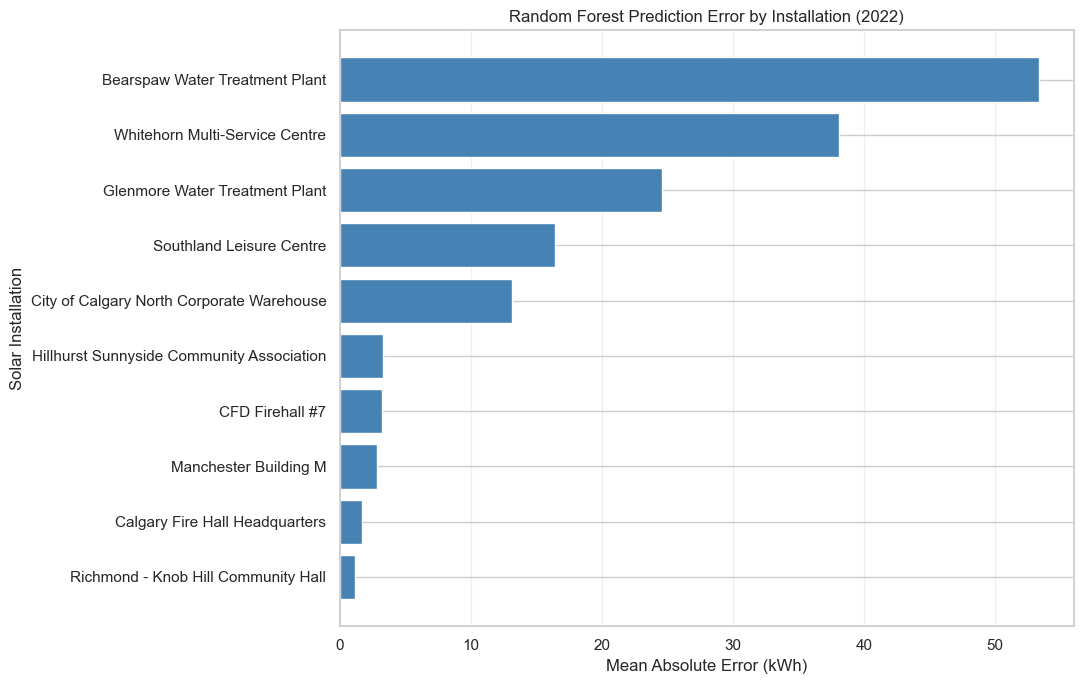

In [50]:

# Section 7.7.3 - Installation-level prediction performance

# Create a comparison dataset for 2022 observations
installation_predictions = pd.DataFrame({
    "Installation": test_df["name"].to_numpy(),
    "Actual_kWh": y_test.to_numpy(),
    "Predicted_kWh": rf_predictions
})

# Calculate prediction errors
installation_predictions["Absolute_Error"] = (
    installation_predictions["Actual_kWh"]
    - installation_predictions["Predicted_kWh"]
).abs()

installation_predictions["Squared_Error"] = (
    installation_predictions["Actual_kWh"]
    - installation_predictions["Predicted_kWh"]
) ** 2

# Calculate performance metrics for each installation
installation_performance = (
    installation_predictions
    .groupby("Installation")
    .agg(
        Observations=("Actual_kWh", "size"),
        Mean_Actual_kWh=("Actual_kWh", "mean"),
        MAE=("Absolute_Error", "mean"),
        MSE=("Squared_Error", "mean")
    )
)

# Convert MSE to RMSE
installation_performance["RMSE"] = np.sqrt(
    installation_performance["MSE"]
)

# Remove intermediate MSE column
installation_performance = installation_performance.drop(
    columns="MSE"
)

# Sort installations by MAE
installation_performance = installation_performance.sort_values(
    "MAE", ascending=False
)

print("Installation-Level Random Forest Performance (2022)")
display(installation_performance.round(3))

# Visualize installation-level MAE
plt.figure(figsize=(11, 7))

plt.barh(
    installation_performance.index,
    installation_performance["MAE"],
    color="steelblue"
)

plt.xlabel("Mean Absolute Error (kWh)")
plt.ylabel("Solar Installation")
plt.title("Random Forest Prediction Error by Installation (2022)")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretation: Installation-Level Prediction Performance**

The installation-level evaluation reveals substantial differences in the absolute prediction errors of the Random Forest model across the ten solar installations.

**Bearspaw Water Treatment Plant** recorded the highest MAE at 53.368 kWh, followed by **Whitehorn Multi-Service Centre** at 38.141 kWh and **Glenmore Water Treatment Plant** at 24.588 kWh.

In contrast, **Richmond - Knob Hill Community Hall** recorded the lowest MAE at 1.200 kWh, followed by **Calgary Fire Hall Headquarters** at 1.700 kWh.

The results suggest that installations with higher average production generally exhibit larger absolute prediction errors.

However, absolute MAE values are influenced by the scale of production. Therefore, lower MAE values at smaller installations do not necessarily indicate superior relative predictive performance.

For example, Bearspaw Water Treatment Plant has an MAE equivalent to approximately 42.5% of its mean recorded production, while Richmond - Knob Hill Community Hall has a corresponding ratio of approximately 41.7%.

These findings highlight the importance of considering installation-level production characteristics when interpreting predictive performance.

Overall, the Random Forest demonstrates varying absolute prediction errors across installations, reinforcing the need for installation-specific diagnostics rather than relying exclusively on aggregate evaluation metrics.

#### 7.7.4 Summary of Prediction Diagnostics

The prediction diagnostics provide additional insight into the performance and limitations of the Random Forest regression model.

**Key findings:**

1. **Actual versus predicted production:** The model captures general production patterns but tends to overestimate some low-production observations and underestimate some high-production observations.

2. **Residual distribution:** Prediction errors are concentrated near zero, with a mean residual of −2.553 kWh and a median residual of −0.118 kWh. However, large positive and negative residuals indicate substantial errors for certain observations.

3. **Installation-level performance:** Absolute prediction errors vary considerably across installations. Higher-output installations generally exhibit larger MAE values, emphasizing the importance of considering production scale when comparing predictive performance.

4. **Overall predictive improvement:** The Random Forest reduces MAE by approximately 32.7% and RMSE by approximately 22.2% compared with the historical-average baseline.

**Limitations:**

The model uses only installation identity and calendar-based predictors. It does not incorporate solar irradiance, weather conditions, installation capacity, or equipment performance information.

Additionally, differences in recording intervals and data-quality characteristics may influence prediction errors.

**Overall assessment:**

The Random Forest provides a meaningful improvement over the historical-average baseline on the 2022 test dataset. Nevertheless, the diagnostic results demonstrate that substantial uncertainty remains, particularly for unusual production levels and higher-output installations.

The model should therefore be considered an exploratory prediction benchmark rather than a production-ready forecasting solution.

### 7.8 Final Modeling Conclusions and Recommendations

#### 7.8.1 Summary of Modeling Results

This optional bonus extended the exploratory solar energy production analysis by developing and evaluating two prediction approaches using historical observations from 2018–2022.

The modeling dataset contained **215,651 observations across ten solar installations**. Telus Spark was excluded because it had only 25 training observations and no observations in the 2022 testing period.

A chronological train–test split was implemented:

- **Training period (2018–2021):** 172,996 observations
- **Testing period (2022):** 42,655 observations

Two prediction approaches were evaluated:

| Model | MAE (kWh) | RMSE (kWh) |
|---|---:|---:|
| Historical-average baseline | 24.004 | 45.463 |
| Random Forest Regressor | 16.166 | 35.375 |

The Random Forest reduced MAE by approximately **32.7%** and RMSE by approximately **22.2%** relative to the historical-average baseline.

These results indicate that a nonlinear regression model can improve prediction accuracy using installation identity and time-related variables.

#### 7.8.2 Key Findings

The modeling analysis produced several important findings:

1. **Temporal and installation-specific information provides predictive value.** The Random Forest achieved lower prediction errors than the historical-average baseline, suggesting that relationships involving installation identity, hour, month, and day of week contribute useful predictive information.

2. **Prediction errors vary across production levels.** The actual-versus-predicted scatterplot indicates that the model tends to overestimate some low-production observations and underestimate some high-production observations.

3. **Residual analysis reveals remaining prediction uncertainty.** Although many residuals are concentrated near zero, large positive and negative residuals demonstrate that certain production observations remain difficult to predict.

4. **Installation-level prediction performance differs.** Bearspaw Water Treatment Plant recorded the highest absolute MAE at 53.368 kWh, while Richmond - Knob Hill Community Hall recorded the lowest at 1.200 kWh. These differences should be interpreted in relation to installation production scale.

5. **Data coverage and reporting characteristics influence modeling reliability.** The exclusion of Telus Spark and the use of a chronological split demonstrate the importance of evaluating data availability before developing prediction models.

#### 7.8.3 Modeling Limitations

Despite the improvement achieved by the Random Forest, several limitations remain:

- **Limited predictor information:** Weather conditions, solar irradiance, cloud cover, and temperature were unavailable.
- **Installation differences:** Installed solar capacity and equipment characteristics were not explicitly incorporated.
- **Reporting irregularities:** Differences in recording intervals may affect the comparability of production observations.
- **Potential outliers:** Unusual production measurements may influence model performance.
- **Limited temporal validation:** Predictive performance was evaluated using a single future test year (2022).
- **Model generalizability:** The results apply to the ten installations represented in the modeling dataset and should not be assumed to generalize to other solar installations.

#### 7.8.4 Recommendations for Future Work

Future modeling improvements could include:

1. **Integrating weather data:** Incorporate solar irradiance, cloud cover, ambient temperature, and other relevant meteorological variables.
2. **Normalizing production measurements:** Where technically appropriate, account for installed capacity and differences in reporting intervals to improve comparability.
3. **Exploring additional models:** Compare Random Forest with other regression approaches, such as gradient boosting.
4. **Expanding temporal validation:** Evaluate models using multiple chronological validation periods rather than relying on a single test year.
5. **Investigating unusual observations:** Examine potential outliers and reporting anomalies to determine their influence on predictive performance.
6. **Evaluating installation-specific models:** Investigate whether separate models or additional installation-level features improve prediction accuracy.

#### 7.8.5 Overall Conclusion

The optional prediction analysis demonstrates that historical solar energy production data can support the development of useful baseline forecasting models.

Using observations from 2018–2021 to predict production in 2022, the Random Forest achieved an MAE of **16.166 kWh** and RMSE of **35.375 kWh**, outperforming the historical-average baseline on both measures.

However, the prediction diagnostics reveal persistent uncertainty, particularly for unusually low or high production values and installations with larger production scales.

The findings reinforce the conclusions of the exploratory analysis: solar energy production exhibits meaningful temporal patterns, but installation characteristics, data quality, and unobserved environmental conditions remain important considerations.

Overall, the modeling exercise provides a reproducible starting point for future solar energy prediction research while highlighting the need for richer datasets and more extensive validation before operational deployment.

 ## 8.0 Optional: Solar Energy Production Forecasting for 2024

### 8.1 Forecasting Objective and Methodology

This optional section extends the solar energy production prediction analysis by generating calendar-based forecasts for 2024 across the ten eligible photovoltaic installations.

The Random Forest model previously evaluated on the 2022 test dataset will be retrained using the available historical modeling observations from 2018–2022. This allows the final forecasting model to incorporate the most recent observations available in the selected modeling period.

The forecasting procedure will:

1. Retrain the Random Forest using historical observations from 2018–2022.
2. Generate 2024 calendar-based input features for all ten eligible installations.
3. Predict solar energy production for the generated timestamps.
4. Visualize forecasted production patterns across installations and months.
5. Discuss forecasting assumptions, limitations, and uncertainty.

**Important considerations:** The forecasts use installation identity, hour of day, month, and day of week. They do not account for actual 2024 weather conditions or changes in photovoltaic system performance. Forecasted values therefore represent expected production patterns rather than precise operational predictions.

Because the historical dataset may contain irregular reporting intervals, the forecasts will initially be interpreted as predicted recorded energy values. Annual production totals will only be considered after checking that the measurement intervals support meaningful aggregation.

### 8.2 Retraining the Random Forest for 2024 Forecasting

Following the model evaluation in Section 7, the Random Forest is retrained using the complete 2018–2022 modeling dataset.

The final forecasting model retains the same input features and hyperparameters as the previously evaluated Random Forest. However, it now includes the 2022 observations that were excluded from the original training dataset.

A separate model pipeline is created to preserve the original training–testing experiment and its evaluation results.

This retrained model will subsequently be used to generate calendar-based solar energy production forecasts for 2024 across all ten eligible installations.

In [51]:

# Section 8.2 — Retrain Random Forest using all 2018–2022 observations

from sklearn.base import clone

# Use the complete modeling dataset
X_forecast_train = model_df[feature_columns].copy()
y_forecast_train = model_df[target_column].copy()

# Clone the evaluated pipeline to preserve the original model
rf_forecast_pipeline = clone(rf_pipeline)

# Fit the final forecasting model
rf_forecast_pipeline.fit(X_forecast_train, y_forecast_train)

# Confirm the training dataset
print("Final forecasting model trained successfully.")
print(f"Training observations: {len(X_forecast_train):,}")
print(f"Installations: {model_df['name'].nunique()}")
print(
    f"Training period: "
    f"{model_df['date'].min():%Y-%m-%d} to "
    f"{model_df['date'].max():%Y-%m-%d}"
)
print(f"Input features: {feature_columns}")


Final forecasting model trained successfully.
Training observations: 215,651
Installations: 10
Training period: 2018-01-01 to 2022-12-31
Input features: ['name', 'hour', 'month', 'day_of_week']


### 8.3 Generating Forecast Input Data for 2024

To generate solar energy production forecasts for 2024, a new prediction dataset is constructed using the ten installations included in the final forecasting model.

The forecast dataset contains hourly timestamps covering January 1 through December 31, 2024, including the additional day in February because 2024 is a leap year.

For each installation and timestamp, the required prediction features are generated:

- **Installation name:** Identifies the photovoltaic installation.
- **Hour:** Represents the hour of the day.
- **Month:** Captures seasonal production patterns.
- **Day of week:** Represents weekly calendar patterns.

The resulting dataset provides a consistent hourly forecasting grid across all ten installations.

These timestamps are generated for forecasting purposes and do not represent actual recorded observations. The assumption of one prediction per hour will be considered when interpreting and aggregating forecast results.

In [52]:

# Section 8.3 — Generate hourly forecast inputs for 2024

import pandas as pd

# Identify the ten eligible solar installations
forecast_installations = sorted(model_df["name"].unique())

# Generate every hour in 2024 (leap year)
forecast_hours = pd.date_range(
    start="2024-01-01 00:00:00",
    end="2024-12-31 23:00:00",
    freq="h"
)

# Create one record for every installation and hour
forecast_2024_df = pd.MultiIndex.from_product(
    [forecast_installations, forecast_hours],
    names=["name", "date"]
).to_frame(index=False)

# Generate the same calendar features used during training
forecast_2024_df["hour"] = forecast_2024_df["date"].dt.hour
forecast_2024_df["month"] = forecast_2024_df["date"].dt.month
forecast_2024_df["day_of_week"] = forecast_2024_df["date"].dt.dayofweek

# Prepare model inputs in the original feature order
X_forecast_2024 = forecast_2024_df[feature_columns].copy()

# Validate the forecast dataset
print(f"Installations: {len(forecast_installations)}")
print(f"Hours per installation: {len(forecast_hours):,}")
print(f"Total forecast records: {len(forecast_2024_df):,}")
print(f"Forecast period: {forecast_hours.min()} to {forecast_hours.max()}")
print(f"Missing feature values: {X_forecast_2024.isna().sum().sum()}")

display(forecast_2024_df.head())


Installations: 10
Hours per installation: 8,784
Total forecast records: 87,840
Forecast period: 2024-01-01 00:00:00 to 2024-12-31 23:00:00
Missing feature values: 0


,name,date,hour,month,day_of_week
0,Bearspaw Water Treatment Plant,2024-01-01 00:00:00,0,1,0
1,Bearspaw Water Treatment Plant,2024-01-01 01:00:00,1,1,0
2,Bearspaw Water Treatment Plant,2024-01-01 02:00:00,2,1,0
3,Bearspaw Water Treatment Plant,2024-01-01 03:00:00,3,1,0
4,Bearspaw Water Treatment Plant,2024-01-01 04:00:00,4,1,0


### 8.4 Generating Solar Energy Production Forecasts for 2024

The retrained Random Forest model is applied to the 2024 forecast input dataset to estimate solar energy production for each of the ten eligible installations.

The forecasting dataset contains 87,840 installation-hour combinations, representing 8,784 hourly timestamps for each installation during the 2024 leap year.

Predictions are generated using installation identity, hour of day, month, and day of week.

The resulting forecasts are examined for completeness, numerical validity, and differences across installations. Negative predictions, if present, are set to zero because negative solar energy production is not physically meaningful for the production variable analyzed.

These forecasts represent model-estimated energy production under historical calendar patterns. They are not actual 2024 measurements, and their accuracy cannot be established without corresponding observed production data.

In [53]:

# Section 8.4 — Generate solar energy production forecasts for 2024

import numpy as np

# Predict production using the retrained Random Forest
forecast_2024_predictions = rf_forecast_pipeline.predict(
    X_forecast_2024
)

# Ensure predicted energy production is nonnegative
forecast_2024_predictions = np.maximum(
    forecast_2024_predictions, 0
)

# Store predictions in the forecast dataset
forecast_2024_df["Predicted_kWh"] = forecast_2024_predictions

# Check forecast completeness and numerical validity
print("2024 FORECAST VALIDATION")
print("-" * 45)
print(f"Total forecast records: {len(forecast_2024_df):,}")
print(f"Installations: {forecast_2024_df['name'].nunique()}")
print(
    f"Missing predictions: "
    f"{forecast_2024_df['Predicted_kWh'].isna().sum()}"
)
print(
    f"Non-finite predictions: "
    f"{(~np.isfinite(forecast_2024_predictions)).sum()}"
)
print(
    f"Negative predictions: "
    f"{(forecast_2024_df['Predicted_kWh'] < 0).sum()}"
)

print("\nPREDICTED PRODUCTION SUMMARY (kWh per forecast record)")
print(
    forecast_2024_df["Predicted_kWh"]
    .describe()
    .round(3)
)

print("\nSAMPLE FORECAST RECORDS")
display(forecast_2024_df.head(10))


2024 FORECAST VALIDATION
---------------------------------------------
Total forecast records: 87,840
Installations: 10
Missing predictions: 0
Non-finite predictions: 0
Negative predictions: 0

PREDICTED PRODUCTION SUMMARY (kWh per forecast record)
count    87840.000
mean        19.721
std         48.473
min          0.002
25%          0.054
50%          0.601
75%         11.342
max        360.006
Name: Predicted_kWh, dtype: float64

SAMPLE FORECAST RECORDS


,name,date,hour,month,day_of_week,Predicted_kWh
0,Bearspaw Water Treatment Plant,2024-01-01 00:00:00,0,1,0,0.647240
1,Bearspaw Water Treatment Plant,2024-01-01 01:00:00,1,1,0,0.641103
2,Bearspaw Water Treatment Plant,2024-01-01 02:00:00,2,1,0,0.648410
3,Bearspaw Water Treatment Plant,2024-01-01 03:00:00,3,1,0,0.653687
4,Bearspaw Water Treatment Plant,2024-01-01 04:00:00,4,1,0,0.677112
5,Bearspaw Water Treatment Plant,2024-01-01 05:00:00,5,1,0,0.599295
6,Bearspaw Water Treatment Plant,2024-01-01 06:00:00,6,1,0,0.581134
7,Bearspaw Water Treatment Plant,2024-01-01 07:00:00,7,1,0,0.490290
8,Bearspaw Water Treatment Plant,2024-01-01 08:00:00,8,1,0,1.154243
9,Bearspaw Water Treatment Plant,2024-01-01 09:00:00,9,1,0,15.531390


### 8.5 Visualizing Forecasted Solar Energy Production Patterns for 2024

This section examines the seasonal patterns in the 2024 Random Forest forecasts across all ten eligible solar installations.

Monthly mean predicted production per forecast record is calculated for each installation. Using the mean rather than the sum allows seasonal patterns to be compared without immediately assuming that all historical measurements represent consistent hourly reporting intervals.

The visualization is intended to identify seasonal production trends and differences between installations.

These results represent model-estimated production patterns, not observed 2024 electricity generation.

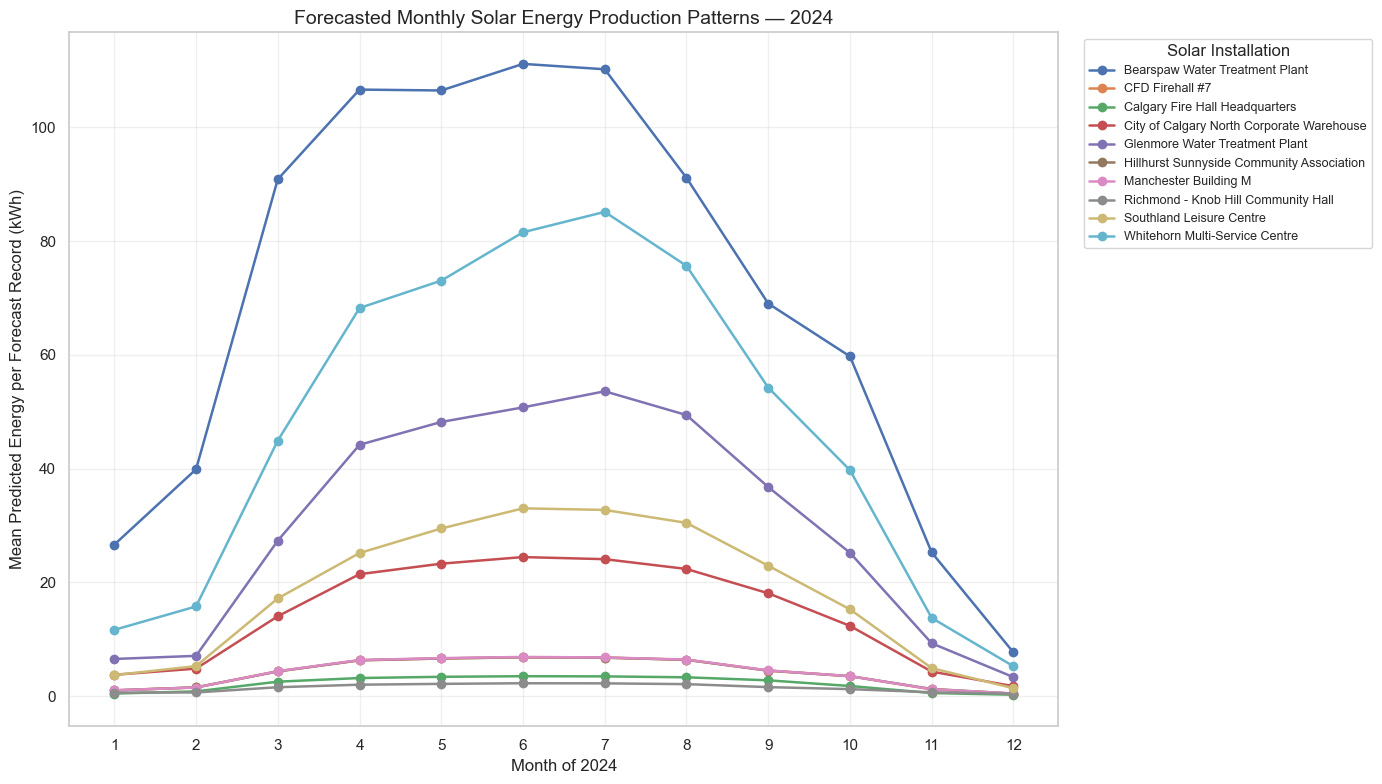

month,1,2,3,4,5,6,7,8,9,10,11,12
name,,,,,,,,,,,,
Bearspaw Water Treatment Plant,26.62,39.88,90.88,106.65,106.50,111.18,110.23,91.13,69.03,59.73,25.24,7.66
CFD Firehall #7,0.99,1.52,4.35,6.28,6.61,6.82,6.76,6.38,4.48,3.49,1.17,0.41
Calgary Fire Hall Headquarters,0.43,0.82,2.52,3.16,3.38,3.48,3.46,3.29,2.76,1.76,0.52,0.23
City of Calgary North Corporate Warehouse,3.74,4.82,14.03,21.43,23.28,24.44,24.07,22.35,18.07,12.34,4.29,1.73
Glenmore Water Treatment Plant,6.52,7.07,27.32,44.19,48.20,50.76,53.59,49.41,36.75,25.19,9.27,3.32
Hillhurst Sunnyside Community Association,0.99,1.52,4.32,6.28,6.61,6.81,6.75,6.37,4.46,3.49,1.24,0.42
Manchester Building M,1.01,1.50,4.37,6.33,6.67,6.87,6.78,6.41,4.50,3.50,1.20,0.46
Richmond - Knob Hill Community Hall,0.60,0.63,1.55,1.99,2.14,2.25,2.23,2.09,1.57,1.21,0.66,0.41
Southland Leisure Centre,3.68,5.26,17.17,25.15,29.46,33.01,32.73,30.45,22.92,15.25,4.91,1.37


In [54]:

# Section 8.5 — Visualize monthly forecast patterns for 2024

import matplotlib.pyplot as plt

# Calculate mean predicted production by installation and month
monthly_forecast_2024 = (
    forecast_2024_df
    .groupby(["name", "month"], as_index=False)
    ["Predicted_kWh"]
    .mean()
)

# Plot monthly forecasts for all ten installations
plt.figure(figsize=(14, 8))

for installation, group in monthly_forecast_2024.groupby("name"):
    plt.plot(
        group["month"],
        group["Predicted_kWh"],
        marker="o",
        linewidth=1.8,
        label=installation
    )

plt.title(
    "Forecasted Monthly Solar Energy Production Patterns — 2024",
    fontsize=14
)
plt.xlabel("Month of 2024")
plt.ylabel("Mean Predicted Energy per Forecast Record (kWh)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend(
    title="Solar Installation",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=9
)
plt.tight_layout()
plt.show()

# Display the monthly forecast summary
display(
    monthly_forecast_2024
    .pivot(
        index="name",
        columns="month",
        values="Predicted_kWh"
    )
    .round(2)
)


#### 8.5.1 Interpretation of the 2024 Monthly Forecast Patterns

The 2024 Random Forest forecasts reveal clear seasonal variation in predicted solar energy production across the ten photovoltaic installations.

**Seasonal production patterns:** Predicted production generally increases from winter into spring, reaches its highest levels during late spring or summer, and declines toward the end of the year. This pattern is consistent with the seasonal availability of solar energy in Calgary.

**Differences between installations:** Bearspaw Water Treatment Plant has the highest predicted production across all months, reaching approximately 111.18 kWh per forecast record in June. Whitehorn Multi-Service Centre and Glenmore Water Treatment Plant also exhibit comparatively high production, peaking at approximately 85.15 and 53.59 kWh per record in July, respectively.

**Lower-production installations:** Richmond - Knob Hill Community Hall and several smaller installations have substantially lower predicted production levels throughout the year. These differences may reflect installation size, equipment characteristics, or historical production patterns, although the model does not explicitly include installed capacity.

**Variation in peak production months:** While many installations reach their predicted maximum production during June or July, the exact timing and shape of the seasonal profiles vary. Bearspaw exhibits a relatively broad high-production period between April and July.

**Forecast interpretation:** The results indicate that the Random Forest has learned meaningful seasonal and installation-specific patterns from historical observations. However, the forecasts are based on calendar variables rather than actual 2024 weather conditions, so unexpected cloud cover, equipment downtime, or other operational changes are not represented.

Overall, the forecasts provide an illustrative comparison of expected 2024 production patterns across installations. They should not be interpreted as validated 2024 production measurements or precise annual energy estimates.

### 8.6 Assessing Historical Reporting Intervals Before Annual Forecast Aggregation

Although the 2024 forecasting dataset was generated at hourly intervals, the historical production dataset may not contain a complete observation for every hour.

To assess whether forecasted values can reasonably be aggregated into monthly or annual energy totals, this section examines the time intervals between consecutive historical observations for each installation.

The analysis calculates the proportion of consecutive records separated by approximately one hour, along with the most common reporting intervals.

This assessment helps determine whether the forecast outputs should be interpreted primarily as hourly energy estimates or as predicted values associated with the historical reporting structure.

In [55]:

# Section 8.6 — Assess historical reporting intervals

# Sort historical records by installation and timestamp
interval_df = model_df[["name", "date"]].copy()
interval_df = interval_df.sort_values(["name", "date"])

# Calculate time differences between consecutive observations
interval_df["Interval_Hours"] = (
    interval_df.groupby("name")["date"]
    .diff()
    .dt.total_seconds()
    .div(3600)
)

# Exclude the first observation of each installation
valid_intervals = interval_df.dropna(subset=["Interval_Hours"]).copy()

# Calculate installation-level reporting interval statistics
interval_summary = (
    valid_intervals.groupby("name")
    .agg(
        Intervals=("Interval_Hours", "count"),
        Median_Interval_Hours=("Interval_Hours", "median"),
        Mean_Interval_Hours=("Interval_Hours", "mean"),
        Percent_One_Hour=(
            "Interval_Hours",
            lambda x: 100 * x.between(0.99, 1.01).mean()
        ),
        Percent_Over_One_Hour=(
            "Interval_Hours",
            lambda x: 100 * (x > 1.01).mean()
        )
    )
    .round(2)
)

print("HISTORICAL REPORTING INTERVAL SUMMARY")
display(interval_summary)

print("\nMOST COMMON TIME INTERVALS (HOURS)")
display(
    valid_intervals["Interval_Hours"]
    .round(2)
    .value_counts()
    .head(10)
)


HISTORICAL REPORTING INTERVAL SUMMARY


,Intervals,Median_Interval_Hours,Mean_Interval_Hours,Percent_One_Hour,Percent_Over_One_Hour
name,,,,,
Bearspaw Water Treatment Plant,23298,1.0,1.88,92.38,7.62
CFD Firehall #7,21216,1.0,2.06,91.88,8.12
Calgary Fire Hall Headquarters,21559,1.0,2.03,91.73,8.27
City of Calgary North Corporate Warehouse,22170,1.0,1.98,91.89,8.11
Glenmore Water Treatment Plant,21268,1.0,2.05,91.78,8.22
Hillhurst Sunnyside Community Association,18944,1.0,2.31,91.74,8.26
Manchester Building M,21455,1.0,2.04,91.87,8.13
Richmond - Knob Hill Community Hall,21712,1.0,2.02,91.79,8.21
Southland Leisure Centre,21249,1.0,2.06,91.86,8.14



MOST COMMON TIME INTERVALS (HOURS)


Interval_Hours
1.0     198190
8.0       2336
10.0      2327
16.0      2024
12.0      1880
9.0       1689
14.0      1349
11.0      1126
15.0      1112
13.0      1081
Name: count, dtype: int64

#### 8.6.1 Interpretation of Historical Reporting Intervals

The reporting-interval assessment indicates that the historical solar production dataset is predominantly hourly but contains irregular gaps between consecutive observations.

Across all ten installations, the median interval between consecutive records is one hour. Approximately 91.7%–92.4% of consecutive observations are separated by one hour, confirming that hourly measurements represent the dominant reporting pattern.

However, the mean reporting intervals range from approximately 1.88 to 2.31 hours, indicating that longer gaps increase the average interval duration.

The most common interval is one hour, occurring 198,190 times. Longer gaps, including 8, 10, 12, and 16 hours, also appear in the historical dataset.

These gaps may reflect missing measurements, reporting practices, or periods when observations were not recorded. Their causes cannot be determined from timestamp differences alone.

**Implications for forecasting:** Although the Random Forest generates predictions on a complete hourly grid for 2024, its historical training observations are not uniformly distributed across every hour.

Consequently, summing all generated hourly predictions into annual energy totals would require an additional assumption that each predicted value represents energy generated during a corresponding one-hour interval.

For this reason, monthly mean predicted production per forecast record is retained as the primary basis for comparing seasonal patterns and installation-level differences. Annual forecast totals, if reported, should be explicitly identified as conditional estimates rather than validated production figures.

### 8.7 Installation-Level Summary of the 2024 Forecasts

To compare predicted production across the ten eligible solar installations, the 2024 forecast results are summarized at the installation level.

The analysis calculates the mean, median, minimum, and maximum predicted energy production per forecast record for each installation.

The results provide an overview of differences in predicted production magnitude and variability.

Because the historical dataset contains irregular reporting intervals, these descriptive statistics are preferred over unqualified annual energy totals.

The comparison reflects model-estimated production for 2024 rather than observed production measurements.

2024 INSTALLATION-LEVEL FORECAST SUMMARY


,Forecast_Records,Mean_Predicted_kWh,Median_Predicted_kWh,Min_Predicted_kWh,Max_Predicted_kWh
name,,,,,
Bearspaw Water Treatment Plant,8784,70.477,3.211,0.067,360.006
Whitehorn Multi-Service Centre,8784,47.503,3.305,0.026,235.849
Glenmore Water Treatment Plant,8784,30.203,1.980,0.026,144.799
Southland Leisure Centre,8784,18.485,0.928,0.002,85.402
City of Calgary North Corporate Warehouse,8784,14.574,1.205,0.018,63.082
Manchester Building M,8784,4.141,0.313,0.004,17.332
CFD Firehall #7,8784,4.114,0.301,0.003,17.332
Hillhurst Sunnyside Community Association,8784,4.112,0.309,0.003,17.332
Calgary Fire Hall Headquarters,8784,2.156,0.152,0.003,9.613


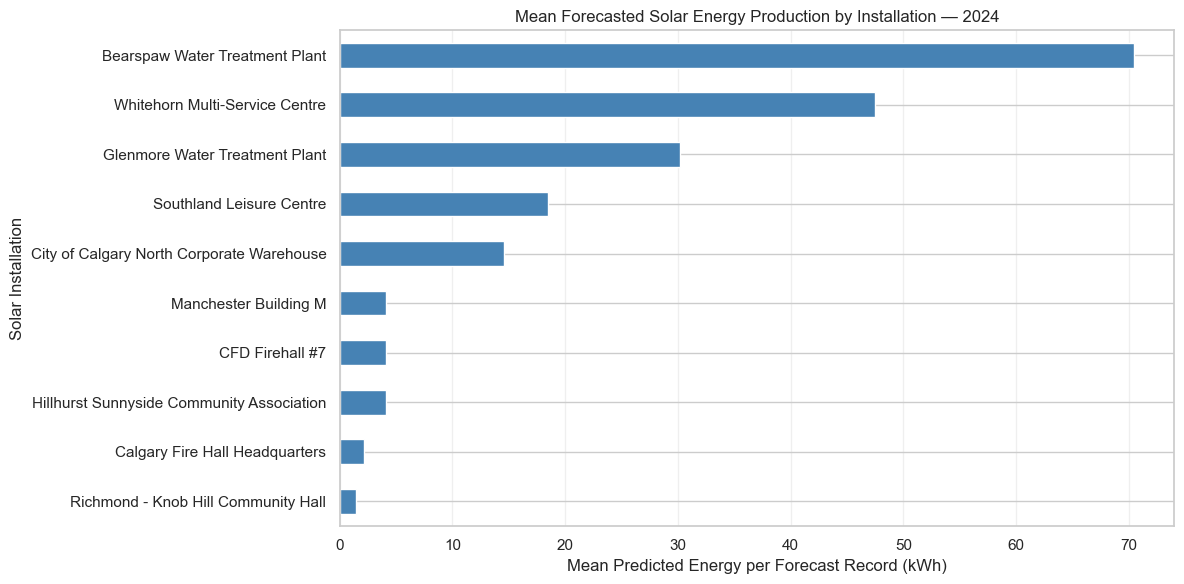

In [56]:

# Section 8.7 — Summarize 2024 forecasts by installation

installation_forecast_summary = (
    forecast_2024_df
    .groupby("name")["Predicted_kWh"]
    .agg(
        Forecast_Records="count",
        Mean_Predicted_kWh="mean",
        Median_Predicted_kWh="median",
        Min_Predicted_kWh="min",
        Max_Predicted_kWh="max"
    )
    .sort_values("Mean_Predicted_kWh", ascending=False)
    .round(3)
)

print("2024 INSTALLATION-LEVEL FORECAST SUMMARY")
display(installation_forecast_summary)

# Visualize the mean predicted production for each installation
plt.figure(figsize=(12, 6))

installation_forecast_summary[
    "Mean_Predicted_kWh"
].sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title(
    "Mean Forecasted Solar Energy Production by Installation — 2024"
)
plt.xlabel("Mean Predicted Energy per Forecast Record (kWh)")
plt.ylabel("Solar Installation")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


#### 8.7.1 Interpretation of Installation-Level Forecast Results

The 2024 installation-level forecast summary reveals substantial differences in predicted solar energy production across the ten photovoltaic installations.

**Highest predicted production:** Bearspaw Water Treatment Plant ranks first, with a mean predicted production of 70.477 kWh per forecast record and a maximum predicted value of 360.006 kWh. Whitehorn Multi-Service Centre follows with a mean of 47.503 kWh, while Glenmore Water Treatment Plant ranks third with 30.203 kWh.

**Intermediate predicted production:** Southland Leisure Centre and City of Calgary North Corporate Warehouse have mean predicted production values of 18.485 kWh and 14.574 kWh per record, respectively.

**Lowest predicted production:** Richmond - Knob Hill Community Hall has the lowest mean predicted production at 1.446 kWh per record, followed by Calgary Fire Hall Headquarters at 2.156 kWh.

**Differences in production magnitude:** Bearspaw's predicted mean production is approximately 49 times that of Richmond - Knob Hill Community Hall. This difference may reflect installation size, equipment characteristics, or historical operating conditions. However, the model does not explicitly include installed capacity, so the results cannot establish which installation is more efficient.

**Distribution of predicted production:** For every installation, the median predicted value is substantially lower than the mean, indicating positively skewed production distributions. This is consistent with many low-production hours and fewer periods of relatively high solar output.

**Forecasting limitations:** The results are based on calendar features and historical observations rather than actual 2024 environmental or operational conditions. Consequently, the forecasts should be interpreted as estimates of expected production patterns, not verified measurements.

Overall, the installation-level analysis demonstrates that the Random Forest captures differences in historical production magnitude across the ten installations while preserving the seasonal patterns identified in the monthly forecasts.

### 8.8 Final Conclusions and Limitations of the 2024 Forecast

This optional section extended the solar energy production analysis by generating calendar-based forecasts for 2024 across ten photovoltaic installations.

A Random Forest model was retrained using 215,651 historical observations from 2018–2022. The model then generated 87,840 predictions, corresponding to 8,784 hourly timestamps for each installation during the 2024 leap year.

#### 8.8.1 Key Forecasting Findings

The forecast analysis produced the following findings:

1. **Seasonal patterns:** Predicted production generally increases during spring, reaches its highest levels in late spring or summer, and decreases during autumn and winter.
2. **Installation differences:** Bearspaw Water Treatment Plant has the highest mean predicted production at 70.477 kWh per forecast record, followed by Whitehorn Multi-Service Centre at 47.503 kWh and Glenmore Water Treatment Plant at 30.203 kWh.
3. **Lower-production installations:** Richmond - Knob Hill Community Hall has the lowest mean predicted production at 1.446 kWh per forecast record.
4. **Forecast completeness:** All 87,840 predictions were successfully generated without missing, non-finite, or negative values.
5. **Historical reporting characteristics:** Approximately 91.7%–92.4% of consecutive historical observations are separated by one hour, while longer gaps occur in the remaining intervals.

#### 8.8.2 Forecasting Limitations

Several limitations should be considered when interpreting these results:

- The model does not include actual 2024 weather conditions, solar irradiance, cloud cover, or temperature.
- Installation capacity, equipment condition, maintenance, and system modifications are not explicitly modeled.
- Historical observations contain irregular reporting gaps, which complicate the interpretation of complete hourly forecast totals.
- The model was evaluated on the 2022 holdout dataset, but its 2024 predictions have not been validated against actual 2024 production records.
- Calendar-based forecasts cannot capture unexpected operational disruptions or unusual weather events.
- Small positive predictions during nighttime hours reflect model limitations and should not be interpreted as verified nighttime solar generation.

#### 8.8.3 Recommendations for Future Forecasting Improvements

Future work should prioritize incorporating weather and solar irradiance data, validating predictions against actual 2024 production measurements, investigating reporting gaps, and incorporating installation capacity where available.

Additional chronological validation periods and alternative forecasting models could also improve the assessment of predictive reliability.

#### 8.8.4 Overall Conclusion

The 2024 forecasting exercise demonstrates how a Random Forest model trained on historical solar energy production data can generate expected seasonal and installation-specific production patterns.

The results provide a useful exploratory forecasting extension to the original analysis. However, they should not be interpreted as verified 2024 energy production or precise annual generation estimates.

The primary contribution of this section is to demonstrate a reproducible forecasting workflow while identifying the data-quality and modeling improvements needed for more reliable operational solar energy forecasting.